### init

In [4]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = ""
os.environ["JAX_PLATFORMS"] = "cpu"

import wandb
from tqdm import tqdm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import wandb
from IPython.display import display

n_seg_name = r"$N_{\mathrm{seg}}$"
n_name = r"$N$"
seg_deg_name = r"$(m+1)$"
free_model_name = "FLC"
pretrained_model_name = "ALC"
rho_name = r'$\rho$'

%load_ext autoreload
%autoreload 2

In [5]:
def get_figsize(columnwidth, wf=0.5, hf=(5.**0.5-1.0)/2.0, ):
    """Parameters:
    - wf [float]:  width fraction in columnwidth units
    - hf [float]:  height fraction in columnwidth units.
                    Set by default to golden ratio.
    - columnwidth [float]: width of the column in latex. Get this from LaTeX 
                            using \showthe\columnwidth
    Returns:  [fig_width,fig_height]: that should be given to matplotlib
    """
    fig_width_pt = columnwidth*wf
    inches_per_pt = 1.0/72.27               # Convert pt to inch
    fig_width = fig_width_pt*inches_per_pt  # width in inches
    fig_height = fig_width*hf      # height in inches
    return [fig_width, fig_height]


# fig_width_pt = 234.8  # Get this from LaTeX using \showthe\columnwidth
fig_width_pt = 397.48499  # Get this from LaTeX using \showthe\columnwidth
inches_per_pt = 1.0/72.27               # Convert pt to inches
golden_mean = (np.sqrt(5)-1.0)/2.0         # Aesthetic ratio
fig_width = fig_width_pt*inches_per_pt  # width in inches
fig_height = fig_width*golden_mean       # height in inches
figsize = [fig_width, fig_height]
print("Figure size=", figsize)
tex_fonts = {
    # Use LaTeX to write all text
    "text.usetex": True,
    # "text.latex.preamble": r"\usepackage{amsmath}",  # This provides \text{}
    # "text.latex.preamble": r'\usepackage{amsfonts}',
    "font.family": "Nimbus Sans",
    # Use 10pt font in plots, to match 10pt font in document
    "axes.labelsize": 10,
    "font.size": 10,
    # Make the legend/label fonts a little smaller
    "legend.fontsize": 9,
    "legend.title_fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.figsize": figsize
}
plt.rcParams.update(tex_fonts)

Figure size= [5.499999861629998, 3.399186852607058]


In [6]:
def export_standalone_legend(handles, labels, title, filename, **kwargs):
    # Create a tiny, empty figure
    fig_leg = plt.figure(figsize=(.1, 0.1)) 
    
    # Draw the legend
    fig_leg.legend(handles, labels, loc='center',
                   frameon=False, title=title, **kwargs)
    fig_leg.tight_layout()
    
    # Save it
    fig_leg.savefig(filename, bbox_inches='tight', pad_inches=0.01)
    plt.close(fig_leg)
    return None

### Load sampling results

In [7]:
from pathlib import Path

sampling_files = [
    "result/sampling/wino_m_psmile.csv",
    "result/sampling/wino_m_sghmc.csv",
    "result/sampling/wino_s_psmile.csv",
    "result/sampling/wino_s_sghmc.csv",
    "result/sampling/lora_obqa_psmile_replications.csv",
    "result/sampling/lora_arc_easy_psmile_replications.csv",
    "result/sampling/lora_arc_chall_psmile_replications.csv",
]

rows = []
for file_path in sampling_files:
    df_s = pd.read_csv(file_path)

    # Determine dataset and selection logic
    fname = Path(file_path).name
    if "obqa" in fname:
        dataset = "obqa"
        step_size = 0.0005
    elif "arc_easy" in fname:
        dataset = "ARC-Easy"
        step_size = 0.0005
    elif "arc_chall" in fname:
        dataset = "ARC-Challenge"
        step_size = 0.0005
    else:
        # Original logic for winogrande files
        dataset = "winogrande_m" if "wino_m" in file_path else "winogrande_s"
        ref = df_s[df_s["rng"] == 400]
        if ref.empty:
            print(f"Skipping {file_path}: no rng=400 row found")
            continue
        step_size = ref.iloc[0]["training_sampler_step_size"]

    # Filter by the chosen step size
    df_sel = df_s[df_s["training_sampler_step_size"] == step_size].copy()

    # Build the same core structure used in our extracted dataframe
    for _, r in df_sel.iterrows():
        rows.append(
            {
                "Id": str(r.get("experiment", Path(file_path).stem)),
                "CurveSpace": -1,
                "CpFix": "sampling",
                "NumPretrained": -1,
                "Jitter": -1,
                "Seed": int(r.get("rng", -1)) if pd.notna(r.get("rng", np.nan)) else -1,
                "WeightDecay": -1,
                "Dataset": dataset,
                "BmaMode": "Sampling",
                "DS_Sampling": str(r.get("training_sampler_name", "noisysmile")),
                "DS_Mode": "sampler",
                "DS_WindowSize": -1,
                "EntropyMaxScale": -1,
                "NumSteps": -1,
                "LoraMode": "Sampling",
                "CurveMode": "Sampling",
                "LoraRank": -1,
                "RegularizationMode": False,
                "Gravity": -1,
                "EnergyWeakening": -1,
                "Tsample": "sampling",
                "LoraRho": -1,
                "LoraRhoS": -1,
                "RhoFrequency": -1,
                "CurveSegmentDegree": -1,
                "NCurveSegment": 0,
                "OpenEndSegment": False,
                "bezierLength": 0,
                "acc": r.get("PredPerf_sampling_bma_accuracy", np.nan),
                "ece": r.get("Calibration_sampling_calibration_error", np.nan),
                "ll": r.get("LPPD_sampling_LPPD", np.nan),
                "test_mean_entropy_ppd": np.nan,
                "test_mutual_information_ppd": np.nan,
                "test_std_entropy_along_curve": np.nan,
                "test_mean_entropy_along_curve": np.nan,
                "Method": str(r.get("training_sampler_name", "noisysmile")),
                "SamplerStepSize": step_size,
                "SourceFile": fname,
            }
        )

    print(f"{fname}: target_step_size={step_size}, rows_kept={len(df_sel)}")

df_sampling = pd.DataFrame(rows)

out_path = "result/sampling/sampling_merged_stepfiltered.csv"
df_sampling.to_csv(out_path, index=False)
print(f"Saved merged sampling dataframe to {out_path} with {len(df_sampling)} rows")

df_sampling = df_sampling.melt(
    id_vars=[c for c in df_sampling.columns if c not in ["acc", "ll", "ece"]],
    value_vars=["acc", "ll", "ece"],
    var_name="Metric",
    value_name="value",
)
df_sampling.dropna(subset=['value'], inplace=True)

def get_sampling_model_name(m):
    if m == "noisysmile" or "noisysmile" in str(m):
        return "Sampling-PSMILE"
    return "Sampling-SGHMC"

df_sampling["Model"] = df_sampling["Method"].apply(get_sampling_model_name)
df_sampling["NCurveSegment"] = 0

# fix ARC-Challenge dataset ll values (they are all -inf due to a logging bug, but we know they should be around -1.5 to -2.0 based on other datasets and sanity checks)
arc_challenge_mask = (df_sampling["Dataset"] == "ARC-Challenge") & (df_sampling["Metric"] == "ll")
df_sampling.loc[arc_challenge_mask, "value"] -= 0.02  # Set to -0.2 as 8 dps were missing

df_sampling.head()

wino_m_psmile.csv: target_step_size=0.0001, rows_kept=5
wino_m_sghmc.csv: target_step_size=5e-06, rows_kept=5
wino_s_psmile.csv: target_step_size=0.01, rows_kept=5
wino_s_sghmc.csv: target_step_size=0.0001, rows_kept=5
lora_obqa_psmile_replications.csv: target_step_size=0.0005, rows_kept=8
lora_arc_easy_psmile_replications.csv: target_step_size=0.0005, rows_kept=8
lora_arc_chall_psmile_replications.csv: target_step_size=0.0005, rows_kept=5
Saved merged sampling dataframe to result/sampling/sampling_merged_stepfiltered.csv with 41 rows


,Id,CurveSpace,CpFix,NumPretrained,Jitter,Seed,WeightDecay,Dataset,BmaMode,DS_Sampling,...,test_mean_entropy_ppd,test_mutual_information_ppd,test_std_entropy_along_curve,test_mean_entropy_along_curve,Method,SamplerStepSize,SourceFile,Metric,value,Model
0,lora_wino_m_div5_20260320-063059,-1,sampling,-1,-1,40,-1,winogrande_m,Sampling,noisysmile,...,NaN,NaN,NaN,NaN,noisysmile,0.0001,wino_m_psmile.csv,acc,0.830833,Sampling-PSMILE
1,lora_wino_m_div5_20260320-051752,-1,sampling,-1,-1,20,-1,winogrande_m,Sampling,noisysmile,...,NaN,NaN,NaN,NaN,noisysmile,0.0001,wino_m_psmile.csv,acc,0.831667,Sampling-PSMILE
2,lora_wino_m_div5_20260320-074403,-1,sampling,-1,-1,400,-1,winogrande_m,Sampling,noisysmile,...,NaN,NaN,NaN,NaN,noisysmile,0.0001,wino_m_psmile.csv,acc,0.835000,Sampling-PSMILE
3,lora_wino_m_div5_20260320-040549,-1,sampling,-1,-1,2,-1,winogrande_m,Sampling,noisysmile,...,NaN,NaN,NaN,NaN,noisysmile,0.0001,wino_m_psmile.csv,acc,0.832500,Sampling-PSMILE
4,lora_wino_m_div5_2_20260317-211143,-1,sampling,-1,-1,1,-1,winogrande_m,Sampling,noisysmile,...,NaN,NaN,NaN,NaN,noisysmile,0.0001,wino_m_psmile.csv,acc,0.838333,Sampling-PSMILE


### Load ScalaBL rerun

In [8]:
import jax
api = wandb.Api()
scalabl_rows = []
for run in tqdm(api.runs("ddold/ScalaBL-Qwen7B-id"), desc="ScalaBL from W&B"):
    if run.state != "finished":
        continue
    dataset = run.config.get("dataset")
    if dataset is None:
        continue

    acc = run.summary.get("final_val_acc", np.nan)
    ece = run.summary.get("final_val_ece", np.nan)
    nll = run.summary.get("final_val_nll", np.nan)
    brier = run.summary.get("final_val_brier", np.nan)
    ll = -nll if pd.notna(nll) else np.nan

    scalabl_rows.append({"Dataset": dataset, "Metric": "acc", "Model": "ScalaBL", "value": acc, "NCurveSegment": 0, "Seed": run.config.get("seed", -1)})
    scalabl_rows.append({"Dataset": dataset, "Metric": "ece", "Model": "ScalaBL", "value": ece, "NCurveSegment": 0, "Seed": run.config.get("seed", -1)})
    scalabl_rows.append({"Dataset": dataset, "Metric": "ll", "Model": "ScalaBL", "value": ll, "NCurveSegment": 0, "Seed": run.config.get("seed", -1)})
    scalabl_rows.append({"Dataset": dataset, "Metric": "brier", "Model": "ScalaBL", "value": brier, "NCurveSegment": 0, "Seed": run.config.get("seed", -1)})

for run in tqdm(api.runs("ddold/BLoB-Qwen2.5-7B-id"), desc="BLoB from W&B"):
    if run.state != "finished":
        continue
    dataset = run.config.get("dataset")
    if dataset is None:
        continue

    acc = run.summary.get("final_val_acc", np.nan)
    ece = run.summary.get("final_val_ece", np.nan)
    nll = run.summary.get("final_val_nll", np.nan)
    brier = run.summary.get("final_val_brier", np.nan)
    ll = -nll if pd.notna(nll) else np.nan

    scalabl_rows.append({"Dataset": dataset, "Metric": "acc", "Model": "BLoB", "value": acc, "NCurveSegment": 0, "Seed": run.config.get("seed", -1)})
    scalabl_rows.append({"Dataset": dataset, "Metric": "ece", "Model": "BLoB", "value": ece, "NCurveSegment": 0, "Seed": run.config.get("seed", -1)})
    scalabl_rows.append({"Dataset": dataset, "Metric": "ll", "Model": "BLoB", "value": ll, "NCurveSegment": 0, "Seed": run.config.get("seed", -1)})
    scalabl_rows.append({"Dataset": dataset, "Metric": "brier", "Model": "BLoB", "value": brier, "NCurveSegment": 0, "Seed": run.config.get("seed", -1)})


ref_acc = {
    'winogrande_s':  {'MLE': 78.86, 'MAP': 78.94, 'BLoB_p': 78.66, 'ScalaBL_p': 78.64},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98, 'BLoB_p': 89.53, 'ScalaBL_p': 90.16},
    'ARC-Easy':      {'MLE': 95.60, 'MAP': 95.73, 'BLoB_p': 96.54, 'ScalaBL_p': 96.26},
    'winogrande_m':  {'MLE': 82.30, 'MAP': 82.09, 'BLoB_p': 82.30, 'ScalaBL_p': 81.42},
    'obqa':          {'MLE': 92.25, 'MAP': 91.72, 'BLoB_p': 91.72, 'ScalaBL_p': 90.90},
    'boolq':         {'MLE': 89.06, 'MAP': 89.04, 'BLoB_p': 89.05, 'ScalaBL_p': 88.48},
}
# Reference NLL values (our ll = -nll, so ref_ll = -ref_nll)
ref_nll = {
    'boolq':         {'MLE': 0.25, 'MAP': 0.25, 'BLoB_p': 0.23, 'ScalaBL_p': 0.24},
    'ARC-Easy':      {'MLE': 0.44, 'MAP': 0.43, 'BLoB_p': 0.10, 'ScalaBL_p': 0.11},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.05, 'BLoB_p': 0.30, 'ScalaBL_p': 0.31},
    'obqa':          {'MLE': 0.38, 'MAP': 0.39, 'BLoB_p': 0.21, 'ScalaBL_p': 0.23},
    'winogrande_s':  {'MLE': 1.94, 'MAP': 1.88, 'BLoB_p': 0.51, 'ScalaBL_p': 0.51},
    'winogrande_m':  {'MLE': 1.20, 'MAP': 1.27, 'BLoB_p': 0.39, 'ScalaBL_p': 0.40},
}
# Reference ECE values (in %, divide by 100)
ref_ece = {
    'winogrande_s':  {'MLE': 20.14, 'MAP': 19.99, 'BLoB_p': 7.88,  'ScalaBL_p': 8.88},
    'ARC-Challenge': {'MLE': 10.11, 'MAP': 10.54, 'BLoB_p': 4.03,  'ScalaBL_p': 5.03},
    'ARC-Easy':      {'MLE': 4.17,  'MAP': 4.08,  'BLoB_p': 1.60,  'ScalaBL_p': 1.78},
    'winogrande_m':  {'MLE': 16.10, 'MAP': 16.42, 'BLoB_p': 5.08,  'ScalaBL_p': 3.64},
    'obqa':          {'MLE': 6.40,  'MAP': 6.61,  'BLoB_p': 2.16,  'ScalaBL_p': 2.43},
    'boolq':         {'MLE': 3.79,  'MAP': 3.81,  'BLoB_p': 1.40,  'ScalaBL_p': 1.96},
}
ref_map = {
    'acc': jax.tree.map(lambda v: v / 100, ref_acc),  # convert % to [0,1]
    'll':  jax.tree.map(lambda v: -v, ref_nll),       # ll = -nll
    'ece': jax.tree.map(lambda v: v / 100, ref_ece),
}
metric_order = ['acc', 'll', 'ece']
df_vi_paper = pd.DataFrame([
        {'Dataset': ds, 'Metric': metric, 'Model': model, 'value': ref_map[metric][ds][model], 'NCurveSegment': 0}
        for ds in ref_acc.keys() for metric in metric_order for model in ['BLoB_p', 'ScalaBL_p']
    ])

df_vi = pd.DataFrame(scalabl_rows)
df_vi.head()


BLoB from W&B: 100%|██████████| 48/48 [00:00<00:00, 38694.33it/s]


,Dataset,Metric,Model,value,NCurveSegment,Seed
0,winogrande_s,acc,ScalaBL,0.793513,0,0
1,winogrande_s,ece,ScalaBL,0.079228,0,0
2,winogrande_s,ll,ScalaBL,-0.511719,0,0
3,winogrande_s,brier,ScalaBL,0.302734,0,0
4,winogrande_s,acc,ScalaBL,0.785601,0,7


### Collect all bezier segments data

We run Modeconnected exp with A(t)B(t) and [1,0,0,1,0, 0,1] fixed control points. 
Then the pretrainedd models are used as DE members and compared against curve training with these fixed control points

In [41]:
import wandb
from tqdm import tqdm
from copy import deepcopy
import numpy as np

api = wandb.Api()
results = []


for s in set(["w0kaq8i0", 'we8wq8n7', 'solftkne', 'kru2lo9d' ]): # + flat lora winogrande_m training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC_newDS/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        mp = run.config['model_params']
        opt_conf = run.config['optimizer_conf']
        hp = run.config['train_hyper']
        lora = mp['lora_params']

        NCurveSegment = mp['num_curve_segment']
        CurveDegree = mp['SegDeg']
        res = dict(Id=run.id,
        #    CurveSpace=f"{mp['k']}",
            # CurveSpace=len(mp['cp_fix']),
            CurveSpace=NCurveSegment * CurveDegree,
            # CpFix=str(mp['cp_fix']),
            NumPretrained=NCurveSegment + 1 if mp['Pretraining'] else 0,
            Jitter=mp['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=opt_conf['kwargs']['weight_decay'],
            Dataset="_".join(run.config['data']['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            BmaMode="PPD",
            DS_Sampling=list(hp.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(hp['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=hp['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=mp.get('entropy_maxim', -1),
            NumSteps=hp.get('num_steps', -1),
            LoraMode=lora.get('lora_mode', 'None'),
            CurveMode=mp.get('curve_parameterization', 'Bezier'),
            LoraRank=lora.get('r', -1),
            RegularizationMode=mp.get('regularizer', False),
            Gravity=mp.get('gravity', 0.),
            EnergyWeakening=mp.get('energy_weakening', 0.),
            Tsample=mp.get('curve_sampling_mode', 'None'),
            LoraRho=lora.get('lora_rho', -1),
            LoraRhoS=lora.get('lora_rho_s', -1),
            RhoFrequency=lora.get('rho_scheduler_frequency', 0),
            CurveSegmentDegree=CurveDegree,
            NCurveSegment=NCurveSegment,
            OpenEndSegment=mp.get('independent_connected', False),
            N=NCurveSegment + 1,
            M=CurveDegree - 1,
            N_cps = NCurveSegment * CurveDegree + 1,
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"test_ppd_acc", -np.inf),
            ece=run.summary.get(f"test_ppd_ece", -np.inf),
            ll=run.summary.get(f"test_ppd_ll", -np.inf),
            brier=run.summary.get(f"test_ppd_brier", -np.inf),
            test_mean_entropy_ppd=run.summary.get(f"test_ppd_weighted_mean_entropy", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_ppd_weighted_mutual_information", -np.inf),
            test_std_entropy_along_curve=0,
            test_mean_entropy_along_curve=0,
            )
        results.append(res)
        if mp['Pretraining']:
            # add DE   
            _res = deepcopy(res)
            _res['BmaMode'] = "DE"
            _res['acc'] = run.summary.get(f"test_DE_acc", -np.inf)
            _res['ece'] = run.summary.get(f"test_DE_ece", -np.inf)
            _res['ll'] = run.summary.get(f"test_DE_ll", -np.inf)
            _res['brier']=run.summary.get(f"test_DE_brier", -np.inf)
            _res['test_mean_entropy_ppd']=run.summary.get(f"test_DE_uniform_mean_entropy", -np.inf)
            _res['test_mutual_information_ppd']=run.summary.get(f"test_DE_uniform_mutual_information", -np.inf)
            _res['test_std_entropy_along_curve']=run.summary.get(f"test_DE_uniform_std_entropy_along_curve", -np.inf)
            _res['test_mean_entropy_along_curve']=run.summary.get(f"test_DE_uniform_mean_entropy_along_curve", -np.inf)
            results.append(_res)
            for k in run.summary.keys():
                if k.startswith("cp_fixed_") and k.endswith("_test_acc"):
                    i = k.split("_")[2]
                    _res = deepcopy(res)
                    _res['BmaMode'] = "MAP"
                    # print(run.summary.get(f"cp_fixed_{i}_test_acc", -np.inf))
                    _res['acc'] = run.summary.get(f"cp_fixed_{i}_test_acc", -np.inf)
                    _res['ece'] = run.summary.get(f"cp_fixed_{i}_test_ece", -np.inf)
                    _res['ll'] = run.summary.get(f"cp_fixed_{i}_test_ll", -np.inf)
                    _res['brier']=run.summary.get(f"cp_fixed_{i}_test_brier", -np.inf)
                    _res['test_mean_entropy_ppd']=run.summary.get(f"cp_fixed_{i}_test_entropy", -np.inf)
                    _res['test_mutual_information_ppd']=0
                    _res['test_std_entropy_along_curve']=0
                    _res['test_mean_entropy_along_curve']=0
                    # print(_res['acc'], _res['ece'], _res['ll'])
                    results.append(_res)

        # add PPD uniform   
        _res = deepcopy(res)
        _res['BmaMode'] = "PPD Uniform"
        _res['acc'] = run.summary.get(f"test_ppd_uniform_acc", -np.inf)
        _res['ece'] = run.summary.get(f"test_ppd_uniform_ece", -np.inf)
        _res['ll'] = run.summary.get(f"test_ppd_uniform_ll", -np.inf)
        _res['brier']=run.summary.get(f"test_ppd_uniform_brier", -np.inf)
        _res['test_mean_entropy_ppd']=run.summary.get(f"test_ppd_uniform_mean_entropy", -np.inf)
        _res['test_mutual_information_ppd']=run.summary.get(f"test_ppd_uniform_mutual_information", -np.inf)
        _res['test_std_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_std_entropy_along_curve", -np.inf)
        _res['test_mean_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_mean_entropy_along_curve", -np.inf)
        results.append(_res)
 
df = pd.DataFrame(results)
df.describe().T

w0kaq8i0:   0%|          | 0/200 [00:00<?, ?it/s, dazzling-sweep-200]

solftkne: 100%|██████████| 75/75 [00:00<00:00, 273.34it/s, fiery-sweep-1]      
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/numpy/lib/function_base.py:4655: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


,count,mean,std,min,25%,50%,75%,max
CurveSpace,2910.0,9.965636e+00,7.180733e+00,2.000000e+00,4.000000,8.000000,16.000000,24.000000
NumPretrained,2910.0,5.054983e+00,3.267137e+00,0.000000e+00,3.000000,5.000000,9.000000,9.000000
Jitter,2910.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000
Seed,2910.0,1.684600e+03,3.161904e+03,1.000000e+00,2.000000,20.000000,400.000000,8000.000000
WeightDecay,2910.0,1.000000e-03,4.337554e-19,1.000000e-03,0.001000,0.001000,0.001000,0.001000
DS_WindowSize,2910.0,-1.000000e+00,0.000000e+00,-1.000000e+00,-1.000000,-1.000000,-1.000000,-1.000000
EntropyMaxScale,2910.0,-1.000000e+00,0.000000e+00,-1.000000e+00,-1.000000,-1.000000,-1.000000,-1.000000
NumSteps,2910.0,1.000000e+04,0.000000e+00,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000
LoraRank,2910.0,8.000000e+00,0.000000e+00,8.000000e+00,8.000000,8.000000,8.000000,8.000000
Gravity,2910.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000


In [42]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [24 12  6  3 16  8  4  2]
NumPretrained [0 9 5 3 2]
Jitter [0]
Seed [8000  400   20    2    1]
WeightDecay [0.001]
Dataset ['ARC-Easy' 'ARC-Challenge' 'winogrande_s' 'obqa' 'winogrande_m' 'boolq']
BmaMode ['PPD' 'PPD Uniform' 'DE' 'MAP']
DS_Sampling ['minibatch']
DS_Mode ['classic']
DS_WindowSize [-1]
EntropyMaxScale [-1]
NumSteps [10000]
LoraMode ['A(t)eB(t)']
CurveMode ['bezier']
LoraRank [8]
RegularizationMode [False]
Gravity [0]
EnergyWeakening [1]
Tsample ['combined_all']
LoraRho [0.25]
LoraRhoS [0]
RhoFrequency [50]
CurveSegmentDegree [3 2 1]
NCurveSegment [8 4 2 1]
OpenEndSegment [False]
N [9 5 3 2]
M [2 1 0]
N_cps [25 13  7  4 17  9  5  3]

Experiment differs in ['CurveSpace', 'NumPretrained', 'Dataset', 'BmaMode', 'CurveSegmentDegree', 'NCurveSegment', 'N', 'M', 'N_cps'] configs


array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

### pre analyse

In [39]:
# Build Config label
df_subset = df_clean.copy()

df_plot = df_subset.melt(id_vars=idx_ids, value_vars=value_ids, var_name='Metric', value_name='value')
# df_plot['Config'] = df_plot.apply(lambda r: f"fix={r['NumPretrained']}, k={r['CurveSpace']}, SegDeg={r['CurveSegmentDegree']}, N_Seg={r['NCurveSegment']}, rho={r['LoraRho']}, Mode={r['LoraMode']}/{r['CurveMode']}", axis=1)
# df_plot['Config'] = df_plot.apply(lambda r: " | ".join([f"{k}={r[k]}" for k in variable_idx if k not in ['CurveSpace', 'NCurveSegment', 'NumPretrained', 'Dataset', 'BmaMode',]]), axis=1)
df_plot['Config'] = df_plot.apply(lambda r: " | ".join([f"{k}={r[k]}" for k in variable_idx if k not in ['Dataset', 'BmaMode',]]), axis=1)

col_order = df_subset['Dataset'].unique()
col_order.sort()


/tmp/ipykernel_1623721/918552579.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1623721/918552579.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1623721/918552579.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1623721/918552579.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1623721/918552579.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


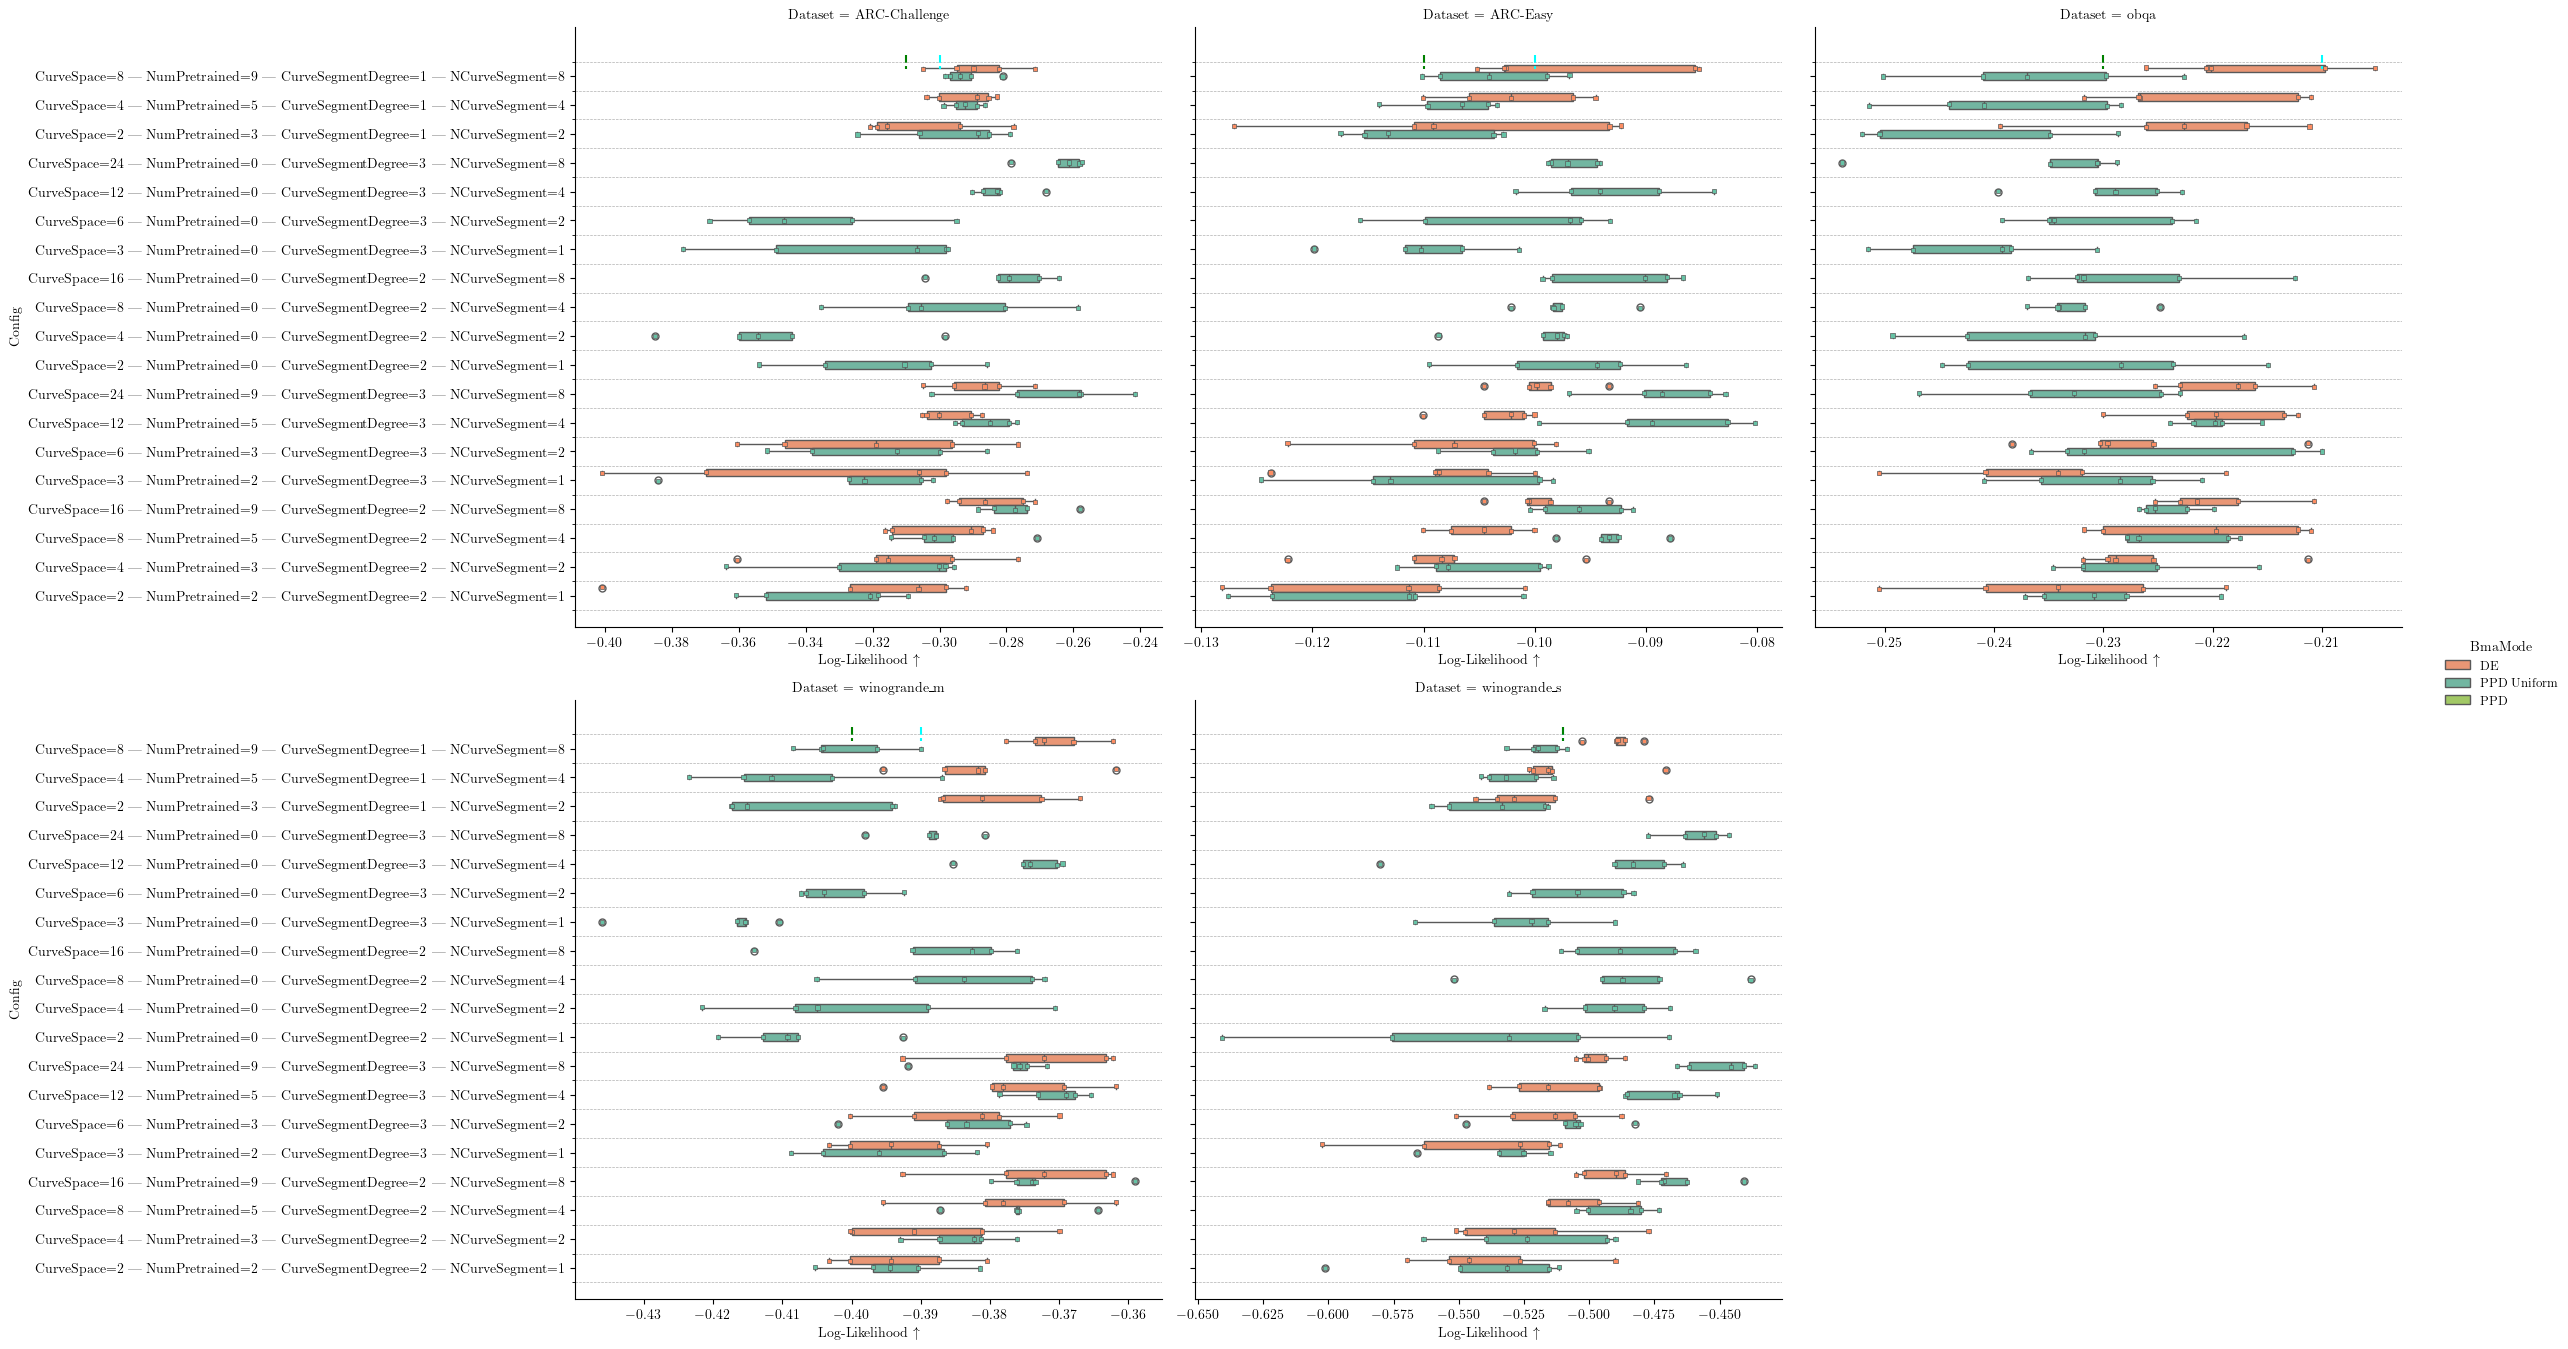

In [40]:
# Filters
df_plot = df_plot[(df_plot['BmaMode'] != 'PPD') & (df_plot['Metric'] == 'll')]

hue_order = ['DE', 'PPD Uniform', 'PPD']
cmap = sns.color_palette("Set2")
hue_palette = {'DE': cmap[1], 'PPD Uniform': cmap[0], 'PPD': cmap[4]}

g = sns.catplot(
    data=df_plot, y='Config', x='value', hue='BmaMode', kind='box',
    col='Dataset', palette=hue_palette, col_wrap=3,
    height=figsize[1] * 2, col_order=col_order,
    hue_order=hue_order, aspect=1.2, sharex=False
)

# Overlay strip plots
for ds, ax in g.axes_dict.items():
    sns.stripplot(
        data=df_plot[df_plot['Dataset'] == ds],
        y='Config', x='value', hue='BmaMode',
        ax=ax, palette=hue_palette, dodge=True,
        edgecolor='gray', linewidth=0.5, size=3, marker='s',
        hue_order=hue_order, legend=False
    )
    ax.set_xlabel(r'Log-Likelihood $\uparrow$')

# Draw reference lines (ll only) - horizontal lines become vertical
ref_dict = ref_nll
transform = lambda v: -v

for ds, ax in g.axes_dict.items():
    if ds in ref_dict:
        tick = -0.5 # Config axis tick
        ax.vlines(x=transform(ref_dict[ds]['BLoB']),    ymin=tick-0.25, ymax=tick+0.25,
                  colors='cyan',  linestyles='--', lw=1.5, label='BLoB')
        ax.vlines(x=transform(ref_dict[ds]['ScalaBL']), ymin=tick-0.25, ymax=tick+0.25,
                  colors='green', linestyles='--', lw=1.5, label='ScalaBL')

# Rotate labels not needed for transposed y-axis usually, but keeping general style
for ax in g.axes.flat:
    # ax.tick_params(axis='y', labelrotation=0)
    pass

g.tight_layout()

# grid lines for y-axis (configs)
for ax in g.axes.flat:
    major_ticks = ax.get_yticks()
    if len(major_ticks) > 0:
        minor_ticks = np.arange(start=min(major_ticks) - 0.5, 
                                stop=max(major_ticks) + 1.5, 
                                step=1)
        ax.set_yticks(minor_ticks, minor=True)
        ax.grid(True, axis='y', which='minor', linestyle='--', linewidth=0.5)

### compare PPD with PPD uniform

In [32]:
df_subset = df_clean.copy()
df_plot = df_subset.melt(id_vars=idx_ids, value_vars=value_ids, var_name='Metric', value_name='value')
df_plot['Config'] = df_plot.apply(lambda r: " | ".join([f"{k}={r[k]}" for k in variable_idx if k not in ['CurveSpace', 'NCurveSegment', 'NumPretrained', 'Dataset', 'BmaMode']]), axis=1)


# df_plot = df_plot[(df_plot['BmaMode'] != 'PPD') & (df_plot['LoraMode'] == "A(t)eB(t)")]
df_plot = df_plot[(df_plot['LoraMode'] == "A(t)eB(t)")]
# df_plot = df_plot[(df_plot['BmaMode'] == 'PPD Uniform') & (df_plot['Dataset'] == "winogrande_m") & (df_plot['Metric'] == "ll") & (df_plot['LoraMode'] == "A(t)eB(t)")]
df_plot = df_plot[(df_plot['LoraRho'] == 0.25)]
# df_plot = df_plot[df_plot['Metric'].isin(["ll", "acc", "ece"])]


def map_model(x):
    if x['BmaMode'] == 'MAP':
        return "MAP"
    elif x['BmaMode'] == 'DE':
        return f"DE({x['NumPretrained']})"
    elif x['BmaMode'] == 'PPD Uniform' or x['BmaMode'] == 'PPD':
        is_fixed = x['NumPretrained'] > 0
        seg_deg = x['CurveSegmentDegree']
        
        if seg_deg == 1:
            prefix = "Linear" if is_fixed else "Linear_" + free_model_name
            return f"{prefix}({x['NumPretrained']})"
        else:
            prefix = pretrained_model_name if is_fixed else free_model_name
            return rf"{prefix}({x['N']},{x['M']})"
    else:
        return "None"

df_plot['Model'] = df_plot.apply(map_model, axis=1)
# set NCurveSegment to 0 for MAP and DE
df_plot.loc[df_plot['BmaMode'] == 'MAP', 'NCurveSegment'] = 0
df_plot.loc[df_plot['BmaMode'] == 'DE', 'NCurveSegment'] = 0

df_plot.sort_values(by=['Model'], inplace=True)

# df_plot['NCurveSegment'] = pd.Categorical(df_plot['NCurveSegment'], categories=sorted(df_plot['NCurveSegment'].unique()), ordered=True)

Models {'ALC(2,1)', 'ALC(5,1)', 'FLC(2,1)', 'DE(9)', 'FLC(9,2)', 'DE(5)', 'ALC(3,1)', 'DE(3)', 'Linear(5)', 'FLC(9,1)', 'Linear(3)', 'MAP', 'FLC(3,2)', 'FLC(5,1)', 'FLC(3,1)', 'Linear(9)', 'DE(2)', 'ALC(9,1)', 'FLC(5,2)', 'FLC(2,2)'} missing:


/tmp/ipykernel_2359718/289448801.py:37: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


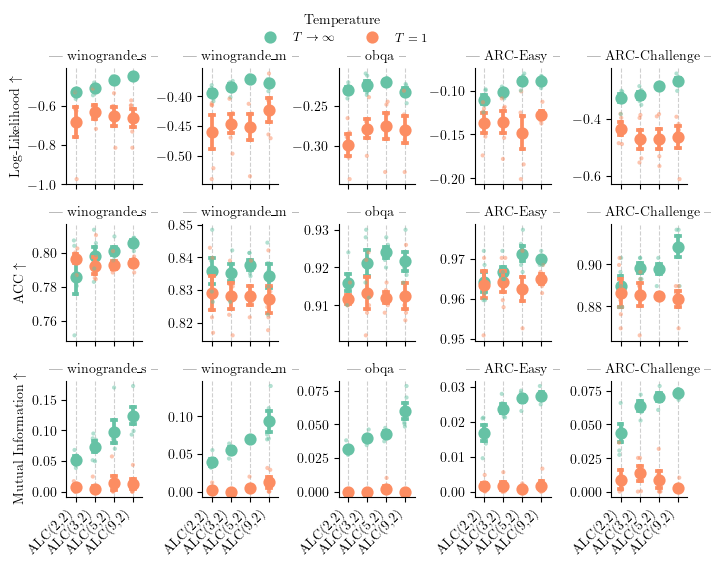

In [85]:
# stack df_vi to df_plot
hue_name = 'BmaMode'
df_plot['NCurveSegment'] = df_plot['NCurveSegment'].astype(int)
df_plot_ = pd.concat([df_plot,], ignore_index=True)
# hue
# numeric_rhos = sorted(int(x) for x in df_plot_['NCurveSegment'].unique())
# df_plot_['NCurveSegment'] = df_plot_['NCurveSegment'].astype(str)
# hue_order = [str(x) for x in numeric_rhos]
hue_order = df_plot_[hue_name].unique()
hue_order = "PPD Uniform", "PPD",
hue_palette = sns.color_palette("Set2", n_colors=len(hue_order))

row_order = "ll", "acc", "test_mutual_information_ppd",
col_order = "winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge",
# order = df_plot_['Model'].unique()
order = [
         rf'{pretrained_model_name}(2,2)', 
         rf'{pretrained_model_name}(3,2)',
         rf'{pretrained_model_name}(5,2)',
         rf'{pretrained_model_name}(9,2)',]

print(f"Models {set(df_plot_['Model'].unique()) - set(order)} missing:")

# # Prepare descriptive Model labels
# def get_model_label(row):
#     if str(row['Model']).startswith('DE'):
#         return f"{row['Model']}({row['NCurveSegment']})"
#     return f"{row['Model']}"

# df_plot_['Model_Label'] = df_plot_.apply(get_model_label, axis=1)

# # Ensure metric order
# metric_order = ['acc', 'll', 'ece']
# df_plot_['Metric'] = pd.Categorical(df_plot_['Metric'], categories=metric_order, ordered=True)

# Seaborn Catplot (ANOVA style)
g = sns.catplot(
    data=df_plot_, y='value', x='Model',
    col='Dataset', row='Metric',
    row_order=row_order, col_order=col_order,
    order=order,
    kind='point', join=False, capsize=.2,
    markers='o', palette=hue_palette, hue=hue_name,
    dodge=False, sharey=False, height=figsize[1]/1.9, aspect=.8,
    legend=True, errorbar="se", hue_order=hue_order,
)

# Overlay strip plots for original points (small, alpha=0.5)
for (metric, ds), ax in g.axes_dict.items():
    subset = df_plot_[(df_plot_['Dataset'] == ds) & (df_plot_['Metric'] == metric)]
    sns.stripplot(
        data=subset, y='value', x='Model',
        order=order,
        ax=ax, palette=hue_palette, alpha=0.5, size=3,
        dodge=False, hue=hue_name, legend=False, hue_order=hue_order,
    )
    
    # Refine grid and labels
    ax.grid(True, axis='x', linestyle='--', alpha=0.6)

    # add vertical line at BLob mean value for reference
    subset_blob = subset[subset['Model'] == 'BLoB WB']
    if not subset_blob.empty and np.isfinite(subset_blob['value'].mean()):
        ax.axvline(x=subset_blob['value'].mean(), color='gray', linestyle='--', label='BLoB Mean')
    
    # Label mapping for x-axis
    if metric == 'acc':
        ax.set_ylabel(r'ACC $\uparrow$')
    elif metric == 'll':
        ax.set_ylabel(r'Log-Likelihood $\uparrow$')
    elif metric == 'ece':
        ax.set_ylabel(r'ECE $\downarrow$')
    elif metric == 'brier':
        ax.set_ylabel(r'Brier Score $\downarrow$')
    elif metric == 'test_mutual_information_ppd':
        ax.set_ylabel(r'Mutual Information $\uparrow$') 
    elif metric == 'test_std_entropy_along_curve':
        ax.set_ylabel(r'Std Entropy Along Curve $\downarrow$')

    # clip x-axis to range of min without MAP
    # def only_finit(x):
    #     return x[np.isfinite(x)]
    # min_value = only_finit(subset[subset['Model'] != 'MAP']['value']).min()
    # mean_value_MAP = only_finit(subset[subset['Model'] == 'MAP']['value']).mean()
    # if np.isfinite(min_value):
    #     ax.set_ylim(min(min_value, mean_value_MAP)-0.005)  # add some padding on the left

# Adjust layout and titles
g.set_titles(row_template='', col_template='{col_name} --')


# rotate x labels
for i, ax in enumerate(g.axes[:,1:].flatten()):
    # plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
    # plt.setp(ax.get_yticklabels(), rotation=20, ha='right')
    ax.set_ylabel('')  # remove x-axis label since it's redundant with the rotated labels

g.tight_layout()
# set wspace
# g.fig.subplots_adjust(wspace=0.35)

# plt.savefig("result/performance_flatLoRA_vs_vanilla.pdf", dpi=300, bbox_inches='tight')

for ax in g.axes[-1]:
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(order, rotation=45, ha="right") 
    ax.set_xlabel('')  # remove x-axis label since it's redundant with the rotated labels

sns.move_legend(g, "upper left", bbox_to_anchor=(0.3, 1.06), ncol=2, title='Temperature')
#rename legend labels
new_labels = {'PPD Uniform': r'$T \to \infty$', 'PPD': '$T=1$'}
for t, l in zip(g._legend.texts, g._legend.get_texts()):
    if l.get_text() in new_labels:
        l.set_text(new_labels[l.get_text()])
g.tight_layout()
plt.savefig("my-overleaf-project/new_figures/PPD_vsPPD_unifrom.pdf", dpi=300, bbox_inches='tight', pad_inches=0.05)
# g.add_legend(title='#CurveSegments')
# plt.savefig("result/performance_pointplot.pdf", dpi=300)
# plt.savefig("my-overleaf-project/figures/performance_pointplot.pdf", dpi=300, bbox_inches='tight')
plt.show()

### final summary

In [186]:
df_subset = df_clean.copy()
df_plot = df_subset.melt(id_vars=idx_ids, value_vars=value_ids, var_name='Metric', value_name='value')
df_plot['Config'] = df_plot.apply(lambda r: " | ".join([f"{k}={r[k]}" for k in variable_idx if k not in ['CurveSpace', 'NCurveSegment', 'NumPretrained', 'Dataset', 'BmaMode']]), axis=1)


df_plot = df_plot[(df_plot['BmaMode'] != 'PPD') & (df_plot['LoraMode'] == "A(t)eB(t)")]
# df_plot = df_plot[(df_plot['BmaMode'] == 'PPD Uniform') & (df_plot['Dataset'] == "winogrande_m") & (df_plot['Metric'] == "ll") & (df_plot['LoraMode'] == "A(t)eB(t)")]
df_plot = df_plot[(df_plot['LoraRho'] == 0.25)]
# df_plot = df_plot[df_plot['Metric'].isin(["ll", "acc", "ece"])]


def map_model(x):
    if x['BmaMode'] == 'MAP':
        return "MAP"
    elif x['BmaMode'] == 'DE':
        return f"DE({x['NumPretrained']})"
    elif x['BmaMode'] == 'PPD Uniform':
        is_fixed = x['NumPretrained'] > 0
        seg_deg = x['CurveSegmentDegree']
        
        if seg_deg == 1:
            prefix = "Linear" if is_fixed else "Linear_" + free_model_name
            return f"{prefix}({x['NumPretrained']})"
        else:
            prefix = pretrained_model_name if is_fixed else free_model_name
            return rf"{prefix}({x['N']},{x['M']})"
    else:
        return "None"

df_plot['Model'] = df_plot.apply(map_model, axis=1)
# set NCurveSegment to 0 for MAP and DE
df_plot.loc[df_plot['BmaMode'] == 'MAP', 'NCurveSegment'] = 0
df_plot.loc[df_plot['BmaMode'] == 'DE', 'NCurveSegment'] = 0

df_plot.sort_values(by=['Model'], inplace=True)

# df_plot['NCurveSegment'] = pd.Categorical(df_plot['NCurveSegment'], categories=sorted(df_plot['NCurveSegment'].unique()), ordered=True)

In [187]:
df_plot['Model'].unique()

array(['ALC(2,1)', 'ALC(2,2)', 'ALC(3,1)', 'ALC(3,2)', 'ALC(5,1)',
       'ALC(5,2)', 'ALC(9,1)', 'ALC(9,2)', 'DE(2)', 'DE(3)', 'DE(5)',
       'DE(9)', 'FLC(2,1)', 'FLC(2,2)', 'FLC(3,1)', 'FLC(3,2)',
       'FLC(5,1)', 'FLC(5,2)', 'FLC(9,1)', 'FLC(9,2)', 'Linear(3)',
       'Linear(5)', 'Linear(9)', 'MAP'], dtype=object)

Models set() missing:


/tmp/ipykernel_2109851/1404371413.py:49: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


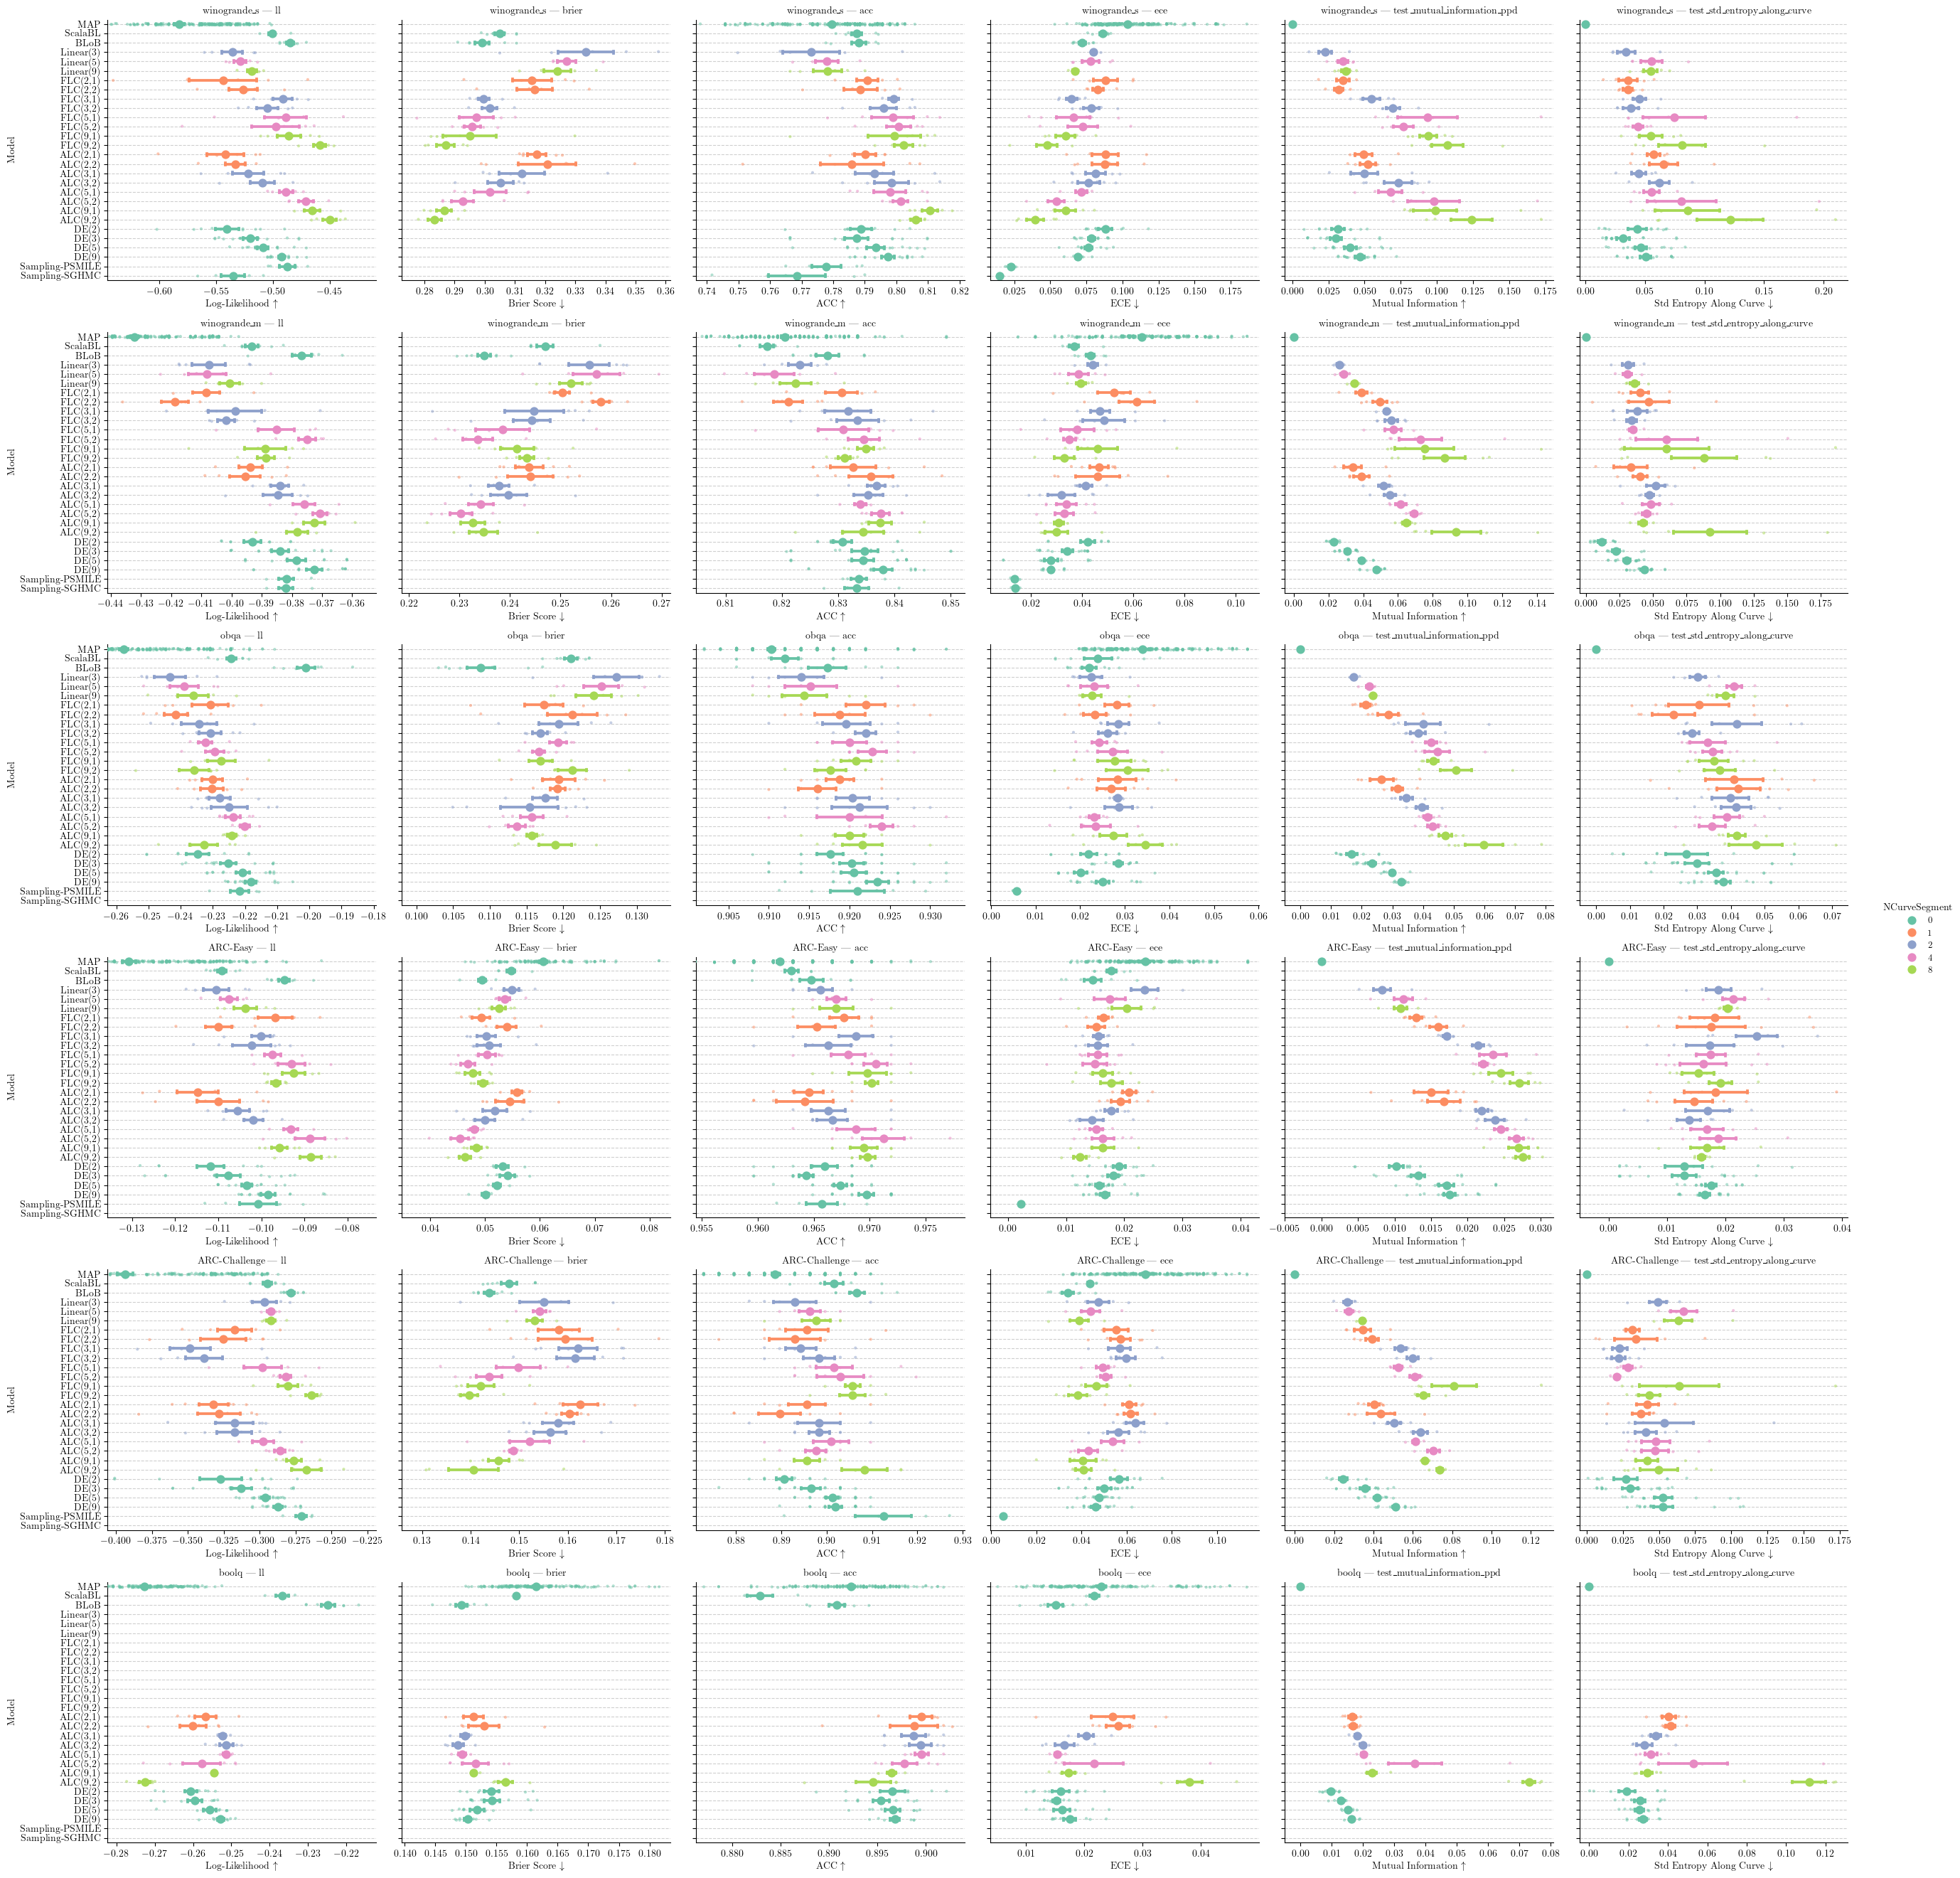

In [188]:
# stack df_vi to df_plot
df_plot['NCurveSegment'] = df_plot['NCurveSegment'].astype(int)
df_plot_ = pd.concat([df_plot, df_vi, df_sampling], ignore_index=True)
# hue
numeric_rhos = sorted(int(x) for x in df_plot_['NCurveSegment'].unique())
df_plot_['NCurveSegment'] = df_plot_['NCurveSegment'].astype(str)
hue_order = [str(x) for x in numeric_rhos]
hue_palette = sns.color_palette("Set2", n_colors=len(hue_order))
col_order = "ll", "brier", "acc", "ece", "test_mutual_information_ppd", "test_std_entropy_along_curve"
row_order = "winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge", "boolq"
# order = df_plot_['Model'].unique()
order = ['MAP', 
         'ScalaBL', 'BLoB', 
         rf'Linear(3)', rf'Linear(5)', rf'Linear(9)', #'OpenLinear(13)',
         rf'{free_model_name}(2,1)',
         rf'{free_model_name}(2,2)', 
         rf'{free_model_name}(3,1)', 
         rf'{free_model_name}(3,2)', 
         rf'{free_model_name}(5,1)',
         rf'{free_model_name}(5,2)', 
         rf'{free_model_name}(9,1)',
         rf'{free_model_name}(9,2)', 
         rf'{pretrained_model_name}(2,1)', 
         rf'{pretrained_model_name}(2,2)', 
         rf'{pretrained_model_name}(3,1)', 
         rf'{pretrained_model_name}(3,2)',
         rf'{pretrained_model_name}(5,1)',
         rf'{pretrained_model_name}(5,2)',
         rf'{pretrained_model_name}(9,1)',
         rf'{pretrained_model_name}(9,2)',
         rf'DE(2)', rf'DE(3)', rf'DE(5)', rf'DE(9)', 
         'Sampling-PSMILE', 'Sampling-SGHMC']

print(f"Models {set(df_plot_['Model'].unique()) - set(order)} missing:")

# # Prepare descriptive Model labels
# def get_model_label(row):
#     if str(row['Model']).startswith('DE'):
#         return f"{row['Model']}({row['NCurveSegment']})"
#     return f"{row['Model']}"

# df_plot_['Model_Label'] = df_plot_.apply(get_model_label, axis=1)

# # Ensure metric order
# metric_order = ['acc', 'll', 'ece']
# df_plot_['Metric'] = pd.Categorical(df_plot_['Metric'], categories=metric_order, ordered=True)

# Seaborn Catplot (ANOVA style)
g = sns.catplot(
    data=df_plot_, x='value', y='Model',
    row='Dataset', col='Metric',
    row_order=row_order, col_order=col_order,
    order=order,
    kind='point', join=False, capsize=.2,
    markers='o', palette=hue_palette, hue='NCurveSegment',
    dodge=False, sharex=False, height=figsize[1]*1.3, aspect=1.,
    legend=True, errorbar="se", hue_order=hue_order,
)

# Overlay strip plots for original points (small, alpha=0.5)
for (ds, metric), ax in g.axes_dict.items():
    subset = df_plot_[(df_plot_['Dataset'] == ds) & (df_plot_['Metric'] == metric)]
    sns.stripplot(
        data=subset, x='value', y='Model',
        order=order,
        ax=ax, palette=hue_palette, alpha=0.5, size=3,
        dodge=False, hue='NCurveSegment', legend=False, hue_order=hue_order,
    )
    
    # Refine grid and labels
    ax.grid(True, axis='y', linestyle='--', alpha=0.6)

    # add vertical line at BLob mean value for reference
    subset_blob = subset[subset['Model'] == 'BLoB WB']
    if not subset_blob.empty and np.isfinite(subset_blob['value'].mean()):
        ax.axvline(x=subset_blob['value'].mean(), color='gray', linestyle='--', label='BLoB Mean')
    
    # Label mapping for x-axis
    if metric == 'acc':
        ax.set_xlabel(r'ACC $\uparrow$')
    elif metric == 'll':
        ax.set_xlabel(r'Log-Likelihood $\uparrow$')
    elif metric == 'ece':
        ax.set_xlabel(r'ECE $\downarrow$')
    elif metric == 'brier':
        ax.set_xlabel(r'Brier Score $\downarrow$')
    elif metric == 'test_mutual_information_ppd':
        ax.set_xlabel(r'Mutual Information $\uparrow$') 
    elif metric == 'test_std_entropy_along_curve':
        ax.set_xlabel(r'Std Entropy Along Curve $\downarrow$')

    # clip x-axis to range of min without MAP
    def only_finit(x):
        return x[np.isfinite(x)]
    min_value = only_finit(subset[subset['Model'] != 'MAP']['value']).min()
    mean_value_MAP = only_finit(subset[subset['Model'] == 'MAP']['value']).mean()
    if np.isfinite(min_value):
        ax.set_xlim(left=min(min_value, mean_value_MAP)-0.005)  # add some padding on the left

# Adjust layout and titles
g.set_titles(row_template='{row_name}', col_template='{col_name}')
g.tight_layout()
# g.add_legend(title='#CurveSegments')
plt.savefig("result/performance_pointplot.pdf", dpi=300)
plt.savefig("my-overleaf-project/figures/performance_pointplot.pdf", dpi=300, bbox_inches='tight')
plt.show()

### mutual inforamtion of curve

Models set() missing:


/tmp/ipykernel_2109851/1856937814.py:49: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


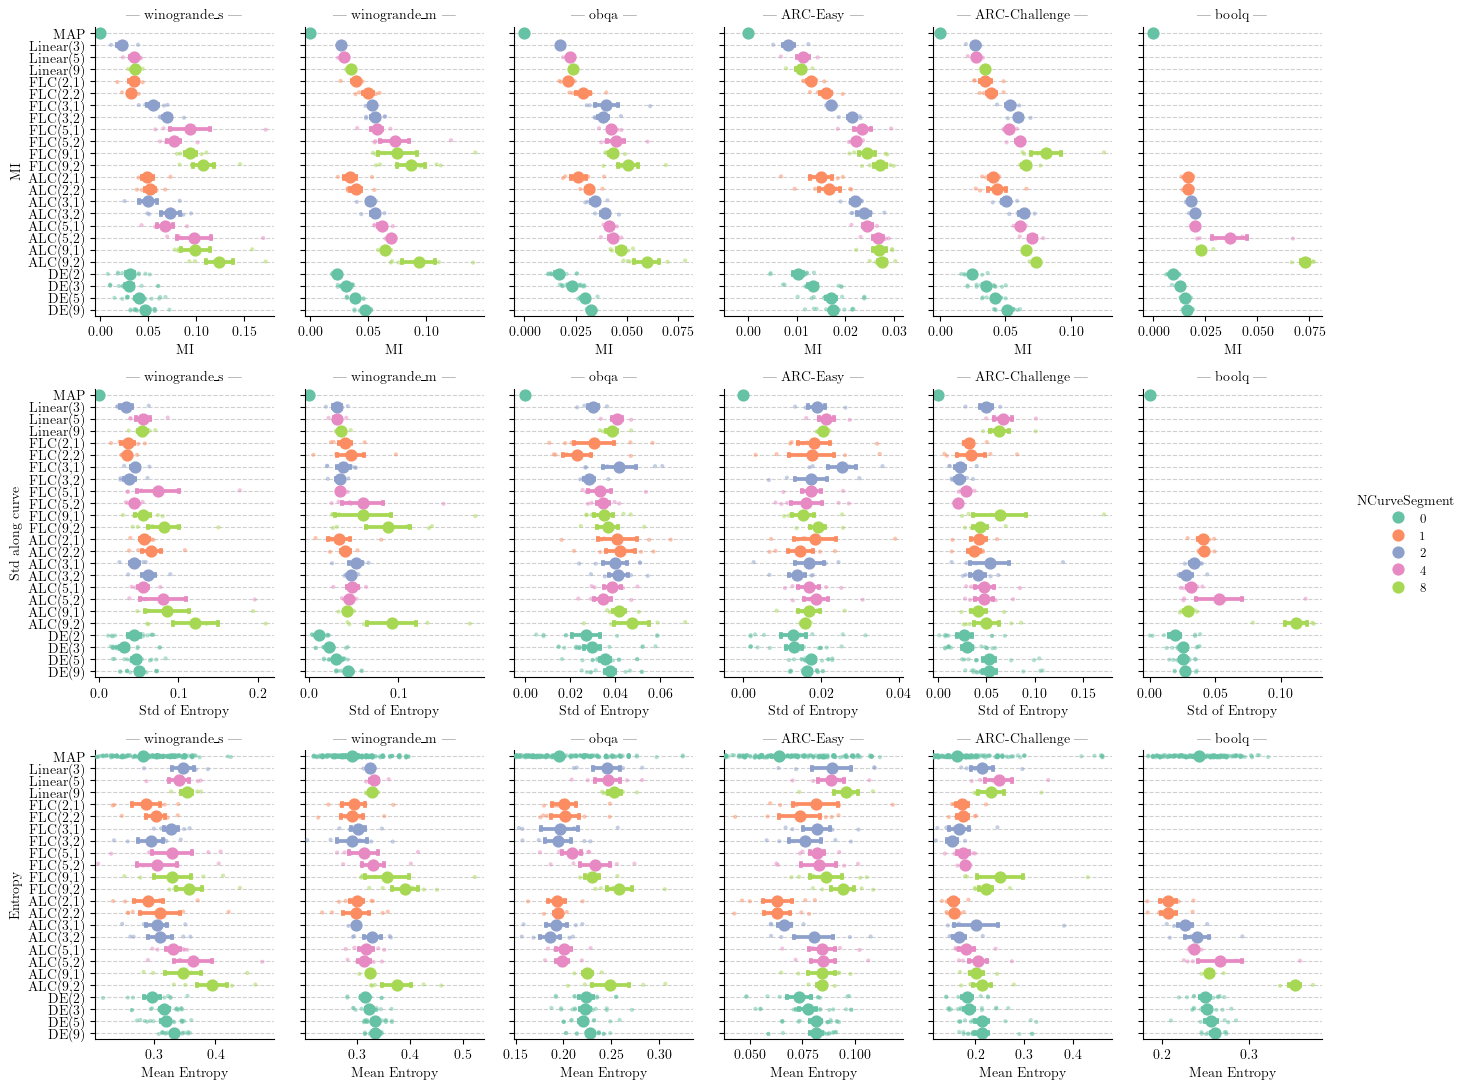

In [189]:
# stack df_vi to df_plot
df_plot['NCurveSegment'] = df_plot['NCurveSegment'].astype(int)
df_plot_ = pd.concat([df_plot,], ignore_index=True)
# hue
numeric_rhos = sorted(int(x) for x in df_plot_['NCurveSegment'].unique())
df_plot_['NCurveSegment'] = df_plot_['NCurveSegment'].astype(str)
hue_order = [str(x) for x in numeric_rhos]
colors = plt.get_cmap('plasma', len(hue_order))(np.arange(len(hue_order)))
hue_palette = {n: colors[i] for i, n in enumerate(hue_order)}
hue_palette = sns.color_palette("Set2", n_colors=len(hue_order))
col_order = "test_mutual_information_ppd", "test_std_entropy_along_curve", "test_mean_entropy_ppd"
row_order = "winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge", "boolq"
# order = df_plot_['Model'].unique()
order = ['MAP', 
        #  'ScalaBL', 'BLoB', 
         rf'Linear(3)', rf'Linear(5)', rf'Linear(9)', #'OpenLinear(13)',
         rf'{free_model_name}(2,1)',
         rf'{free_model_name}(2,2)', 
         rf'{free_model_name}(3,1)', 
         rf'{free_model_name}(3,2)', 
         rf'{free_model_name}(5,1)',
         rf'{free_model_name}(5,2)', 
         rf'{free_model_name}(9,1)',
         rf'{free_model_name}(9,2)', 
         rf'{pretrained_model_name}(2,1)', 
         rf'{pretrained_model_name}(2,2)', 
         rf'{pretrained_model_name}(3,1)', 
         rf'{pretrained_model_name}(3,2)',
         rf'{pretrained_model_name}(5,1)',
         rf'{pretrained_model_name}(5,2)',
         rf'{pretrained_model_name}(9,1)',
         rf'{pretrained_model_name}(9,2)',
         rf'DE(2)', rf'DE(3)', rf'DE(5)', rf'DE(9)',]
print(f"Models {set(df_plot_['Model'].unique()) - set(order)} missing:")

# Prepare descriptive Model labels
def get_model_label(row):
    if str(row['Model']).startswith('DE'):
        return f"{row['Model']}({row['NCurveSegment']})"
    return f"{row['Model']}"

df_plot_['Model_Label'] = df_plot_.apply(get_model_label, axis=1)

# # Ensure metric order
# metric_order = ['acc', 'll', 'ece']
# df_plot_['Metric'] = pd.Categorical(df_plot_['Metric'], categories=metric_order, ordered=True)

# Seaborn Catplot (ANOVA style)
g = sns.catplot(
    data=df_plot_, x='value', y='Model',
    row='Metric', col='Dataset',
    row_order=col_order, col_order=row_order,
    order=order,
    kind='point', join=False, capsize=.2,
    markers='o', palette=hue_palette, hue='NCurveSegment',
    dodge=False, sharex=False, height=figsize[0]/1.5, aspect=1/1.618,
    legend=True, errorbar="se", hue_order=hue_order,
)

# Overlay strip plots for original points (small, alpha=0.5)
for (metric, ds), ax in g.axes_dict.items():
    subset = df_plot_[(df_plot_['Dataset'] == ds) & (df_plot_['Metric'] == metric)]
    sns.stripplot(
        data=subset, x='value', y='Model',
        order=order,
        ax=ax, palette=hue_palette, alpha=0.5, size=3,
        dodge=False, hue='NCurveSegment', legend=False, hue_order=hue_order,
    )
    
    # Refine grid and labels
    ax.grid(True, axis='y', linestyle='--', alpha=0.6)
    
    # Label mapping for x-axis
    if metric == 'acc':
        ax.set_xlabel(r'ACC $\uparrow$')
    elif metric == 'll':
        ax.set_xlabel(r'Log-Likelihood $\uparrow$')
    elif metric == 'ece':
        ax.set_xlabel(r'ECE $\downarrow$')
    elif metric == 'test_mutual_information_ppd':
        ax.set_xlabel(r'MI')
    elif metric == 'test_std_entropy_along_curve':
        ax.set_xlabel(r'Std of Entropy')
    elif metric == 'test_mean_entropy_ppd':
        ax.set_xlabel(r'Mean Entropy')

    # clip x-axis to range of min without MAP
    def only_finit(x):
        return x[np.isfinite(x)]
    min_value = only_finit(subset[subset['Model'] != 'MAP']['value']).min()
    mean_value_MAP = only_finit(subset[subset['Model'] == 'MAP']['value']).mean()
    if np.isfinite(min_value):
        ax.set_xlim(left=min(min_value, mean_value_MAP)-0.005)  # add some padding on the left

# Adjust layout and titles
# g.set_titles(row_template='{row_name}', col_template='{col_name}')
g.set_titles(row_template='', col_template='{col_name} |')
g.tight_layout()
g.axes[0,0].set_ylabel('MI')
g.axes[1,0].set_ylabel('Std along curve')
g.axes[2,0].set_ylabel('Entropy')
# g.add_legend(title='#CurveSegments')
# plt.savefig("result/std_mi_along_curve.png", dpi=300)
plt.savefig("result/std_mi_along_curve.pdf", dpi=300)
plt.show()

Models set() missing:


/tmp/ipykernel_2109851/446959689.py:28: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


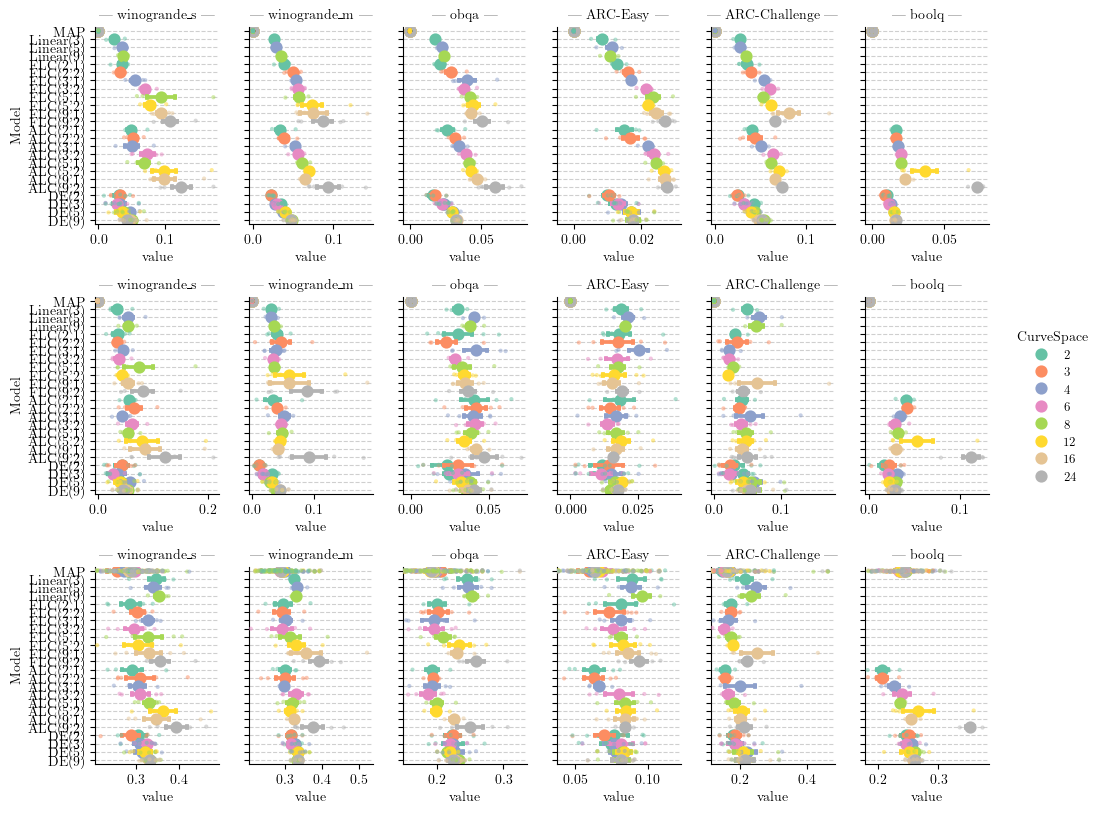

In [190]:
# stack df_vi to df_plot
df_plot_ = pd.concat([df_plot,], ignore_index=True)
# hue
hue_name = 'CurveSpace'
df_plot[hue_name] = df_plot[hue_name].astype(int)
numeric_rhos = sorted(int(x) for x in df_plot_[hue_name].unique())
df_plot_[hue_name] = df_plot_[hue_name].astype(str)
hue_order = [str(x) for x in numeric_rhos]
colors = plt.get_cmap('plasma', len(hue_order))(np.arange(len(hue_order)))
hue_palette = {n: colors[i] for i, n in enumerate(hue_order)}
hue_palette = sns.color_palette("Set2", n_colors=len(hue_order))

print(f"Models {set(df_plot_['Model'].unique()) - set(order)} missing:")

# Prepare descriptive Model labels
def get_model_label(row):
    if str(row['Model']).startswith('DE'):
        return f"{row['Model']}({row['NCurveSegment']})"
    return f"{row['Model']}"

df_plot_['Model_Label'] = df_plot_.apply(get_model_label, axis=1)

# # Ensure metric order
# metric_order = ['acc', 'll', 'ece']
# df_plot_['Metric'] = pd.Categorical(df_plot_['Metric'], categories=metric_order, ordered=True)

# Seaborn Catplot (ANOVA style)
g = sns.catplot(
    data=df_plot_, x='value', y='Model',
    row='Metric', col='Dataset',
    row_order=col_order, col_order=row_order,
    order=order,
    kind='point', join=False, capsize=.2,
    markers='o', palette=hue_palette, hue=hue_name,
    dodge=False, sharex=False, height=figsize[0]/2, aspect=1/1.618,
    legend=True, errorbar="se", hue_order=hue_order,
)

# Overlay strip plots for original points (small, alpha=0.5)
for (metric, ds), ax in g.axes_dict.items():
    subset = df_plot_[(df_plot_['Dataset'] == ds) & (df_plot_['Metric'] == metric)]
    sns.stripplot(
        data=subset, x='value', y='Model',
        order=order,
        ax=ax, palette=hue_palette, alpha=0.5, size=3,
        dodge=False, hue=hue_name, legend=False, hue_order=hue_order,
    )
    
    # Refine grid and labels
    ax.grid(True, axis='y', linestyle='--', alpha=0.6)
    
    # Label mapping for x-axis
    if metric == 'acc':
        ax.set_xlabel(r'ACC $\uparrow$')
    elif metric == 'll':
        ax.set_xlabel(r'Log-Likelihood $\uparrow$')
    elif metric == 'ece':
        ax.set_xlabel(r'ECE $\downarrow$')

    # clip x-axis to range of min without MAP
    def only_finit(x):
        return x[np.isfinite(x)]
    min_value = only_finit(subset[subset['Model'] != 'MAP']['value']).min()
    mean_value_MAP = only_finit(subset[subset['Model'] == 'MAP']['value']).mean()
    if np.isfinite(min_value):
        ax.set_xlim(left=min(min_value, mean_value_MAP)-0.005)  # add some padding on the left

# Adjust layout and titles
# g.set_titles(row_template='{row_name}', col_template='{col_name}')
g.set_titles(row_template='', col_template='{col_name} |')
g.tight_layout()
# g.axes[0,0].set_ylabel('MI')
# g.axes[1,0].set_ylabel('Std along curve')
# g.add_legend(title='#CurveSegments')
# plt.savefig("result/std_mi_along_curve.png", dpi=300)
plt.savefig("result/std_mi_along_curve.pdf", dpi=300)
plt.show()

### DE vs Curve

In [63]:
# Build Config label
df_subset = df_clean.copy()
# df_subset = df_subset[(df_subset['LoraMode'] == "A(t)eB(t)") & (df_subset['BmaMode'] != 'MAP')]
df_subset = df_subset[(df_subset['LoraMode'] == "A(t)eB(t)") & (df_subset['BmaMode'] != 'PPD') & (df_subset['BmaMode'] != 'MAP') & (df_subset['LoraRho'] == 0.25)]

# Filter for only configs with open curves and then inner join back to keep only those configs across all seeds and metrics
match_cols = deepcopy(variable_idx) + ['Seed']
match_cols.remove('NumPretrained')
filter_mask = df_subset[df_subset['NumPretrained'] > 0.][match_cols].drop_duplicates()
df_subset = df_subset.merge(filter_mask, on=match_cols, how='inner')

df_plot = df_subset.melt(id_vars=idx_ids, value_vars=value_ids, var_name='Metric', value_name='value')
# df_plot['Config'] = df_plot.apply(lambda r: f"fix={r['NumPretrained']}, k={r['CurveSpace']}, SegDeg={r['CurveSegmentDegree']}, N_Seg={r['NCurveSegment']}, rho={r['LoraRho']}, Mode={r['LoraMode']}/{r['CurveMode']}", axis=1)
df_plot['Config'] = df_plot.apply(lambda r: " | ".join([f"{k}={r[k]}" for k in variable_idx if k not in ['CurveSpace', 'NCurveSegment', 'NumPretrained', 'Dataset', 'BmaMode',]]), axis=1)


def map_hue(x):
    if x['BmaMode'] == 'MAP':
        return "MAP"
    elif x['BmaMode'] == 'DE':
        return f"DE"
    elif x['BmaMode'] == 'PPD Uniform':
        is_fixed = np.sum(x['NumPretrained']) > 0
        seg_deg = x['CurveSegmentDegree']
        curve_space = int(x['CurveSpace'])
        
        if seg_deg == 1:
            prefix = "Linear" if is_fixed else "Linear_" + free_model_name
            return f"{prefix}"
        else:
            prefix = pretrained_model_name if is_fixed else free_model_name
            return f"{prefix}(N,{x['M']})"
    else:
        return "Other"


# df_plot['Model'] = df_plot.apply(map_model, axis=1)
df_plot['Model'] = df_plot.apply(map_hue, axis=1)
# set NCurveSegment to 0 for MAP and DE
df_plot.sort_values(by=['Model'], inplace=True)

col_order = df_subset['Dataset'].unique()
col_order.sort()

df_plot[cols+ ['Model']].apply(np.unique)


Id                    [00oxdnp0, 07jkw5um, 0at7l52y, 0e6rq9pf, 0jjza...
CurveSpace                                  [2, 3, 4, 6, 8, 12, 16, 24]
NumPretrained                                           [0, 2, 3, 5, 9]
Jitter                                                              [0]
Seed                                              [1, 2, 20, 400, 8000]
WeightDecay                                                     [0.001]
Dataset               [ARC-Challenge, ARC-Easy, boolq, obqa, winogra...
BmaMode                                               [DE, PPD Uniform]
DS_Sampling                                                 [minibatch]
DS_Mode                                                       [classic]
DS_WindowSize                                                      [-1]
EntropyMaxScale                                                    [-1]
NumSteps                                                        [10000]
LoraMode                                                    [A(t

In [64]:
df_plot['Model'].unique()

array(['ALC(N,1)', 'ALC(N,2)', 'DE', 'FLC(N,1)', 'FLC(N,2)', 'Linear'],
      dtype=object)

Models set() missing:


/tmp/ipykernel_2413536/2771721702.py:31: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


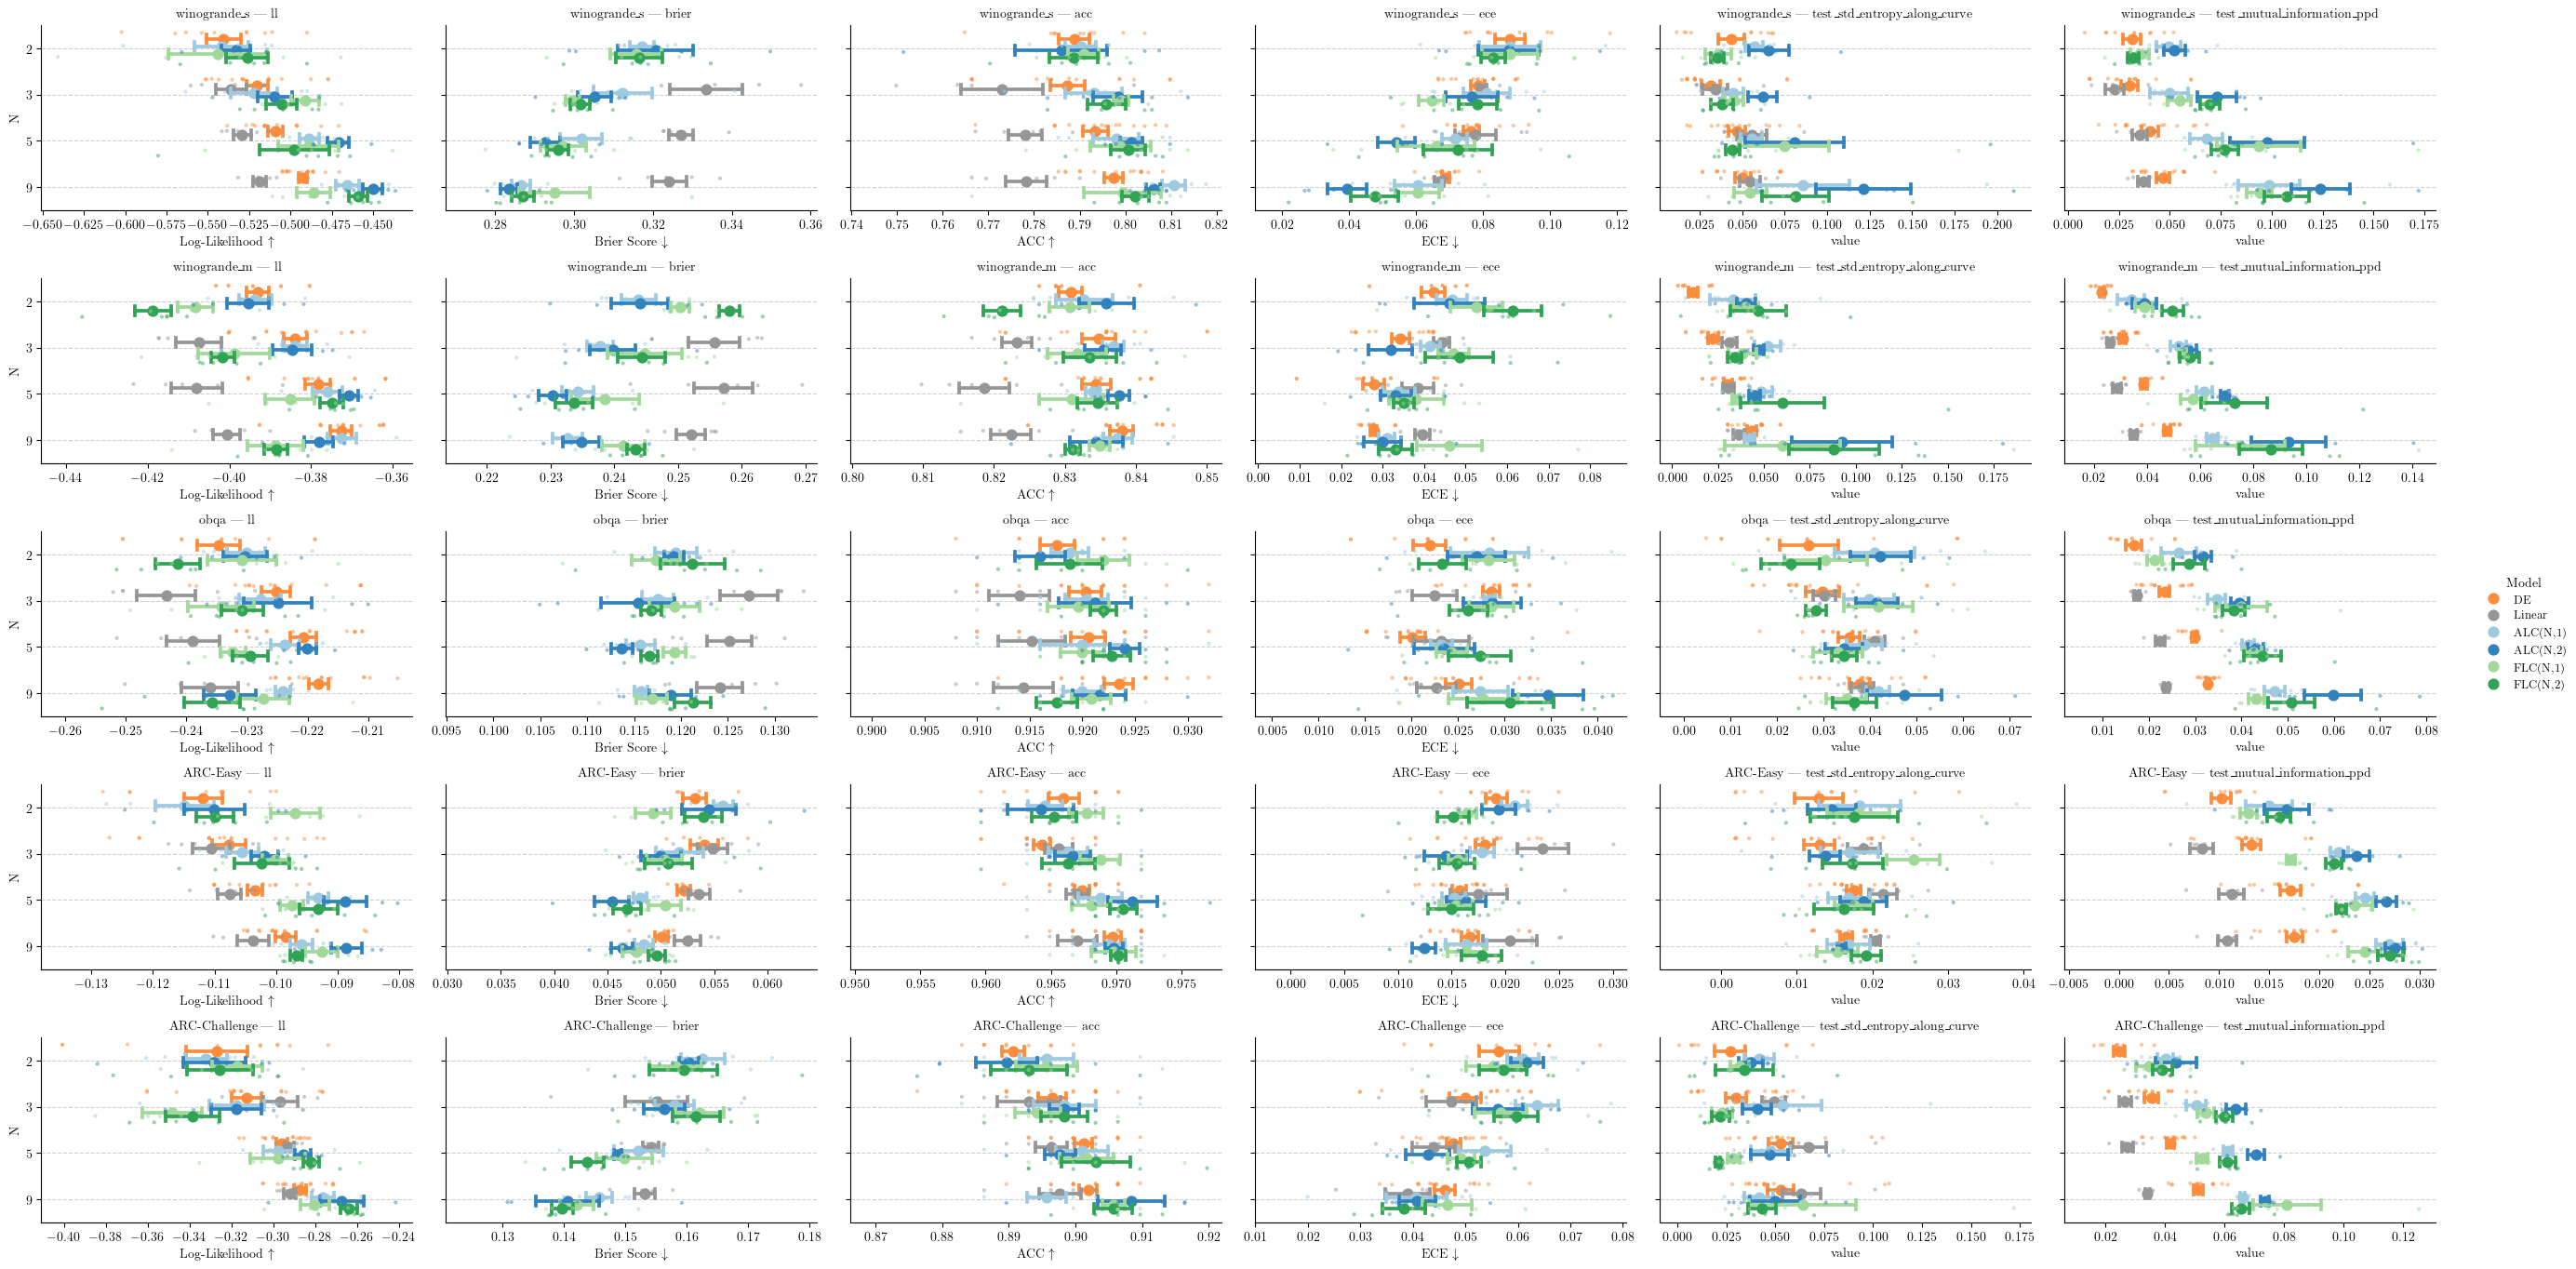

In [77]:
# stack df_vi to df_plot
hue_name = 'Model'
x_name = 'N'
df_plot_ = deepcopy(df_plot)

# hue_order = ['DE', 'Linear', 'Pre(SegDeg=2)', 'Pre(SegDeg=3)', 'AtoCLinear', 'AtoC(SegDeg=2)',  'AtoC(SegDeg=3)']
hue_order = ['DE', 'Linear', f'{pretrained_model_name}(N,1)', f'{pretrained_model_name}(N,2)', f'{free_model_name}(N,1)',  f'{free_model_name}(N,2)']
hue_palette = sns.color_palette("tab20c")
hue_palette = {'DE': hue_palette[5], 
               'Linear': hue_palette[17], 
               "Linear_" + free_model_name: hue_palette[19], 
               f'{pretrained_model_name}(N,1)': hue_palette[2], 
               f'{pretrained_model_name}(N,2)': hue_palette[0], 
               f'{free_model_name}(N,1)': hue_palette[10],  
               f'{free_model_name}(N,2)': hue_palette[8]}
col_order = "ll", "brier", "acc", "ece", "test_std_entropy_along_curve", "test_mutual_information_ppd"
row_order = "winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge",
order = df_plot_[x_name].unique()
order.sort()
# order = ['MAP', 'DE(5)', 'Fix=False, N_Seg=1, SegDeg=2',
#        'Fix=False, N_Seg=3, SegDeg=2', 'Fix=False, N_Seg=6, SegDeg=2',
#        'Fix=True, N_Seg=4, SegDeg=3']


print(f"Models {set(df_plot_[x_name].unique()) - set(order)} missing:")
# x as string for catplot
df_plot_[x_name] = df_plot_[x_name].astype(str)
order = [str(x) for x in order]

# Seaborn Catplot (ANOVA style)
g = sns.catplot(
    data=df_plot_, x='value', y=x_name,
    row='Dataset', col='Metric',
    row_order=row_order, col_order=col_order,
    order=order,
    kind='point', join=False, capsize=.2,
    markers='o', palette=hue_palette, hue=hue_name,
    dodge=0.4, sharex=False, height=figsize[0]/2, aspect=1.618,
    legend=True, errorbar="se", hue_order=hue_order,
)

# Overlay strip plots for original points (small, alpha=0.5)
for (ds, metric), ax in g.axes_dict.items():
    subset = df_plot_[(df_plot_['Dataset'] == ds) & (df_plot_['Metric'] == metric)]
    sns.stripplot(
        data=subset, x='value', y=x_name,
        order=order,
        ax=ax, palette=hue_palette, alpha=0.5, size=3,
        dodge=0.4, hue=hue_name, legend=False, hue_order=hue_order,
    )
    
    # Refine grid and labels
    ax.grid(True, axis='y', linestyle='--', alpha=0.6)
    
    # Label mapping for x-axis
    if metric == 'acc':
        ax.set_xlabel(r'ACC $\uparrow$')
    elif metric == 'll':
        ax.set_xlabel(r'Log-Likelihood $\uparrow$')
    elif metric == 'ece':
        ax.set_xlabel(r'ECE $\downarrow$')
    elif metric == 'brier':
        ax.set_xlabel(r'Brier Score $\downarrow$')

    # clip x-axis to range of min without MAP
    def only_finit(x):
        return x[np.isfinite(x)]
    min_value = only_finit(subset[subset[x_name] != 'MAP']['value']).min()
    mean_value_MAP = only_finit(subset[subset[x_name] == 'MAP']['value']).mean()
    if np.isfinite(min_value):
        ax.set_xlim(left=min(min_value, mean_value_MAP)-0.01)  # add some padding on the left

# Adjust layout and titles
g.set_titles(row_template='{row_name}', col_template='{col_name}')
g.tight_layout()
# g.add_legend(title='#CurveSegments')
# plt.savefig("result/performance_pointplot.png", dpi=300)
# plt.savefig("result/performance_pointplot.pdf", dpi=300)
plt.show()

/tmp/ipykernel_2413536/3066841950.py:6: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


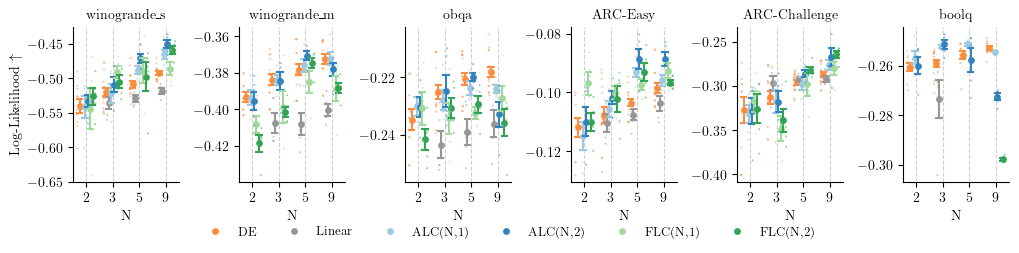

In [78]:
# Only LL metric plotted with col='Dataset' and col_wrap=3
df_plot_ll = df_plot_[df_plot_['Metric'] == 'll'].copy()

col_order_ds = ["winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge", "boolq"]

g = sns.catplot(
    data=df_plot_ll, y='value', x=x_name,
    col='Dataset', col_wrap=6,
    col_order=col_order_ds,
    order=order,
    kind='point', join=False, capsize=.2, linewidth=1.5,
    markers='o', palette=hue_palette, hue=hue_name,
    dodge=0.5, sharey=False, sharex=False, height=figsize[1]/1.4, aspect=1/1.4,
    legend=True, errorbar="se", hue_order=hue_order,
)

# Overlay strip plots for original points (small, alpha=0.5)
for ds, ax in g.axes_dict.items():
    subset = df_plot_ll[df_plot_ll['Dataset'] == ds]
    sns.stripplot(
        data=subset, y='value', x=x_name,
        order=order,
        ax=ax, palette=hue_palette, alpha=0.5, size=1.5,
        dodge=0.5, hue=hue_name, legend=False, hue_order=hue_order,
    )
    
    # Refine grid and labels
    ax.grid(True, axis='x', linestyle='--', alpha=0.6)
    
    # # Label mapping for x-axis
    ax.set_ylabel('')

    # clip x-axis to range of min without MAP
    def only_finit(x):
        return x[np.isfinite(x)]
    
    non_map_vals = only_finit(subset[subset[x_name] != 'MAP']['value'])
    map_vals = only_finit(subset[subset[x_name] == 'MAP']['value'])
    
    min_value = non_map_vals.min() if not non_map_vals.empty else np.nan
    mean_value_MAP = map_vals.mean() if not map_vals.empty else np.nan
    
    # if np.isfinite(min_value) and np.isfinite(mean_value_MAP):
    #     ax.set_ylim(min(min_value, mean_value_MAP)-0.01)  # add some padding on the left
    # elif np.isfinite(min_value):
    #     ax.set_ylim(min_value-0.01)

g.axes[0].set_ylabel(r'Log-Likelihood $\uparrow$')
# Adjust layout and titles
g.set_titles(col_template='{col_name}')
g.tight_layout()

# sns.move_legend(g, loc='center', bbox_to_anchor=(0.83, 0.25), title=hue_name)
# flatten legend at top
sns.move_legend(g, loc='lower center', bbox_to_anchor=(0.45, -0.05), ncol=len(hue_order), title="")

plt.savefig("result/performance_DE_vs_Curve.pdf", dpi=300, bbox_inches='tight')
plt.show()

/tmp/ipykernel_2413536/2735217248.py:8: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


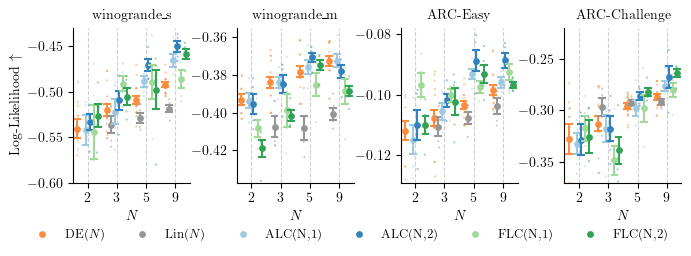

In [79]:
# Only LL metric plotted with col='Dataset' and col_wrap=3
df_plot_ll = df_plot_[df_plot_['Metric'] == 'll'].copy()

col_order_ds = ["winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge", "boolq"]
col_order_ds = ["winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge"]
col_order_ds = ["winogrande_s", "winogrande_m", "ARC-Easy", "ARC-Challenge"]

g = sns.catplot(
    data=df_plot_ll, y='value', x=x_name,
    col='Dataset', col_wrap=6,
    col_order=col_order_ds,
    order=order,
    kind='point', join=False, capsize=.2, linewidth=1.5,
    markers='o', palette=hue_palette, hue=hue_name,
    dodge=0.7, sharey=False, height=figsize[1]/1.4, aspect=1/1.4,
    legend=True, errorbar="se", hue_order=hue_order,
)

# Overlay strip plots for original points (small, alpha=0.5)
for ds, ax in g.axes_dict.items():
    subset = df_plot_ll[df_plot_ll['Dataset'] == ds]
    sns.stripplot(
        data=subset, y='value', x=x_name,
        order=order,
        ax=ax, palette=hue_palette, alpha=0.5, size=1.5,
        dodge=0.4, hue=hue_name, legend=False, hue_order=hue_order,
    )
    
    # Refine grid and labels
    ax.grid(True, axis='x', linestyle='--', alpha=0.6)
    
    # # Label mapping for x-axis
    # ax.set_ylabel('')
    # ax.set_ylabel(r'Log-Likelihood $\uparrow$')

    # clip x-axis to range of min without MAP
    def only_finit(x):
        return x[np.isfinite(x)]
    
    non_map_vals = only_finit(subset[subset[x_name] != 'MAP']['value'])
    map_vals = only_finit(subset[subset[x_name] == 'MAP']['value'])
    
    min_value = non_map_vals.min() if not non_map_vals.empty else np.nan
    mean_value_MAP = map_vals.mean() if not map_vals.empty else np.nan
    
    if np.isfinite(min_value) and np.isfinite(mean_value_MAP):
        ax.set_ylim(min(min_value, mean_value_MAP)-0.001)  # add some padding on the left
    elif np.isfinite(min_value):
        ax.set_ylim(min_value-0.001)

# g.axes[0].set_xlabel(r'Log-Likelihood $\rightarrow$')
# Adjust layout and titles
g.set_titles(col_template='{col_name}')
# reduce vertical space between subplots
g.tight_layout()
g.fig.subplots_adjust(wspace=0.4)

# sns.move_legend(g, loc='center', bbox_to_anchor=(0.83, 0.25), title=hue_name)
# flatten legend at top
sns.move_legend(g, loc='lower center', bbox_to_anchor=(0.31, -0.06), ncol=len(hue_order), title="")
# rename legend labels
for text in g.legend.get_texts():
    if text.get_text() == 'Linear':
        text.set_text(r'Lin($N$)')
    elif text.get_text() == 'DE':
        text.set_text(r'DE($N$)')
g.axes[0].set_ylim(-0.6, -0.43)
g.axes[3].set_ylim(-0.37, -0.22)
# g.axes[0].set_yticks([-0.55, -0.45])
# g.axes[1].set_yticks([-0.41, -0.37])
# g.axes[2].set_yticks([-0.24, -0.22])
# g.axes[2].set_yticks([-0.12, -0.09])
# g.axes[3].set_yticks([-0.35, -0.24])
# g.axes[5].set_xticks([-0.27, -0.25])
g.set_xlabels(n_name)
g.set_ylabels(r'Log-Likelihood $\uparrow$')

plt.savefig("result/performance_DE_vs_Curve.pdf", dpi=300, bbox_inches='tight')
plt.savefig("my-overleaf-project/new_figures/performance_DE_vs_Curve.pdf", dpi=300, bbox_inches='tight', pad_inches=0.05)
plt.show()

/tmp/ipykernel_2413536/3004066457.py:8: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


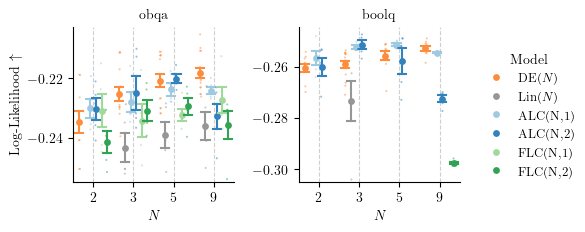

In [82]:
# Only LL metric plotted with col='Dataset' and col_wrap=3
df_plot_ll = df_plot_[df_plot_['Metric'] == 'll'].copy()

col_order_ds = ["winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge"]
col_order_ds = ["winogrande_s", "winogrande_m", "ARC-Easy", "ARC-Challenge"]
col_order_ds = ["obqa", "boolq"]

g = sns.catplot(
    data=df_plot_ll, y='value', x=x_name,
    col='Dataset', col_wrap=2,
    col_order=col_order_ds,
    order=order,
    kind='point', join=False, capsize=.2, linewidth=1.5,
    markers='o', palette=hue_palette, hue=hue_name,
    dodge=0.7, sharey=False, height=figsize[1]/1.4, aspect=1,
    legend=True, errorbar="se", hue_order=hue_order,
)

# Overlay strip plots for original points (small, alpha=0.5)
for ds, ax in g.axes_dict.items():
    subset = df_plot_ll[df_plot_ll['Dataset'] == ds]
    sns.stripplot(
        data=subset, y='value', x=x_name,
        order=order,
        ax=ax, palette=hue_palette, alpha=0.5, size=1.5,
        dodge=0.4, hue=hue_name, legend=False, hue_order=hue_order,
    )
    
    # Refine grid and labels
    ax.grid(True, axis='x', linestyle='--', alpha=0.6)
    
    # # Label mapping for x-axis
    # ax.set_ylabel('')
    # ax.set_ylabel(r'Log-Likelihood $\uparrow$')

    # clip x-axis to range of min without MAP
    def only_finit(x):
        return x[np.isfinite(x)]
    
    non_map_vals = only_finit(subset[subset[x_name] != 'MAP']['value'])
    map_vals = only_finit(subset[subset[x_name] == 'MAP']['value'])
    
    min_value = non_map_vals.min() if not non_map_vals.empty else np.nan
    mean_value_MAP = map_vals.mean() if not map_vals.empty else np.nan
    
    if np.isfinite(min_value) and np.isfinite(mean_value_MAP):
        ax.set_ylim(min(min_value, mean_value_MAP)-0.001)  # add some padding on the left
    elif np.isfinite(min_value):
        ax.set_ylim(min_value-0.001)

# g.axes[0].set_xlabel(r'Log-Likelihood $\rightarrow$')
# Adjust layout and titles
g.set_titles(col_template='{col_name}')
# reduce vertical space between subplots
g.tight_layout()
g.fig.subplots_adjust(wspace=0.4)

# sns.move_legend(g, loc='center', bbox_to_anchor=(0.83, 0.25), title=hue_name)
# flatten legend at top
# sns.move_legend(g, loc='right', bbox_to_anchor=(1., 0.5), ncol=1, title="")
# rename legend labels
for text in g.legend.get_texts():
    if text.get_text() == 'Linear':
        text.set_text(r'Lin($N$)')
    elif text.get_text() == 'DE':
        text.set_text(r'DE($N$)')
# g.axes[0].set_ylim(-0.6, -0.43)
# g.axes[3].set_ylim(-0.37, -0.22)
# g.axes[0].set_yticks([-0.55, -0.45])
# g.axes[1].set_yticks([-0.41, -0.37])
# g.axes[2].set_yticks([-0.24, -0.22])
# g.axes[2].set_yticks([-0.12, -0.09])
# g.axes[3].set_yticks([-0.35, -0.24])
# g.axes[5].set_xticks([-0.27, -0.25])
g.set_xlabels(n_name)
g.set_ylabels(r'Log-Likelihood $\uparrow$')

plt.savefig("result/app_performance_DE_vs_Curve.pdf", dpi=300, bbox_inches='tight')
plt.savefig("my-overleaf-project/new_figures/app_performance_DE_vs_Curve.pdf", dpi=300, bbox_inches='tight', pad_inches=0.05)
plt.show()

In [21]:
df_check = df_plot[df_plot['Metric'] == 'll'].groupby(['NCurveSegment', 'Model', 'Dataset'])[cols].agg(lambda x: len(np.unique(x).tolist()))
# drop columns with only 1 as value
cols_to_drop = [c for c in cols if df_check[c].max() <= 1]
print(f"Dropping columns with only 1 unique value across seeds: {cols_to_drop}")
df_check = df_check.drop(columns=cols_to_drop)
df_check

Dropping columns with only 1 unique value across seeds: ['NumPretrained', 'Jitter', 'WeightDecay', 'Dataset', 'BmaMode', 'DS_Sampling', 'DS_Mode', 'DS_WindowSize', 'EntropyMaxScale', 'NumSteps', 'LoraMode', 'CurveMode', 'LoraRank', 'RegularizationMode', 'Gravity', 'EnergyWeakening', 'Tsample', 'LoraRho', 'LoraRhoS', 'RhoFrequency', 'NCurveSegment', 'OpenEndSegment', 'N']


Id  CurveSpace  Seed  \
NCurveSegment Model    Dataset                               
1             ALC(N,1) ARC-Challenge   5           1     5   
                       ARC-Easy        5           1     5   
                       boolq           5           1     5   
                       obqa            5           1     5   
                       winogrande_m    5           1     5   
...                                   ..         ...   ...   
8             Linear   ARC-Challenge   5           1     5   
                       ARC-Easy        5           1     5   
                       obqa            5           1     5   
                       winogrande_m    5           1     5   
                       winogrande_s    5           1     5   

                                      CurveSegmentDegree  M  N_cps  
NCurveSegment Model    Dataset                                      
1             ALC(N,1) ARC-Challenge                   1  1      1  
                       ARC-Easy                        1  1      1  
                       boolq                           1  1      1  
                       obqa                            1  1      1  
                       winogrande_m                    1  1      1  
...                                                  ... ..    ...  
8             Linear   ARC-Challenge                   1  1      1  
                       ARC-Easy                        1  1      1  
                       obqa                            1  1      1  
                       winogrande_m                    1  1      1  
                       winogrande_s                    1  1      1  

[127 rows x 6 columns]

In [22]:
df_plot[df_plot['Metric'] == 'll'].groupby(['NCurveSegment', 'Model', 'Dataset'])[cols].agg(lambda x: np.unique(x).tolist()).drop(columns=cols_to_drop)

Id  \
NCurveSegment Model    Dataset                                                            
1             ALC(N,1) ARC-Challenge  [cqgb3wrr, jrv5ph44, o4hgsdle, sgvba3fo, soclg...   
                       ARC-Easy       [4jrewnfa, 6780bwk2, h9wburrg, jevzazps, pkpor...   
                       boolq          [2hva45q6, 7773ro6v, mjks4tmh, n4ca3h9i, thpqk...   
                       obqa           [0e6rq9pf, hmxsf0m4, w9n6kity, xkyskytl, yg9re...   
                       winogrande_m   [1795x1mv, 32cyg0ui, 8hw70we6, ms3g5b8j, q4aja...   
...                                                                                 ...   
8             Linear   ARC-Challenge  [6tygs1pn, anwnlmq5, b3ck49ui, d1t2xhbc, o168n...   
                       ARC-Easy       [eq587whh, keqa2or1, pr8nih1z, wf9j469e, y633f...   
                       obqa           [erkou0rm, hu8dtpqq, q7zasiup, vfc9htug, yp69e...   
                       winogrande_m   [23q76xib, 7d18qz60, nzlymgg3, ttq66o90, y4rei...   
                       winogrande_s   [88r2zvh1, 948avvq2, al2srfmj, bkl6c9zx, jkzqc...   

                                     CurveSpace                   Seed  \
NCurveSegment Model    Dataset                                           
1             ALC(N,1) ARC-Challenge        [2]  [1, 2, 20, 400, 8000]   
                       ARC-Easy             [2]  [1, 2, 20, 400, 8000]   
                       boolq                [2]  [1, 2, 20, 400, 8000]   
                       obqa                 [2]  [1, 2, 20, 400, 8000]   
                       winogrande_m         [2]  [1, 2, 20, 400, 8000]   
...                                         ...                    ...   
8             Linear   ARC-Challenge        [8]  [1, 2, 20, 400, 8000]   
                       ARC-Easy             [8]  [1, 2, 20, 400, 8000]   
                       obqa                 [8]  [1, 2, 20, 400, 8000]   
                       winogrande_m         [8]  [1, 2, 20, 400, 8000]   
                       winogrande_s         [8]  [1, 2, 20, 400, 8000]   

                                     CurveSegmentDegree    M N_cps  
NCurveSegment Model    Dataset                                      
1             ALC(N,1) ARC-Challenge                [2]  [1]   [3]  
                       ARC-Easy                     [2]  [1]   [3]  
                       boolq                        [2]  [1]   [3]  
                       obqa                         [2]  [1]   [3]  
                       winogrande_m                 [2]  [1]   [3]  
...                                                 ...  ...   ...  
8             Linear   ARC-Challenge                [1]  [0]   [9]  
                       ARC-Easy                     [1]  [0]   [9]  
                       obqa                         [1]  [0]   [9]  
                       winogrande_m                 [1]  [0]   [9]  
                       winogrande_s                 [1]  [0]   [9]  

[127 rows x 6 columns]

In [23]:
# check similar DE runs (should have the same values for same seed)
# small differences are okay due to different Hardware and non-determinism, but large differences may indicate a problem
df_check = df_plot[(df_plot['Model'] == 'DE') & (df_plot['Metric'] == 'll') & (df_plot['NCurveSegment'] == 2)].groupby(['NCurveSegment', 'Model', 'Dataset', 'Metric', 'Seed'])['value'].describe()
df_check[df_check['count'] > 1]

count      mean       std  \
NCurveSegment Model Dataset       Metric Seed                              
2             DE    ARC-Challenge ll     1       3.0 -0.282325  0.010064   
                                         2       3.0 -0.347240  0.022903   
                                         20      3.0 -0.318867  0.000124   
                                         400     3.0 -0.325780  0.017803   
                                         8000    3.0 -0.290094  0.010586   
                    ARC-Easy      ll     1       3.0 -0.100864  0.007281   
                                         2       3.0 -0.123852  0.002788   
                                         20      3.0 -0.110870  0.000000   
                                         400     3.0 -0.102586  0.008047   
                                         8000    3.0 -0.100226  0.008081   
                    boolq         ll     1       2.0 -0.261266  0.002462   
                                         2       2.0 -0.255579  0.002853   
                                         20      2.0 -0.256816  0.002437   
                                         400     2.0 -0.269186  0.002489   
                                         8000    2.0 -0.254520  0.000175   
                    obqa          ll     1       3.0 -0.227300  0.004035   
                                         2       3.0 -0.232889  0.005749   
                                         20      3.0 -0.211230  0.000076   
                                         400     3.0 -0.225662  0.000407   
                                         8000    3.0 -0.229063  0.011008   
                    winogrande_m  ll     1       3.0 -0.389579  0.002391   
                                         2       3.0 -0.390984  0.015952   
                                         20      3.0 -0.368989  0.001694   
                                         400     3.0 -0.388635  0.010664   
                                         8000    3.0 -0.381198  0.000000   
                    winogrande_s  ll     1       3.0 -0.548660  0.004414   
                                         2       3.0 -0.486602  0.016188   
                                         20      3.0 -0.513203  0.000000   
                                         400     3.0 -0.537503  0.009313   
                                         8000    3.0 -0.514986  0.023723   

                                                    min       25%       50%  \
NCurveSegment Model Dataset       Metric Seed                                 
2             DE    ARC-Challenge ll     1    -0.293945 -0.285230 -0.276514   
                                         2    -0.360463 -0.360463 -0.360463   
                                         20   -0.318939 -0.318939 -0.318939   
                                         400  -0.346338 -0.330975 -0.315612   
                                         8000 -0.296206 -0.296206 -0.296206   
                    ARC-Easy      ll     1    -0.109122 -0.103614 -0.098106   
                                         2    -0.127071 -0.124656 -0.122242   
                                         20   -0.110870 -0.110870 -0.110870   
                                         400  -0.107232 -0.107232 -0.107232   
                                         8000 -0.108394 -0.104221 -0.100048   
                    boolq         ll     1    -0.263007 -0.262136 -0.261266   
                                         2    -0.257596 -0.256587 -0.255579   
                                         20   -0.258539 -0.257678 -0.256816   
                                         400  -0.270945 -0.270065 -0.269186   
                                         8000 -0.254644 -0.254582 -0.254520   
                    obqa          ll     1    -0.229630 -0.229630 -0.229630   
                                         2    -0.239478 -0.234886 -0.230294   
                                         20   -0.211274 -0.211274 -0.211274   
                                  

### Per Leave sampling

In [38]:
import wandb
from tqdm import tqdm
from copy import deepcopy
import numpy as np

api = wandb.Api()
results = []


for s in ["fns49u4k", "i9dggv82"]:
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC_test/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        mp = run.config['model_params']
        opt_conf = run.config['optimizer_conf']
        hp = run.config['train_hyper']
        lora = mp['lora_params']

        if mp.get('curve_segment', False) == False:
            NCurveSegment = 1
            CurveDegree = len(mp['cp_fix']) - 1
        else:
            NCurveSegment=(len(mp['cp_fix']) - 1) // mp['curve_segment']
            CurveDegree = mp['curve_segment']
        res = dict(Id=run.id,
        #    CurveSpace=f"{mp['k']}",
            CurveSpace=len(mp['cp_fix']),
            CpFix=str(mp['cp_fix']),
            NumPretrained=np.sum(mp['cp_fix']),
            Jitter=mp['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=opt_conf['kwargs']['weight_decay'],
            Dataset="_".join(run.config['data']['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            BmaMode="PPD",
            DS_Sampling=list(hp.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(hp['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=hp['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=mp.get('entropy_maxim', -1),
            NumSteps=hp.get('num_steps', -1),
            LoraMode=lora.get('lora_mode', 'None'),
            CurveMode=mp.get('curve_parameterization', 'Bezier'),
            LoraRank=lora.get('r', -1),
            RegularizationMode=mp.get('regularizer', False),
            Gravity=mp.get('gravity', 0.),
            EnergyWeakening=mp.get('energy_weakening', 0.),
            Tsample=mp.get('curve_sampling_mode', 'None'),
            LoraRho=lora.get('lora_rho', -1),
            LoraRhoS=lora.get('lora_rho_s', -1),
            RhoFrequency=lora.get('rho_scheduler_frequency', 0),
            CurveSegmentDegree=CurveDegree,
            NCurveSegment=NCurveSegment,
            OpenEndSegment=mp.get('independent_connected', False),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"test_ppd_acc", -np.inf),
            ece=run.summary.get(f"test_ppd_ece", -np.inf),
            ll=run.summary.get(f"test_ppd_ll", -np.inf),
            test_mean_entropy_ppd=run.summary.get(f"test_ppd_weighted_mean_entropy", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_ppd_weighted_mutual_information", -np.inf),
            test_std_entropy_along_curve=0,
            test_mean_entropy_along_curve=0,
            )
        results.append(res)
        if np.sum(mp['cp_fix']) > 0:
            # add DE   
            _res = deepcopy(res)
            _res['BmaMode'] = "DE"
            _res['acc'] = run.summary.get(f"DE_acc", -np.inf)
            _res['ece'] = run.summary.get(f"DE_ece", -np.inf)
            _res['ll'] = run.summary.get(f"DE_ll", -np.inf)
            results.append(_res)
            for i, fix in enumerate(mp['cp_fix']):
                if fix != False:
                    _res = deepcopy(res)
                    _res['BmaMode'] = "MAP"
                    # print(run.summary.get(f"cp_fixed_{i}_test_acc", -np.inf))
                    _res['acc'] = run.summary.get(f"cp_fixed_{i}_test_acc", -np.inf)
                    _res['ece'] = run.summary.get(f"cp_fixed_{i}_test_ece", -np.inf)
                    _res['ll'] = run.summary.get(f"cp_fixed_{i}_test_ll", -np.inf)
                    # print(_res['acc'], _res['ece'], _res['ll'])
                    results.append(_res)

        # add PPD uniform   
        _res = deepcopy(res)
        _res['BmaMode'] = "PPD Uniform"
        _res['acc'] = run.summary.get(f"test_ppd_uniform_acc", -np.inf)
        _res['ece'] = run.summary.get(f"test_ppd_uniform_ece", -np.inf)
        _res['ll'] = run.summary.get(f"test_ppd_uniform_ll", -np.inf)

        _res['test_mean_entropy_ppd']=run.summary.get(f"test_ppd_uniform_mean_entropy", -np.inf)
        _res['test_mutual_information_ppd']=run.summary.get(f"test_ppd_uniform_mutual_information", -np.inf)
        _res['test_std_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_std_entropy_along_curve", -np.inf)
        _res['test_mean_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_mean_entropy_along_curve", -np.inf)
        results.append(_res)

df = pd.DataFrame(results)
filter_list = {'CpFix': df['CpFix'].unique(), 
               'CuveSegmentDegree': df['CurveSegmentDegree'].unique(),
               'lora_rho': df['LoraRho'].unique(),
               'lora_mode': df['LoraMode'].unique(),}

results = []
t_run = tqdm(api.runs(f"ddold/qwen_PtoC_seg"))
for run in t_run:
    if run.state != 'finished' or not hasattr(run, "config") or run.sweep is None:
        # print(f"Skipping {run.name} because it is not finished")
        continue
    mp = run.config['model_params']
    opt_conf = run.config['optimizer_conf']
    hp = run.config['train_hyper']
    lora = mp['lora_params']

    if mp.get('curve_segment', False) == False:
        NCurveSegment = 1
        CurveDegree = len(mp['cp_fix']) - 1
    else:
        NCurveSegment=(len(mp['cp_fix']) - 1) // mp['curve_segment']
        CurveDegree = mp['curve_segment']

    if not (str(mp['cp_fix']) in filter_list['CpFix'] 
            and CurveDegree in filter_list['CuveSegmentDegree']
            and lora.get('lora_rho', -1) in filter_list['lora_rho']
            and lora.get('lora_mode', 'None') in filter_list['lora_mode']):
        continue
    t_run.set_postfix_str(f"Processing {run.name}")
    res = dict(Id=run.id,
    #    CurveSpace=f"{mp['k']}",
        CurveSpace=len(mp['cp_fix']),
        CpFix=str(mp['cp_fix']),
        NumPretrained=np.sum(mp['cp_fix']),
        Jitter=mp['jitter_multiplier'],
        Seed=run.config['rng_seed'],
        WeightDecay=opt_conf['kwargs']['weight_decay'],
        Dataset="_".join(run.config['data']['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
        BmaMode="PPD",
        DS_Sampling=list(hp.get('dataset_sampling', {'None': None}).keys())[0],
        DS_Mode=str(hp['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
        DS_WindowSize=hp['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
        EntropyMaxScale=mp.get('entropy_maxim', -1),
        NumSteps=hp.get('num_steps', -1),
        LoraMode=lora.get('lora_mode', 'None'),
        CurveMode=mp.get('curve_parameterization', 'Bezier'),
        LoraRank=lora.get('r', -1),
        RegularizationMode=mp.get('regularizer', False),
        Gravity=mp.get('gravity', 0.),
        EnergyWeakening=mp.get('energy_weakening', 0.),
        Tsample=mp.get('curve_sampling_mode', 'None'),
        LoraRho=lora.get('lora_rho', -1),
        LoraRhoS=lora.get('lora_rho_s', -1),
        RhoFrequency=lora.get('rho_scheduler_frequency', 0),
        CurveSegmentDegree=CurveDegree,
        NCurveSegment=NCurveSegment,
        OpenEndSegment=mp.get('independent_connected', False),
        bezierLength=run.summary.get('Curve length', 0),
        acc=run.summary.get(f"test_ppd_acc", -np.inf),
        ece=run.summary.get(f"test_ppd_ece", -np.inf),
        ll=run.summary.get(f"test_ppd_ll", -np.inf),
        test_mean_entropy_ppd=run.summary.get(f"test_ppd_weighted_mean_entropy", -np.inf),
        test_mutual_information_ppd=run.summary.get(f"test_ppd_weighted_mutual_information", -np.inf),
        test_std_entropy_along_curve=0,
        test_mean_entropy_along_curve=0,
        )
    results.append(res)
    # add DE   
    _res = deepcopy(res)
    _res['BmaMode'] = "DE"
    _res['acc'] = run.summary.get(f"DE_acc", -np.inf)
    _res['ece'] = run.summary.get(f"DE_ece", -np.inf)
    _res['ll'] = run.summary.get(f"DE_ll", -np.inf)
    results.append(_res)
    for i, fix in enumerate(mp['cp_fix']):
        if fix != False:
            _res = deepcopy(res)
            _res['BmaMode'] = "MAP"
            # print(run.summary.get(f"cp_fixed_{i}_test_acc", -np.inf))
            _res['acc'] = run.summary.get(f"cp_fixed_{i}_test_acc", -np.inf)
            _res['ece'] = run.summary.get(f"cp_fixed_{i}_test_ece", -np.inf)
            _res['ll'] = run.summary.get(f"cp_fixed_{i}_test_ll", -np.inf)
            # print(_res['acc'], _res['ece'], _res['ll'])
            results.append(_res)

    # add PPD uniform   
    _res = deepcopy(res)
    _res['BmaMode'] = "PPD Uniform"
    _res['acc'] = run.summary.get(f"test_ppd_uniform_acc", -np.inf)
    _res['ece'] = run.summary.get(f"test_ppd_uniform_ece", -np.inf)
    _res['ll'] = run.summary.get(f"test_ppd_uniform_ll", -np.inf)

    _res['test_mean_entropy_ppd']=run.summary.get(f"test_ppd_uniform_mean_entropy", -np.inf)
    _res['test_mutual_information_ppd']=run.summary.get(f"test_ppd_uniform_mutual_information", -np.inf)
    _res['test_std_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_std_entropy_along_curve", -np.inf)
    _res['test_mean_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_mean_entropy_along_curve", -np.inf)
    results.append(_res)

df2 = pd.DataFrame(results)
df = pd.concat([df, df2], ignore_index=True)
df.describe().T

100%|██████████| 843/843 [00:02<00:00, 382.86it/s, Processing denim-sweep-39]         
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/numpy/lib/function_base.py:4655: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/numpy/lib/function_base.py:4655: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered

,count,mean,std,min,25%,50%,75%,max
CurveSpace,606.0,1.300000e+01,0.000000e+00,1.300000e+01,13.000000,13.000000,13.000000,13.000000
NumPretrained,606.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000
Jitter,606.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000
Seed,606.0,1.018340e+04,1.941597e+04,1.000000e+00,2.000000,20.000000,16000.000000,64000.000000
WeightDecay,606.0,1.000000e-03,2.170196e-19,1.000000e-03,0.001000,0.001000,0.001000,0.001000
DS_WindowSize,606.0,-5.049505e-01,1.494610e+00,-1.000000e+00,-1.000000,-1.000000,-1.000000,4.000000
EntropyMaxScale,606.0,-1.000000e+00,0.000000e+00,-1.000000e+00,-1.000000,-1.000000,-1.000000,-1.000000
NumSteps,606.0,1.000000e+04,0.000000e+00,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000
LoraRank,606.0,8.000000e+00,0.000000e+00,8.000000e+00,8.000000,8.000000,8.000000,8.000000
Gravity,606.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000


In [39]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [13]
CpFix ['[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]']
NumPretrained [0]
Jitter [0]
Seed [   20     2     1   400  8000    40   800 16000 32000 64000]
WeightDecay [0.001]
Dataset ['ARC-Easy' 'ARC-Challenge' 'obqa' 'winogrande_m' 'winogrande_s' 'boolq']
BmaMode ['PPD' 'PPD Uniform' 'DE']
DS_Sampling ['minibatch' 'expert']
DS_Mode ['classic' 'Random']
DS_WindowSize [-1  4]
EntropyMaxScale [-1]
NumSteps [10000]
LoraMode ['A(t)eB(t)']
CurveMode ['bezier']
LoraRank [8]
RegularizationMode [False]
Gravity [0]
EnergyWeakening [1]
Tsample ['per_leave' 'combined_all']
LoraRho [0.25 0.1  0.  ]
LoraRhoS [0]
RhoFrequency [50]
CurveSegmentDegree [2 3]
NCurveSegment [6 4]
OpenEndSegment [False]

Experiment differs in ['Dataset', 'BmaMode', 'DS_Sampling', 'DS_Mode', 'DS_WindowSize', 'Tsample', 'LoraRho', 'CurveSegmentDegree', 'NCurveSegment'] configs


array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

In [40]:
df_subset = df_clean.copy()
df_plot = df_subset.melt(id_vars=idx_ids, value_vars=value_ids, var_name='Metric', value_name='value')
df_plot['Config'] = df_plot.apply(lambda r: " | ".join([f"{k}={r[k]}" for k in variable_idx if k not in ['CurveSpace', 'NCurveSegment', 'NumPretrained', 'Dataset', 'BmaMode']]), axis=1)


# drop LoraMode that is not "A(t)eB(t)"
df_plot = df_plot[(df_plot['BmaMode'] == 'PPD Uniform') & (df_plot['LoraMode'] == "A(t)eB(t)")]
# df_plot = df_plot[(df_plot['BmaMode'] == 'PPD Uniform') & (df_plot['Dataset'] == "winogrande_m") & (df_plot['Metric'] == "ll") & (df_plot['LoraMode'] == "A(t)eB(t)")]
# df_plot = df_plot[(df_plot['LoraRho'] == 0.25)]
df_plot = df_plot[df_plot['Metric'].isin(["ll", "acc", "ece"])]


def map_merge(x):
    res = f"{x['DS_Sampling']} | \#Seg={x['NCurveSegment']}, SegDeg={x['CurveSegmentDegree']}, rho={x['LoraRho']}"    
    return res

df_plot['Model'] = df_plot.apply(map_merge, axis=1)
df_plot.sort_values(by=['Model'], inplace=True)


Models set() missing:


/tmp/ipykernel_2274356/2648328022.py:17: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


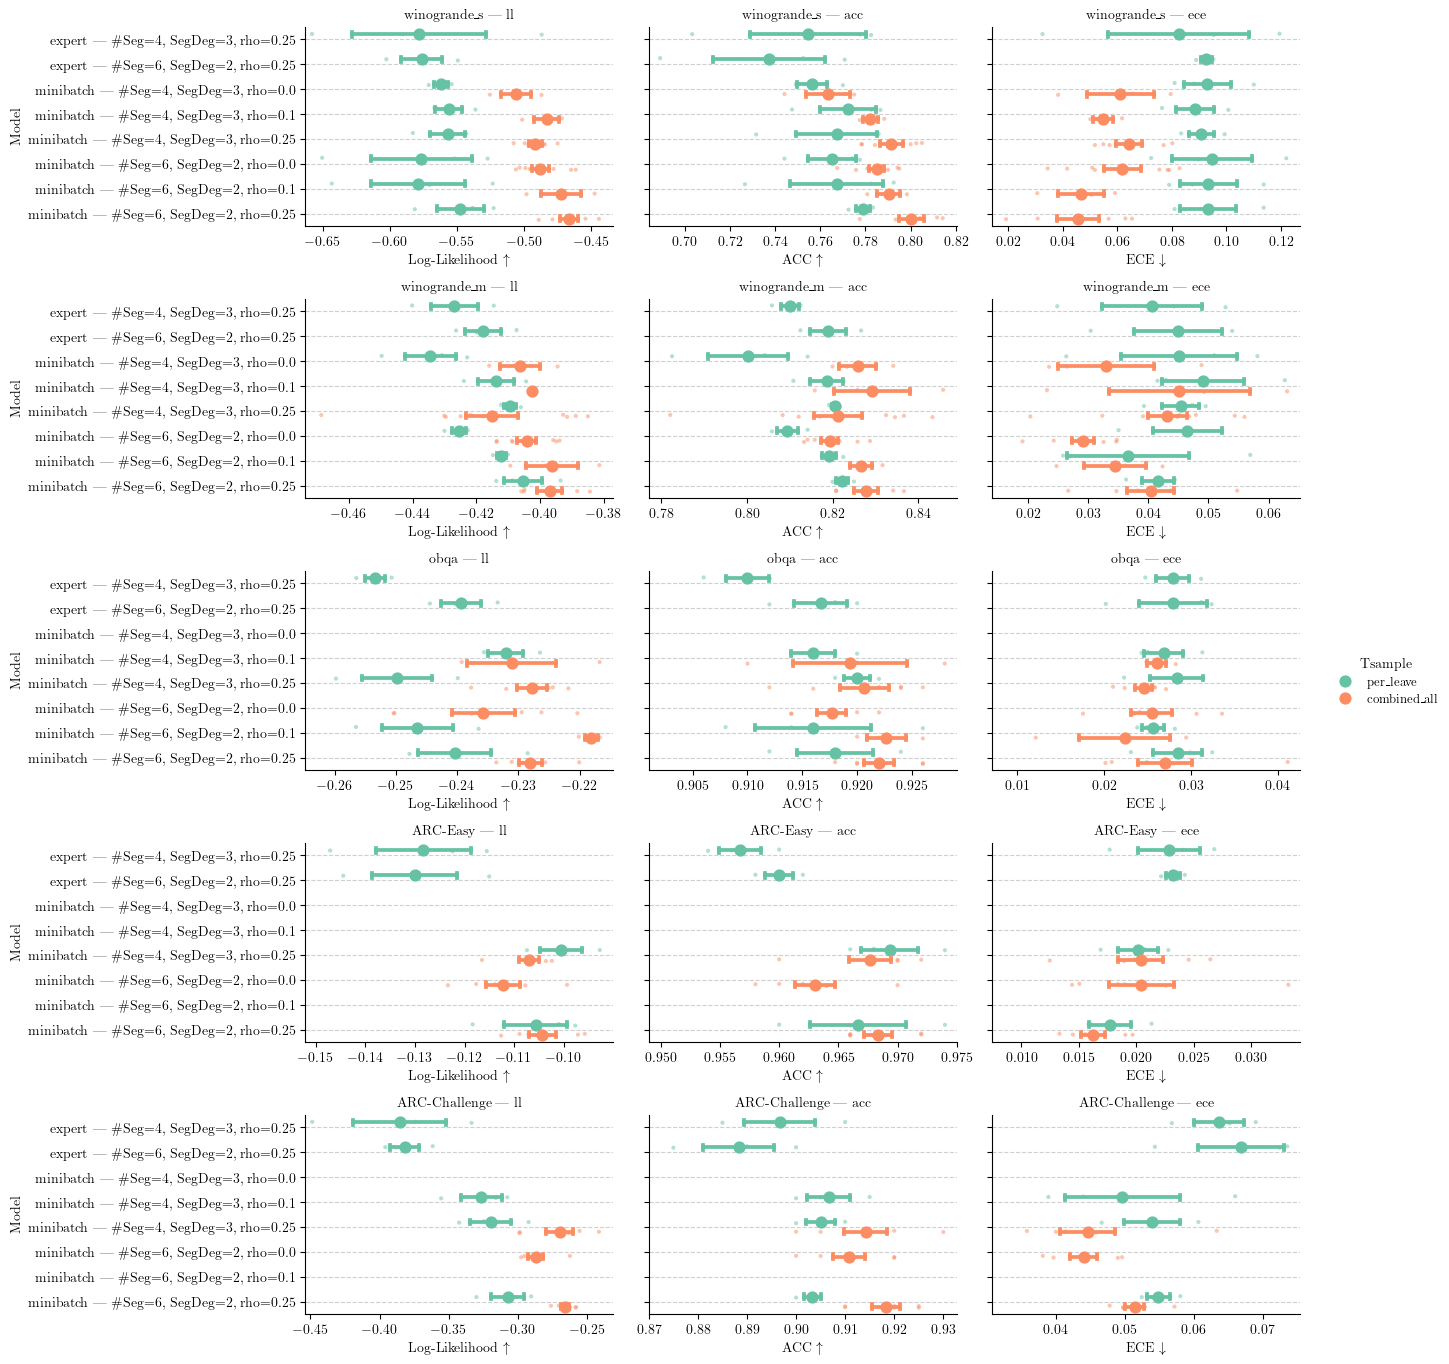

In [41]:
# stack df_vi to df_plot
df_plot_ = pd.concat([df_plot,], ignore_index=True)
# remove duplicates
df_plot_ = df_plot_.groupby(variable_idx+['Model', 'Seed', 'Metric'])['value'].mean().reset_index()

# hue
hue_name = 'Tsample'
hue_order = df_plot_[hue_name].unique()
hue_palette = sns.color_palette("Set2", n_colors=len(hue_order))
col_order = "ll", "acc", "ece"
row_order = "winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge",
order = df_plot_['Model'].unique()
order.sort()

print(f"Models {set(df_plot_['Model'].unique()) - set(order)} missing:")

g = sns.catplot(
    data=df_plot_, x='value', y='Model',
    row='Dataset', col='Metric',
    row_order=row_order, col_order=col_order,
    order=order,
    kind='point', join=False, capsize=.2,
    markers='o', palette=hue_palette, hue=hue_name,
    dodge=0.4, sharex=False, height=figsize[0]/2, aspect=1.618,
    legend=True, errorbar="se", ) # hue_order=hue_order,)

# Overlay strip plots for original points (small, alpha=0.5)
for (ds, metric), ax in g.axes_dict.items():
    subset = df_plot_[(df_plot_['Dataset'] == ds) & (df_plot_['Metric'] == metric)]
    sns.stripplot(
        data=subset, x='value', y='Model',
        order=order,
        ax=ax, palette=hue_palette, alpha=0.5, size=3,
        dodge=0.4, hue=hue_name, legend=False, hue_order=hue_order,
    )
    
    # Refine grid and labels
    ax.grid(True, axis='y', linestyle='--', alpha=0.6)
    
    # Label mapping for x-axis
    if metric == 'acc':
        ax.set_xlabel(r'ACC $\uparrow$')
    elif metric == 'll':
        ax.set_xlabel(r'Log-Likelihood $\uparrow$')
    elif metric == 'ece':
        ax.set_xlabel(r'ECE $\downarrow$')

    # clip x-axis to range of min without MAP
    def only_finit(x):
        return x[np.isfinite(x)]
    min_value = only_finit(subset[subset['Model'] != 'MAP']['value']).min()
    mean_value_MAP = only_finit(subset[subset['Model'] == 'MAP']['value']).mean()
    if np.isfinite(min_value):
        ax.set_xlim(left=min(min_value, mean_value_MAP)-0.005)  # add some padding on the left

# Adjust layout and titles
g.set_titles(row_template='{row_name}', col_template='{col_name}')
g.tight_layout()
# g.add_legend(title='#CurveSegments')
# plt.savefig("result/performance_pointplot.png", dpi=300)
# plt.savefig("result/performance_pointplot.pdf", dpi=300)
plt.show()

In [42]:
# filter out only similar seed runs
df_plot_.groupby(variable_idx)['Seed'].unique()

Dataset        BmaMode      DS_Sampling  DS_Mode  DS_WindowSize  Tsample       LoraRho  CurveSegmentDegree  NCurveSegment
ARC-Challenge  PPD Uniform  expert       Random    4             per_leave     0.25     2                   6                                                       [1, 2, 20]
                                                                                        3                   4                                                       [1, 2, 20]
                            minibatch    classic  -1             combined_all  0.00     2                   6                                [2, 40, 800, 16000, 32000, 64000]
                                                                               0.25     2                   6                                [2, 40, 800, 16000, 32000, 64000]
                                                                                        3                   4                                [2, 40, 800, 16000, 32000, 64000]
   

Models set() missing:


/tmp/ipykernel_2274356/2605597187.py:17: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


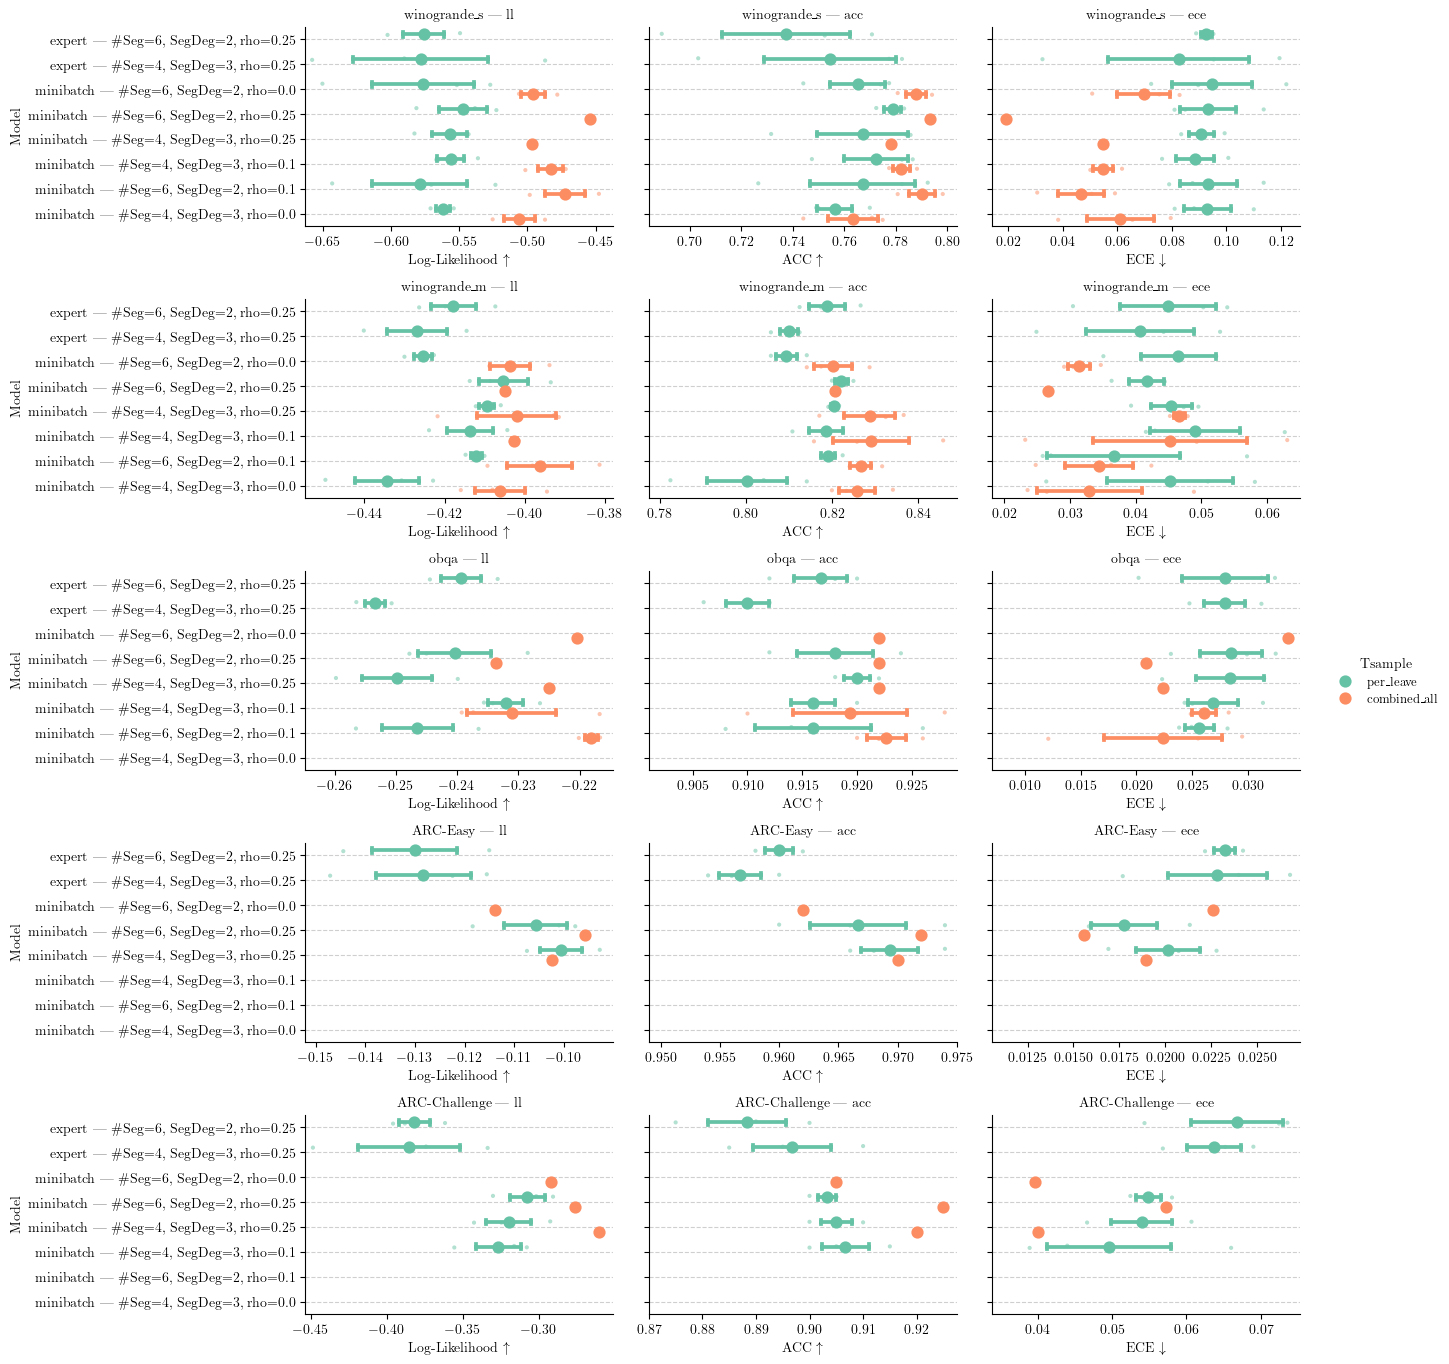

In [43]:
# stack df_vi to df_plot
df_plot_ = pd.concat([df_plot,], ignore_index=True)
df_plot_ = df_plot_.groupby(variable_idx+['Model', 'Seed', 'Metric'])['value'].mean().reset_index()
df_plot_ = df_plot_[df_plot_['Seed'].isin([1,2,20])]


# hue
hue_name = 'Tsample'
hue_order = df_plot_[hue_name].unique()
hue_palette = sns.color_palette("Set2", n_colors=len(hue_order))
col_order = "ll", "acc", "ece"
row_order = "winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge",
order = df_plot_['Model'].unique()

print(f"Models {set(df_plot_['Model'].unique()) - set(order)} missing:")

g = sns.catplot(
    data=df_plot_, x='value', y='Model',
    row='Dataset', col='Metric',
    row_order=row_order, col_order=col_order,
    order=order,
    kind='point', join=False, capsize=.2,
    markers='o', palette=hue_palette, hue=hue_name,
    dodge=0.4, sharex=False, height=figsize[0]/2, aspect=1.618,
    legend=True, errorbar="se", ) # hue_order=hue_order,)

# Overlay strip plots for original points (small, alpha=0.5)
for (ds, metric), ax in g.axes_dict.items():
    subset = df_plot_[(df_plot_['Dataset'] == ds) & (df_plot_['Metric'] == metric)]
    sns.stripplot(
        data=subset, x='value', y='Model',
        order=order,
        ax=ax, palette=hue_palette, alpha=0.5, size=3,
        dodge=0.4, hue=hue_name, legend=False, hue_order=hue_order,
    )
    
    # Refine grid and labels
    ax.grid(True, axis='y', linestyle='--', alpha=0.6)
    
    # Label mapping for x-axis
    if metric == 'acc':
        ax.set_xlabel(r'ACC $\uparrow$')
    elif metric == 'll':
        ax.set_xlabel(r'Log-Likelihood $\uparrow$')
    elif metric == 'ece':
        ax.set_xlabel(r'ECE $\downarrow$')

    # clip x-axis to range of min without MAP
    def only_finit(x):
        return x[np.isfinite(x)]
    min_value = only_finit(subset[subset['Model'] != 'MAP']['value']).min()
    mean_value_MAP = only_finit(subset[subset['Model'] == 'MAP']['value']).mean()
    if np.isfinite(min_value):
        ax.set_xlim(left=min(min_value, mean_value_MAP)-0.005)  # add some padding on the left

# Adjust layout and titles
g.set_titles(row_template='{row_name}', col_template='{col_name}')
g.tight_layout()
# g.add_legend(title='#CurveSegments')
# plt.savefig("result/performance_pointplot.png", dpi=300)
# plt.savefig("result/performance_pointplot.pdf", dpi=300)
plt.show()

### table

In [9]:
import wandb
from tqdm import tqdm
from copy import deepcopy
import numpy as np

api = wandb.Api()
results = []


for s in set(["w0kaq8i0", 'we8wq8n7', 'solftkne', 'kru2lo9d', '5wyd4ltr', 'awz62bg6', 'cb9soeli']): # + flat lora winogrande_m training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC_newDS/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        mp = run.config['model_params']
        opt_conf = run.config['optimizer_conf']
        hp = run.config['train_hyper']
        lora = mp['lora_params']

        NCurveSegment = mp['num_curve_segment']
        CurveDegree = mp['SegDeg']
        res = dict(Id=run.id,
        #    CurveSpace=f"{mp['k']}",
            # CurveSpace=len(mp['cp_fix']),
            CurveSpace=NCurveSegment * CurveDegree,
            # CpFix=str(mp['cp_fix']),
            NumPretrained=NCurveSegment + 1 if mp['Pretraining'] else 0,
            Jitter=mp['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=opt_conf['kwargs']['weight_decay'],
            Dataset="_".join(run.config['data']['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            BmaMode="PPD",
            DS_Sampling=list(hp.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(hp['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=hp['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=mp.get('entropy_maxim', -1),
            NumSteps=hp.get('num_steps', -1),
            LoraMode=lora.get('lora_mode', 'None'),
            CurveMode=mp.get('curve_parameterization', 'Bezier'),
            LoraRank=lora.get('r', -1),
            RegularizationMode=mp.get('regularizer', False),
            Gravity=mp.get('gravity', 0.),
            EnergyWeakening=mp.get('energy_weakening', 0.),
            Tsample=mp.get('curve_sampling_mode', 'None'),
            LoraRho=lora.get('lora_rho', -1),
            LoraRhoS=lora.get('lora_rho_s', -1),
            RhoFrequency=lora.get('rho_scheduler_frequency', 0),
            CurveSegmentDegree=CurveDegree,
            NCurveSegment=NCurveSegment,
            OpenEndSegment=mp.get('independent_connected', False),
            ModelMode=mp.get('subspace_model', 'None'),
            N=NCurveSegment + 1,
            M=CurveDegree - 1,
            N_cps = NCurveSegment * CurveDegree + 1,
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"test_ppd_acc", -np.inf),
            ece=run.summary.get(f"test_ppd_ece", -np.inf),
            ll=run.summary.get(f"test_ppd_ll", -np.inf),
            brier=run.summary.get(f"test_ppd_brier", -np.inf),
            test_mean_entropy_ppd=run.summary.get(f"test_ppd_weighted_mean_entropy", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_ppd_weighted_mutual_information", -np.inf),
            test_std_entropy_along_curve=0,
            test_mean_entropy_along_curve=0,
            )
        results.append(res)
        if mp['Pretraining']:
            # add DE   
            _res = deepcopy(res)
            _res['BmaMode'] = "DE"
            _res['acc'] = run.summary.get(f"test_DE_acc", -np.inf)
            _res['ece'] = run.summary.get(f"test_DE_ece", -np.inf)
            _res['ll'] = run.summary.get(f"test_DE_ll", -np.inf)
            _res['brier']=run.summary.get(f"test_DE_brier", -np.inf)
            _res['test_mean_entropy_ppd']=run.summary.get(f"test_DE_uniform_mean_entropy", -np.inf)
            _res['test_mutual_information_ppd']=run.summary.get(f"test_DE_uniform_mutual_information", -np.inf)
            _res['test_std_entropy_along_curve']=run.summary.get(f"test_DE_uniform_std_entropy_along_curve", -np.inf)
            _res['test_mean_entropy_along_curve']=run.summary.get(f"test_DE_uniform_mean_entropy_along_curve", -np.inf)
            _res['M'] = 0
            results.append(_res)
            for k in run.summary.keys():
                if k.startswith("cp_fixed_") and k.endswith("_test_acc"):
                    i = k.split("_")[2]
                    _res = deepcopy(res)
                    _res['BmaMode'] = "MAP"
                    # print(run.summary.get(f"cp_fixed_{i}_test_acc", -np.inf))
                    _res['acc'] = run.summary.get(f"cp_fixed_{i}_test_acc", -np.inf)
                    _res['ece'] = run.summary.get(f"cp_fixed_{i}_test_ece", -np.inf)
                    _res['ll'] = run.summary.get(f"cp_fixed_{i}_test_ll", -np.inf)
                    _res['brier']=run.summary.get(f"cp_fixed_{i}_test_brier", -np.inf)
                    _res['test_mean_entropy_ppd']=run.summary.get(f"cp_fixed_{i}_test_entropy", -np.inf)
                    _res['test_mutual_information_ppd']=0
                    _res['test_std_entropy_along_curve']=0
                    _res['test_mean_entropy_along_curve']=0
                    _res['M'] = 0
                    _res['N'] = 1
                    # print(_res['acc'], _res['ece'], _res['ll'])
                    results.append(_res)

        # add PPD uniform   
        _res = deepcopy(res)
        _res['BmaMode'] = "PPD Uniform"
        _res['acc'] = run.summary.get(f"test_ppd_uniform_acc", -np.inf)
        _res['ece'] = run.summary.get(f"test_ppd_uniform_ece", -np.inf)
        _res['ll'] = run.summary.get(f"test_ppd_uniform_ll", -np.inf)
        _res['brier']=run.summary.get(f"test_ppd_uniform_brier", -np.inf)
        _res['test_mean_entropy_ppd']=run.summary.get(f"test_ppd_uniform_mean_entropy", -np.inf)
        _res['test_mutual_information_ppd']=run.summary.get(f"test_ppd_uniform_mutual_information", -np.inf)
        _res['test_std_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_std_entropy_along_curve", -np.inf)
        _res['test_mean_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_mean_entropy_along_curve", -np.inf)
        results.append(_res)
 
df = pd.DataFrame(results)
df.describe().T

w0kaq8i0:   0%|          | 0/200 [00:00<?, ?it/s, fresh-sweep-181]   

cb9soeli: 100%|██████████| 5/5 [00:00<00:00, 1188.86it/s, graceful-sweep-1]
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/numpy/lib/function_base.py:4655: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


,count,mean,std,min,25%,50%,75%,max
CurveSpace,3350.0,9.865672e+00,7.209478e+00,2.000000e+00,4.000000,8.000000,16.000000,24.000000
NumPretrained,3350.0,4.417910e+00,3.468707e+00,0.000000e+00,2.000000,5.000000,9.000000,9.000000
Jitter,3350.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000
Seed,3350.0,1.684600e+03,3.161833e+03,1.000000e+00,2.000000,20.000000,400.000000,8000.000000
WeightDecay,3350.0,1.000000e-03,4.337456e-19,1.000000e-03,0.001000,0.001000,0.001000,0.001000
DS_WindowSize,3350.0,-1.000000e+00,0.000000e+00,-1.000000e+00,-1.000000,-1.000000,-1.000000,-1.000000
EntropyMaxScale,3350.0,-1.000000e+00,0.000000e+00,-1.000000e+00,-1.000000,-1.000000,-1.000000,-1.000000
NumSteps,3350.0,1.000000e+04,0.000000e+00,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000
LoraRank,3350.0,8.000000e+00,0.000000e+00,8.000000e+00,8.000000,8.000000,8.000000,8.000000
Gravity,3350.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000


In [10]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [24 12  6  3 16  4  8  2]
NumPretrained [9 5 3 2 0]
Jitter [0]
Seed [8000  400    2    1   20]
WeightDecay [0.001]
Dataset ['boolq' 'ARC-Easy' 'obqa' 'ARC-Challenge' 'winogrande_s' 'winogrande_m']
BmaMode ['PPD' 'DE' 'MAP' 'PPD Uniform']
DS_Sampling ['minibatch']
DS_Mode ['classic']
DS_WindowSize [-1]
EntropyMaxScale [-1]
NumSteps [10000]
LoraMode ['A(t)eB(t)']
CurveMode ['bezier']
LoraRank [8]
RegularizationMode [False]
Gravity [0]
EnergyWeakening [1]
Tsample ['combined_all']
LoraRho [0.25]
LoraRhoS [0]
RhoFrequency [50]
CurveSegmentDegree [3 2 1]
NCurveSegment [8 4 2 1]
OpenEndSegment [False]
ModelMode ['lora_category' 'jsd_v2_category']
N [9 1 5 3 2]
M [2 0 1]
N_cps [25 13  7  4 17  5  9  3]

Experiment differs in ['CurveSpace', 'NumPretrained', 'Dataset', 'BmaMode', 'CurveSegmentDegree', 'NCurveSegment', 'ModelMode', 'N', 'M', 'N_cps'] configs


array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

In [20]:
df_subset = df_clean.copy()
df_plot = df_subset.melt(id_vars=idx_ids, value_vars=value_ids, var_name='Metric', value_name='value')
df_plot['Config'] = df_plot.apply(lambda r: " | ".join([f"{k}={r[k]}" for k in variable_idx if k not in ['CurveSpace', 'NCurveSegment', 'NumPretrained', 'Dataset', 'BmaMode']]), axis=1)


df_plot = df_plot[(df_plot['BmaMode'] != 'PPD') & (df_plot['LoraMode'] == "A(t)eB(t)")]
# df_plot = df_plot[(df_plot['BmaMode'] == 'PPD Uniform') & (df_plot['Dataset'] == "winogrande_m") & (df_plot['Metric'] == "ll") & (df_plot['LoraMode'] == "A(t)eB(t)")]
df_plot = df_plot[(df_plot['LoraRho'] == 0.25)]
# df_plot = df_plot[df_plot['Metric'].isin(["ll", "acc", "ece"])]


def map_model(x):
    if x['BmaMode'] == 'MAP':
        return "MAP"
    elif x['BmaMode'] == 'DE':
        return f"DE({x['NumPretrained']})"
    elif x['BmaMode'] == 'PPD Uniform':
        is_fixed = x['NumPretrained'] > 0
        seg_deg = x['CurveSegmentDegree']
        
        if seg_deg == 1:
            prefix = "Lin" if is_fixed else "Linear_FLC"
            return f"{prefix}({x['NumPretrained']})"
        else:
            prefix = "ALC" if is_fixed else "FLC"
            name = f"{prefix}({x['N']},{x['M']})"
            if x['ModelMode'] != "lora_category":
                name += f"+JSD"
            return name
    else:
        return "None"

df_plot['Model'] = df_plot.apply(map_model, axis=1)
# set NCurveSegment to 0 for MAP and DE
df_plot.loc[df_plot['BmaMode'] == 'MAP', 'NCurveSegment'] = 0
df_plot.loc[df_plot['BmaMode'] == 'DE', 'NCurveSegment'] = 0

# df_plot = pd.concat([df_plot, df_vi, df_sampling], ignore_index=True)
df_plot = pd.concat([df_plot, df_vi,], ignore_index=True)

df_plot.loc[df_plot['Model'] == 'Sampling-PSMILE', 'Model'] = 'MCMC'
df_plot.sort_values(by=['Model'], inplace=True)

# rename Metric value test_mutual_information_ppd to mi
df_plot.loc[df_plot['Metric'] == 'test_mutual_information_ppd', 'Metric'] = 'MI'


# df_plot['NCurveSegment'] = pd.Categorical(df_plot['NCurveSegment'], categories=sorted(df_plot['NCurveSegment'].unique()), ordered=True)

In [12]:
df_plot[df_plot['Dataset'] == 'boolq']['Model'].unique()

array(['ALC(2,1)', 'ALC(2,2)', 'ALC(3,1)', 'ALC(3,2)', 'ALC(5,1)',
       'ALC(5,2)', 'ALC(9,1)', 'ALC(9,2)', 'BLoB', 'DE(2)', 'DE(3)',
       'DE(5)', 'DE(9)', 'FLC(9,2)', 'Lin(3)', 'MAP', 'ScalaBL'],
      dtype=object)

In [13]:
df_plot['Model'].unique()

array(['ALC(2,1)', 'ALC(2,2)', 'ALC(3,1)', 'ALC(3,2)', 'ALC(5,1)',
       'ALC(5,2)', 'ALC(9,1)', 'ALC(9,2)', 'BLoB', 'DE(2)', 'DE(3)',
       'DE(5)', 'DE(9)', 'FLC(2,1)', 'FLC(2,1)+JSD', 'FLC(2,2)',
       'FLC(2,2)+JSD', 'FLC(3,1)', 'FLC(3,1)+JSD', 'FLC(3,2)',
       'FLC(3,2)+JSD', 'FLC(5,1)', 'FLC(5,1)+JSD', 'FLC(5,2)',
       'FLC(5,2)+JSD', 'FLC(9,1)', 'FLC(9,1)+JSD', 'FLC(9,2)',
       'FLC(9,2)+JSD', 'Lin(3)', 'Lin(5)', 'Lin(9)', 'MAP', 'ScalaBL'],
      dtype=object)

In [21]:
df_plot['Metric'].unique()

array(['ece', 'acc', 'brier', 'test_mean_entropy_ppd', 'bezierLength',
       'll', 'MI', 'test_mean_entropy_along_curve',
       'test_std_entropy_along_curve'], dtype=object)

In [22]:
# Generate updated LaTeX table from the latest merged dataframe (df_plot)
from pathlib import Path
import numpy as np
import pandas as pd

if "df_plot" not in globals():
    raise RuntimeError("df_plot not found. Run the merge cell (sampling_scalabl_merge_01) first.")

datasets = ["ARC-Challenge", "ARC-Easy", "obqa", "winogrande_m", "winogrande_s", "boolq"]
metrics = ["acc", "ece", "ll", "brier"]
metrics = ["acc", "ece", "ll", ]
metrics = ["acc", "ece", "ll", "MI" ]
model_order = ['MAP', 
               'BLoB', 'ScalaBL',
               'Lin(3)', 
               'DE(3)', 'DE(9)', 
            #    '$\\bigcirc$Curve(\\#1, {seg_deg_name}2)', '$\\bigcirc$Curve(\\#1, {seg_deg_name}2)+JSD', '$\\triangle$Curve(\\#1, {seg_deg_name}2)',
               f'ALC(2,1)',
               f'ALC(3,2)', f'FLC(3,2)',
               f'ALC(5,2)', f'FLC(5,2)',
               f'ALC(9,2)', f'FLC(9,2)',
            #    'MCMC'
]

df_tbl = df_plot.copy()
df_tbl = df_tbl[df_tbl["Metric"].isin(metrics) & df_tbl["Dataset"].isin(datasets)].copy()
df_tbl = df_tbl[df_tbl["Model"].isin(model_order)]
df_tbl = df_tbl[np.isfinite(df_tbl["value"])]
df_tbl.loc[(df_tbl["Model"] == "MCMC") & (df_tbl["Metric"] == "ece"), 'value'] = np.inf

grp = df_tbl.groupby(["Metric", "Model", "Dataset"])["value"]
mean = grp.mean()
std2 = 2 * grp.std()

def fmt_plain(m, s):
    if pd.isna(m) or not np.isfinite(m):
        return "-"
    if pd.isna(s):
        return f"{m:.3f}"
    return f"{m:.3f} $\\pm$ {s:.3f}"

def is_better(metric, candidate, current):
    if pd.isna(current):
        return True
    if (metric == "ece") or (metric == "brier"):
        return candidate < current
    return candidate > current

best_map = {}
for metric in metrics:
    for ds in datasets:
        best_val = np.nan
        for model in model_order:
            v = mean.get((metric, model, ds), np.nan)
            if pd.isna(v) or not np.isfinite(v):
                continue
            if is_better(metric, v, best_val):
                best_val = v
        best_map[(metric, ds)] = best_val

def mark_text(metric, model, ds):
    m = mean.get((metric, model, ds), np.nan)
    s = std2.get((metric, model, ds), np.nan)
    text = fmt_plain(m, s)
    if text == "-":
        return text

    best_val = best_map.get((metric, ds), np.nan)
    if pd.isna(best_val):
        return text

    if np.isclose(m, best_val, rtol=1e-12, atol=1e-12):
        # return f"\\textbf{{\\underline{{{text}}}}}"
        return f"\\textbf{{{text}}}"

    low = m - s if pd.notna(s) else m
    high = m + s if pd.notna(s) else m
    if low <= best_val <= high:
        return f"\\underline{{{text}}}"
    return text

# Helper to format N and m cleanly, replacing missing with em-dash
def format_nm(val):
    if pd.isna(val) or val == "" or val == "-":
        return "---"
    if isinstance(val, float) and val.is_integer():
        return str(int(val))
    return str(val)

rows = []
for metric in metrics:
    for model in model_order:
        row = {"Metric": metric, "Model": model}
        
        # Extract N and m parameters dynamically from the dataframe
        subset = df_tbl[df_tbl["Model"] == model]
        n_col = "N" if "N" in subset.columns else "n" if "n" in subset.columns else None
        m_col = "M" if "M" in subset.columns else "m" if "m" in subset.columns else None
        
        n_val = subset[n_col].dropna().iloc[0] if n_col and not subset[n_col].dropna().empty else "---"
        m_val = subset[m_col].dropna().iloc[0] if m_col and not subset[m_col].dropna().empty else "---"
        
        row["N"] = format_nm(n_val)
        row["m"] = format_nm(m_val)

        any_present = False
        for ds in datasets:
            plain = fmt_plain(mean.get((metric, model, ds), np.nan), std2.get((metric, model, ds), np.nan))
            row[ds] = mark_text(metric, model, ds)
            if plain != "-":
                any_present = True
        if any_present:
            rows.append(row)

df_table = pd.DataFrame(rows)
out_csv = "result/performance_table.csv"
Path(out_csv).parent.mkdir(parents=True, exist_ok=True) # Ensure directory exists
df_table.to_csv(out_csv, index=False)

# Build LaTeX table block
def esc(s):
    s = str(s)
    if not '$' in s:
        s = s.replace("_", "\\_")
    s = s.replace("&", "\\&")
    s = s.replace("%", "\\%")
    return s

def name_metric(m):
    if m == "acc":
        return "ACC $\\uparrow$"
    elif m == "ece":
        return "ECE $\\downarrow$"
    elif m == "ll":
        return "LL $\\uparrow$"
    elif m == "brier":
        return "Brier Score $\\downarrow$"
    elif m == "MI":
        return "MI $\\uparrow$"
    else:
        return esc(m)

lines = []
lines.append("\\begin{table*}[htbp]")
lines.append("\\centering")
lines.append("\\caption{Performance comparison of Bayesian Model Averaging (BMA) strategies. Evaluation of Accuracy (ACC $\\uparrow$), Expected Calibration Error (ECE $\\downarrow$), and Log-Likelihood (LL $\\uparrow$) across five datasets. $N$ denotes the number of anchor points, and $m$ represents the curve segment degree ($m=0$: discrete/linear, $m>0$: continuous curve). ALC (Anchored LoRA-Curve) uses frozen anchors from pretrained MAP solutions, while FLC (Free LoRA-Curve) jointly optimizes all control points. Results report the mean $\\pm$ $2\\sigma$ across available seeds. The best metric per dataset is \\textbf{bolded}, and models whose mean $\\pm$ $2\\sigma$ interval contains the best result are \\underline{underlined}. Notably, our continuous curve approaches (ALC and FLC) perform competitively with, and frequently outperform, discrete deep ensembles (DE) and baseline methods.}")
lines.append("\\label{tab:performance_metrics_updated}")
lines.append("\\resizebox{\\textwidth}{!}{%")
# Updated to 10 columns (llcccccccc) to account for N and m
lines.append("\\begin{tabular}{llcccccccc}")
lines.append("\\toprule")
# Added N and m to the headers
lines.append("\\textbf{Metric} & \\textbf{Model} & \\textbf{N} & \\textbf{m} & \\textbf{ARC-Challenge} & \\textbf{ARC-Easy} & \\textbf{obqa} & \\textbf{winogrande\\_m} & \\textbf{winogrande\\_s} & \\textbf{boolq} " + r"\\")
lines.append("\\midrule")

# Calculate row counts for each metric to use with \multirow
metric_counts = df_table["Metric"].value_counts()
seen_metrics = set()

for i, r in df_table.iterrows():
    metric = r["Metric"]
    
    # Add midrule between different metrics
    if i > 0 and metric != df_table.iloc[i - 1]["Metric"]:
        lines.append("\\midrule")
        
    # Group the Metric column using \multirow
    if metric not in seen_metrics:
        count = metric_counts[metric]
        metric_str = f"\\multirow{{{count}}}{{*}}{{{name_metric(metric)}}}"
        seen_metrics.add(metric)
    else:
        metric_str = "" # Leave blank for subsequent rows in the same group

    # Added r['N'] and r['m'] insertion directly into the row builder
    lines.append(
        f"{metric_str} & {esc(r['Model'])} & {r['N']} & {r['m']} & {r['ARC-Challenge']} & {r['ARC-Easy']} & {r['obqa']} & {r['winogrande_m']} & {r['winogrande_s']} & {r['boolq']} " + r"\\")

lines.append("\\bottomrule")
lines.append("\\end{tabular}%")
lines.append("}")
lines.append("\\end{table*}")

out_tex = "result/performance_table.tex"
Path(out_tex).write_text("\n".join(lines))

print(f"Saved table csv: {out_csv}")
print(f"Saved table tex: {out_tex}")
df_table

Saved table csv: result/performance_table.csv
Saved table tex: result/performance_table.tex


,Metric,Model,N,m,ARC-Challenge,ARC-Easy,obqa,winogrande_m,winogrande_s,boolq
0,acc,MAP,1,0,\underline{0.889 $\pm$ 0.021},0.962 $\pm$ 0.009,\underline{0.910 $\pm$ 0.016},\underline{0.820 $\pm$ 0.018},\underline{0.779 $\pm$ 0.030},\underline{0.892 $\pm$ 0.009}
1,acc,BLoB,---,---,\underline{0.907 $\pm$ 0.010},0.965 $\pm$ 0.006,\underline{0.917 $\pm$ 0.013},\underline{0.828 $\pm$ 0.011},0.788 $\pm$ 0.012,0.891 $\pm$ 0.004
2,acc,ScalaBL,---,---,\underline{0.902 $\pm$ 0.012},0.963 $\pm$ 0.003,0.912 $\pm$ 0.009,0.817 $\pm$ 0.007,0.787 $\pm$ 0.009,0.883 $\pm$ 0.005
3,acc,Lin(3),3,0,\underline{0.893 $\pm$ 0.021},0.966 $\pm$ 0.005,\underline{0.914 $\pm$ 0.013},0.823 $\pm$ 0.009,\underline{0.773 $\pm$ 0.040},\underline{0.894 $\pm$ 0.009}
4,acc,DE(3),3,0,\underline{0.897 $\pm$ 0.016},0.964 $\pm$ 0.005,\underline{0.920 $\pm$ 0.012},\underline{0.835 $\pm$ 0.018},\underline{0.787 $\pm$ 0.029},\underline{0.895 $\pm$ 0.006}
5,acc,DE(9),9,0,\underline{0.902 $\pm$ 0.011},\underline{0.970 $\pm$ 0.005},\underline{0.923 $\pm$ 0.011},\textbf{0.838 $\pm$ 0.013},\underline{0.797 $\pm$ 0.016},\underline{0.897 $\pm$ 0.003}
6,acc,"ALC(2,1)",2,1,\underline{0.896 $\pm$ 0.018},0.965 $\pm$ 0.006,\underline{0.919 $\pm$ 0.008},\underline{0.833 $\pm$ 0.018},0.790 $\pm$ 0.015,\textbf{0.900 $\pm$ 0.005}
7,acc,"ALC(3,2)",3,2,\underline{0.898 $\pm$ 0.010},\underline{0.967 $\pm$ 0.006},\underline{0.921 $\pm$ 0.015},\underline{0.835 $\pm$ 0.012},\underline{0.798 $\pm$ 0.024},\underline{0.899 $\pm$ 0.005}
8,acc,"FLC(3,2)",3,2,\underline{0.898 $\pm$ 0.015},\underline{0.966 $\pm$ 0.009},\underline{0.922 $\pm$ 0.006},\underline{0.833 $\pm$ 0.017},\underline{0.796 $\pm$ 0.019},-
9,acc,"ALC(5,2)",5,2,0.898 $\pm$ 0.010,\textbf{0.971 $\pm$ 0.008},\textbf{0.924 $\pm$ 0.006},\underline{0.838 $\pm$ 0.007},\underline{0.801 $\pm$ 0.011},\underline{0.898 $\pm$ 0.006}


### Compare JSD v2

5wyd4ltr

In [91]:
import wandb
from tqdm import tqdm
from copy import deepcopy
import numpy as np

api = wandb.Api()
results = []


for s in set(["qwen_PtoC_newDS/w0kaq8i0", "qwen_PtoC_newDS/5wyd4ltr", "qwen_PtoC_test/jmwlnoc9"]): # + flat lora winogrande_m training 
    t_run = tqdm(api.sweep(f"ddold/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        mp = run.config['model_params']
        opt_conf = run.config['optimizer_conf']
        hp = run.config['train_hyper']
        lora = mp['lora_params']

        NCurveSegment = mp['num_curve_segment']
        CurveDegree = mp['SegDeg']
        res = dict(Id=run.id,
        #    CurveSpace=f"{mp['k']}",
            # CurveSpace=len(mp['cp_fix']),
            CurveSpace=NCurveSegment * CurveDegree,
            # CpFix=str(mp['cp_fix']),
            NumPretrained=NCurveSegment + 1 if mp['Pretraining'] else 0,
            Jitter=mp['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=opt_conf['kwargs']['weight_decay'],
            Dataset="_".join(run.config['data']['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            BmaMode="PPD",
            DS_Sampling=list(hp.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(hp['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=hp['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=mp.get('entropy_maxim', -1),
            NumSteps=hp.get('num_steps', -1),
            LoraMode=lora.get('lora_mode', 'None'),
            CurveMode=mp.get('curve_parameterization', 'Bezier'),
            LoraRank=lora.get('r', -1),
            RegularizationMode=mp.get('regularizer', False),
            Gravity=mp.get('gravity', 0.),
            EnergyWeakening=mp.get('energy_weakening', 0.),
            Tsample=mp.get('curve_sampling_mode', 'None'),
            LoraRho=lora.get('lora_rho', -1),
            LoraRhoS=lora.get('lora_rho_s', -1),
            RhoFrequency=lora.get('rho_scheduler_frequency', 0),
            CurveSegmentDegree=CurveDegree,
            NCurveSegment=NCurveSegment,
            OpenEndSegment=mp.get('independent_connected', False),
            ModelMode=mp.get('subspace_model', 'None'),
            N=NCurveSegment + 1,
            M=CurveDegree - 1,
            N_cps = NCurveSegment * CurveDegree + 1,
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"test_ppd_acc", -np.inf),
            ece=run.summary.get(f"test_ppd_ece", -np.inf),
            ll=run.summary.get(f"test_ppd_ll", -np.inf),
            brier=run.summary.get(f"test_ppd_brier", -np.inf),
            test_mean_entropy_ppd=run.summary.get(f"test_ppd_weighted_mean_entropy", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_ppd_weighted_mutual_information", -np.inf),
            test_std_entropy_along_curve=0,
            test_mean_entropy_along_curve=0,
            )
        results.append(res)
        if mp['Pretraining']:
            # add DE   
            _res = deepcopy(res)
            _res['BmaMode'] = "DE"
            _res['acc'] = run.summary.get(f"test_DE_acc", -np.inf)
            _res['ece'] = run.summary.get(f"test_DE_ece", -np.inf)
            _res['ll'] = run.summary.get(f"test_DE_ll", -np.inf)
            _res['brier']=run.summary.get(f"test_DE_brier", -np.inf)
            _res['test_mean_entropy_ppd']=run.summary.get(f"test_DE_uniform_mean_entropy", -np.inf)
            _res['test_mutual_information_ppd']=run.summary.get(f"test_DE_uniform_mutual_information", -np.inf)
            _res['test_std_entropy_along_curve']=run.summary.get(f"test_DE_uniform_std_entropy_along_curve", -np.inf)
            _res['test_mean_entropy_along_curve']=run.summary.get(f"test_DE_uniform_mean_entropy_along_curve", -np.inf)
            results.append(_res)
            for k in run.summary.keys():
                if k.startswith("cp_fixed_") and k.endswith("_test_acc"):
                    i = k.split("_")[2]
                    _res = deepcopy(res)
                    _res['BmaMode'] = "MAP"
                    # print(run.summary.get(f"cp_fixed_{i}_test_acc", -np.inf))
                    _res['acc'] = run.summary.get(f"cp_fixed_{i}_test_acc", -np.inf)
                    _res['ece'] = run.summary.get(f"cp_fixed_{i}_test_ece", -np.inf)
                    _res['ll'] = run.summary.get(f"cp_fixed_{i}_test_ll", -np.inf)
                    _res['brier']=run.summary.get(f"cp_fixed_{i}_test_brier", -np.inf)
                    _res['test_mean_entropy_ppd']=run.summary.get(f"cp_fixed_{i}_test_entropy", -np.inf)
                    _res['test_mutual_information_ppd']=0
                    _res['test_std_entropy_along_curve']=0
                    _res['test_mean_entropy_along_curve']=0
                    # print(_res['acc'], _res['ece'], _res['ll'])
                    results.append(_res)

        # add PPD uniform   
        _res = deepcopy(res)
        _res['BmaMode'] = "PPD Uniform"
        _res['acc'] = run.summary.get(f"test_ppd_uniform_acc", -np.inf)
        _res['ece'] = run.summary.get(f"test_ppd_uniform_ece", -np.inf)
        _res['ll'] = run.summary.get(f"test_ppd_uniform_ll", -np.inf)
        _res['brier']=run.summary.get(f"test_ppd_uniform_brier", -np.inf)
        _res['test_mean_entropy_ppd']=run.summary.get(f"test_ppd_uniform_mean_entropy", -np.inf)
        _res['test_mutual_information_ppd']=run.summary.get(f"test_ppd_uniform_mutual_information", -np.inf)
        _res['test_std_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_std_entropy_along_curve", -np.inf)
        _res['test_mean_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_mean_entropy_along_curve", -np.inf)
        results.append(_res)

 
df = pd.DataFrame(results)
df.describe().T

qwen_PtoC_newDS/w0kaq8i0:   0%|          | 0/200 [00:00<?, ?it/s, revived-sweep-176] 

qwen_PtoC_test/jmwlnoc9: 100%|██████████| 75/75 [00:00<00:00, 377.36it/s, astral-sweep-1]     
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,count,mean,std,min,25%,50%,75%,max
CurveSpace,950.0,9.789474e+00,6.577566e+00,2.000000e+00,4.000000,8.000000,12.000000,24.000000
NumPretrained,950.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000
Jitter,950.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000
Seed,950.0,1.684600e+03,3.163026e+03,1.000000e+00,2.000000,20.000000,400.000000,8000.000000
WeightDecay,950.0,1.000000e-03,4.339093e-19,1.000000e-03,0.001000,0.001000,0.001000,0.001000
DS_WindowSize,950.0,-1.000000e+00,0.000000e+00,-1.000000e+00,-1.000000,-1.000000,-1.000000,-1.000000
EntropyMaxScale,950.0,-1.000000e+00,0.000000e+00,-1.000000e+00,-1.000000,-1.000000,-1.000000,-1.000000
NumSteps,950.0,1.000000e+04,0.000000e+00,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000
LoraRank,950.0,8.000000e+00,0.000000e+00,8.000000e+00,8.000000,8.000000,8.000000,8.000000
Gravity,950.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000


In [92]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [24 12  6  3 16  8  4  2]
NumPretrained [0]
Jitter [0]
Seed [8000  400   20    2    1]
WeightDecay [0.001]
Dataset ['ARC-Easy' 'ARC-Challenge' 'winogrande_s' 'obqa' 'winogrande_m']
BmaMode ['PPD' 'PPD Uniform']
DS_Sampling ['minibatch']
DS_Mode ['classic']
DS_WindowSize [-1]
EntropyMaxScale [-1]
NumSteps [10000]
LoraMode ['A(t)eB(t)']
CurveMode ['bezier']
LoraRank [8]
RegularizationMode [False]
Gravity [0]
EnergyWeakening [1]
Tsample ['combined_all']
LoraRho [0.25]
LoraRhoS [0]
RhoFrequency [50]
CurveSegmentDegree [3 2]
NCurveSegment [8 4 2 1]
OpenEndSegment [False]
ModelMode ['lora_category' 'jsd_v2_category' 'jsd_noise_sampling_dropout_category']
N [9 5 3 2]
M [2 1]
N_cps [25 13  7  4 17  9  5  3]

Experiment differs in ['CurveSpace', 'Dataset', 'BmaMode', 'CurveSegmentDegree', 'NCurveSegment', 'ModelMode', 'N', 'M', 'N_cps'] configs


array(['ARC-Challenge', 'ARC-Easy', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

In [93]:
df_subset = df_clean.copy()
df_plot = df_subset.melt(id_vars=idx_ids, value_vars=value_ids, var_name='Metric', value_name='value')
df_plot['Config'] = df_plot.apply(lambda r: " | ".join([f"{k}={r[k]}" for k in variable_idx if k not in ['CurveSpace', 'NCurveSegment', 'NumPretrained', 'Dataset', 'BmaMode',]]), axis=1)


df_plot = df_plot[(df_plot['BmaMode'] != 'PPD') & (df_plot['LoraMode'] == "A(t)eB(t)")]
# df_plot = df_plot[(df_plot['BmaMode'] == 'PPD Uniform') & (df_plot['Dataset'] == "winogrande_m") & (df_plot['Metric'] == "ll") & (df_plot['LoraMode'] == "A(t)eB(t)")]
df_plot = df_plot[(df_plot['LoraRho'] == 0.25)]
# df_plot = df_plot[df_plot['Metric'].isin(["ll", "acc", "ece"])]
    
def map_model(x):
    if x['BmaMode'] == 'MAP':
        return "MAP"
    elif x['BmaMode'] == 'DE':
        return f"DE({x['NumPretrained']})"
    elif x['BmaMode'] == 'PPD Uniform':
        is_fixed = x['NumPretrained'] > 0
        seg_deg = int(x['CurveSegmentDegree'])
        
        if seg_deg == 1:
            prefix = "Linear" if is_fixed else "Linear_" + free_model_name
            return f"{prefix}({x['NumPretrained']} )"
        else:
            prefix = pretrained_model_name if is_fixed else free_model_name
            return rf"{prefix}({x['N']},{x['M']})"
    else:
        return "None"

def map_hue(x):
    if (x['CurveSegmentDegree'] >= 1) and (x['BmaMode'] == 'PPD Uniform'):
        if x['ModelMode'] == 'jsd_v2_category':
            hue_name = "JSD"
        elif x['ModelMode'] == 'jsd_noise_sampling_dropout_category':
            hue_name = "JSD Drop"
        else:
            hue_name = "Orig."
        hue_name = f"{hue_name}({x['N']})"
    else:
        hue_name = "base"
    return hue_name

df_plot_ = pd.concat([df_plot, df_vi,], ignore_index=True)
df_plot_.fillna(-1, inplace=True)
df_plot_['N'] = df_plot_['N'].astype(int)
df_plot_['M'] = df_plot_['M'].astype(int)
df_plot_['Model'] = df_plot_.apply(map_model, axis=1)
df_plot_['Space'] = df_plot_.apply(map_hue, axis=1)
# set NCurveSegment to 0 for MAP and DE
df_plot_.loc[df_plot_['BmaMode'] == 'MAP', 'NCurveSegment'] = 0
df_plot_.loc[df_plot_['BmaMode'] == 'DE', 'NCurveSegment'] = 0

df_plot_.sort_values(by=['Model'], inplace=True)

# df_plot['NCurveSegment'] = pd.Categorical(df_plot['NCurveSegment'], categories=sorted(df_plot['NCurveSegment'].unique()), ordered=True)

In [94]:
df_plot_['Model'].unique()

array(['FLC(2,1)', 'FLC(2,2)', 'FLC(3,1)', 'FLC(3,2)', 'FLC(5,1)',
       'FLC(5,2)', 'FLC(9,1)', 'FLC(9,2)', 'None'], dtype=object)

In [95]:
df_plot_['Space'].unique()

array(['JSD(2)', 'Orig.(2)', 'Orig.(3)', 'JSD(3)', 'JSD(5)', 'Orig.(5)',
       'JSD Drop(5)', 'Orig.(9)', 'JSD(9)', 'base'], dtype=object)

Models {'None'} missing:


/tmp/ipykernel_2347890/3384385625.py:39: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


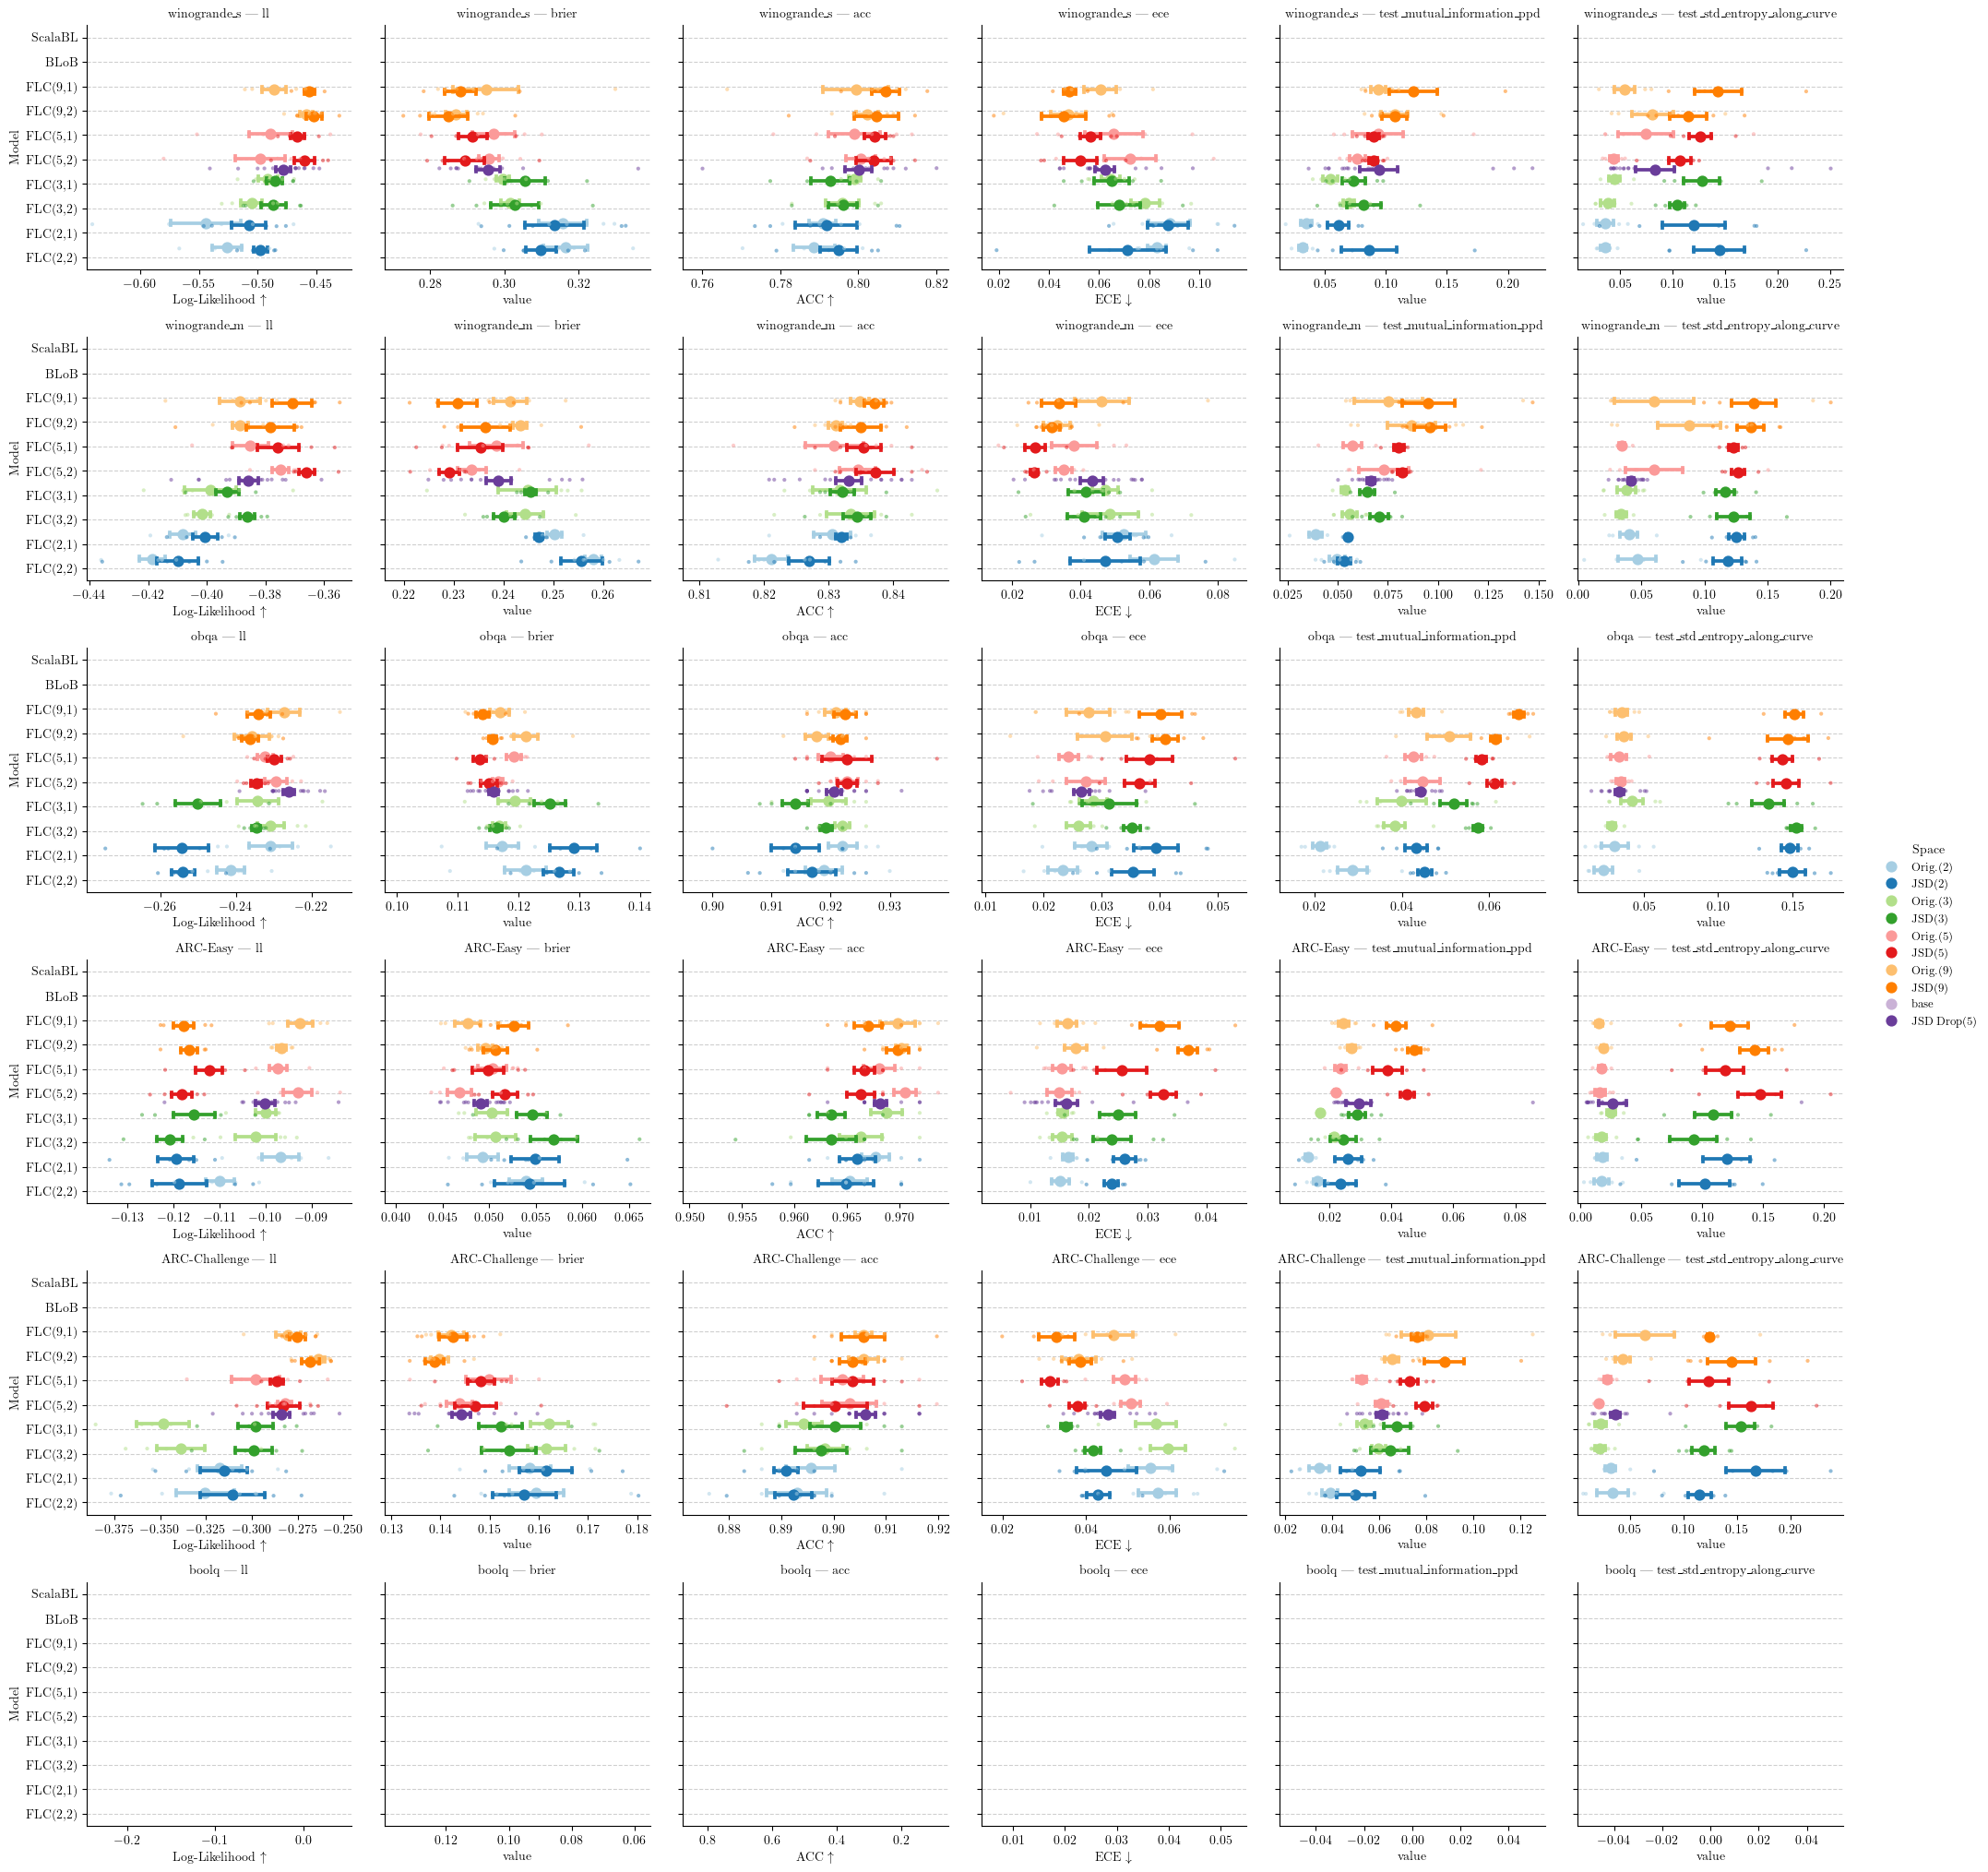

In [96]:
# stack df_vi to df_plot
hue_name = "Space"
hue_order = ['Orig.(2)', 'JSD(2)', 'Orig.(3)', 'JSD(3)', 'Orig.(5)', 'JSD(5)', 'Orig.(9)', 'JSD(9)', "base", "JSD Drop(5)"]
hue_palette = sns.color_palette("Paired")
hue_palette = {hue: hue_palette[i] for i, hue in enumerate(hue_order)}


col_order = "ll", "brier", "acc", "ece", "test_mutual_information_ppd", "test_std_entropy_along_curve"
row_order = "winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge", "boolq"
# order = df_plot_['Model'].unique()
order = [#'MAP', 
         'ScalaBL', 'BLoB', 
        #  'Linear(3)', 'Linear(5)', 'Linear(9)', #'OpenLinear(13)',
         f'{free_model_name}(9,1)',
         f'{free_model_name}(9,2)', 
         f'{free_model_name}(5,1)',
         f'{free_model_name}(5,2)',
         f'{free_model_name}(3,1)', 
         f'{free_model_name}(3,2)',  
         f'{free_model_name}(2,1)',
         f'{free_model_name}(2,2)', 
         ]

print(f"Models {set(df_plot_['Model'].unique()) - set(order)} missing:")

# # Prepare descriptive Model labels
# def get_model_label(row):
#     if str(row['Model']).startswith('DE'):
#         return f"{row['Model']}({row['NCurveSegment']})"
#     return f"{row['Model']}"

# df_plot_['Model_Label'] = df_plot_.apply(get_model_label, axis=1)

# # Ensure metric order
# metric_order = ['acc', 'll', 'ece']
# df_plot_['Metric'] = pd.Categorical(df_plot_['Metric'], categories=metric_order, ordered=True)

# Seaborn Catplot (ANOVA style)
g = sns.catplot(
    data=df_plot_, x='value', y='Model',
    row='Dataset', col='Metric',
    row_order=row_order, col_order=col_order,
    order=order,
    dodge=0.8,
    kind='point', join=False, capsize=.2,
    markers='o', palette=hue_palette, hue=hue_name,
    sharex=False, height=figsize[1], aspect=1.,
    legend=True, errorbar="se", hue_order=hue_order,
)

# Overlay strip plots for original points (small, alpha=0.5)
for (ds, metric), ax in g.axes_dict.items():
    subset = df_plot_[(df_plot_['Dataset'] == ds) & (df_plot_['Metric'] == metric)]
    sns.stripplot(
        data=subset, x='value', y='Model',
        order=order,
        dodge=0.8,
        ax=ax, palette=hue_palette, alpha=0.5, size=3,
        hue=hue_name, legend=False, hue_order=hue_order,
    )
    
    # Refine grid and labels
    ax.grid(True, axis='y', linestyle='--', alpha=0.6)

    # add vertical line at BLob mean value for reference
    subset_blob = subset[subset['Model'] == 'BLoB WB']
    if not subset_blob.empty and np.isfinite(subset_blob['value'].mean()):
        ax.axvline(x=subset_blob['value'].mean(), color='gray', linestyle='--', label='BLoB Mean')
    
    # Label mapping for x-axis
    if metric == 'acc':
        ax.set_xlabel(r'ACC $\uparrow$')
    elif metric == 'll':
        ax.set_xlabel(r'Log-Likelihood $\uparrow$')
    elif metric == 'ece':
        ax.set_xlabel(r'ECE $\downarrow$')

    # clip x-axis to range of min without MAP
    def only_finit(x):
        return x[np.isfinite(x)]
    min_value = only_finit(subset[subset['Model'] != 'MAP']['value']).min()
    mean_value_MAP = only_finit(subset[subset['Model'] == 'MAP']['value']).mean()
    if np.isfinite(min_value):
        ax.set_xlim(left=min(min_value, mean_value_MAP)-0.005)  # add some padding on the left

# Adjust layout and titles
g.set_titles(row_template='{row_name}', col_template='{col_name}')
g.tight_layout()
# g.add_legend(title='#CurveSegments')
# plt.savefig("result/performance_pointplot.png", dpi=300)
# plt.savefig("result/performance_pointplot.pdf", dpi=300)
plt.show()


Models {'FLC(5,1)', 'FLC(3,1)', 'FLC(2,1)', 'FLC(9,1)', 'None'} missing:


/tmp/ipykernel_2347890/3153904001.py:28: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


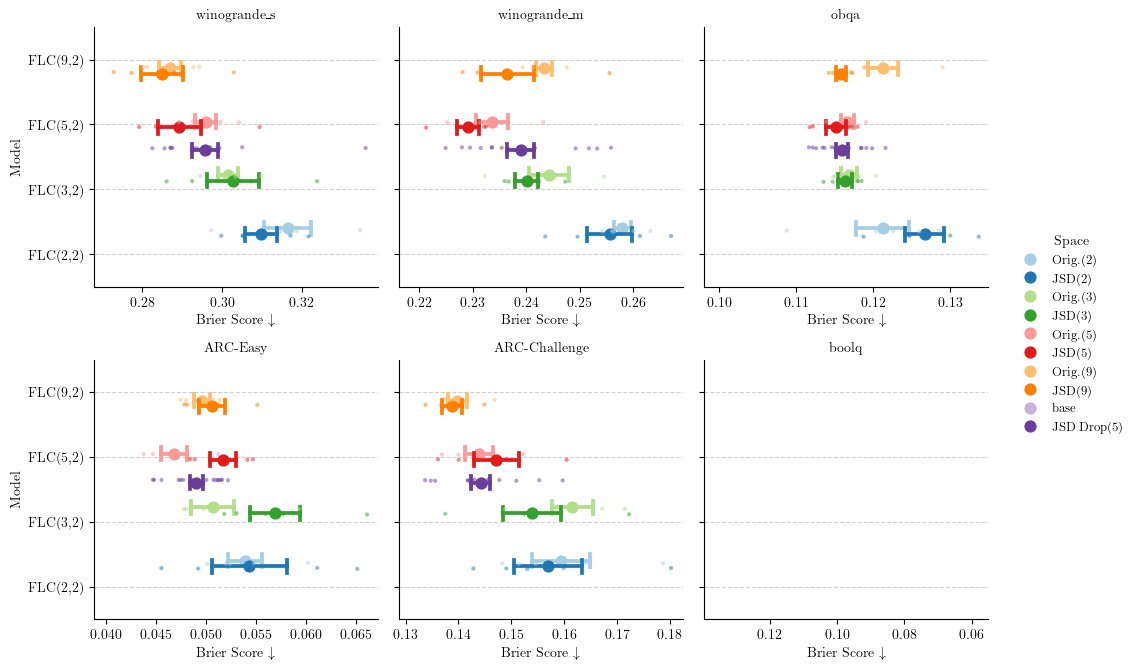

In [97]:
# stack df_vi to df_plot
hue_name = "Space"
metric = "brier"
hue_order = ['Orig.(2)', 'JSD(2)', 'Orig.(3)', 'JSD(3)', 'Orig.(5)', 'JSD(5)', 'Orig.(9)', 'JSD(9)', "base", "JSD Drop(5)"]
hue_palette = sns.color_palette("Paired")
hue_palette = {hue: hue_palette[i] for i, hue in enumerate(hue_order)}



# col_order = "ll", "brier", "acc", "ece", "test_mutual_information_ppd", "test_std_entropy_along_curve"
row_order = "winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge", "boolq"
# order = df_plot_['Model'].unique()
order = [#'MAP', 
        #  'ScalaBL', 'BLoB', 
         f'{free_model_name}(9,2)', 
         f'{free_model_name}(5,2)', 
         f'{free_model_name}(3,2)', 
         f'{free_model_name}(2,2)', 
        #  'Sampling-PSMILE', 'Sampling-SGHMC'
         ]

print(f"Models {set(df_plot_['Model'].unique()) - set(order)} missing:")


df_plot_subset = df_plot_[df_plot_['Metric'] == metric]

# Seaborn Catplot (ANOVA style)
g = sns.catplot(
    data=df_plot_subset, x='value', y='Model',
    col='Dataset', col_wrap=3,
    col_order=row_order,
    order=order,
    dodge=0.8,
    kind='point', join=False, capsize=.2,
    markers='o', palette=hue_palette, hue=hue_name,
    sharex=False, height=figsize[1], aspect=1.,
    legend=True, errorbar="se", hue_order=hue_order,
)

# Overlay strip plots for original points (small, alpha=0.5)
for ds, ax in g.axes_dict.items():
    subset = df_plot_subset[(df_plot_subset['Dataset'] == ds)]
    sns.stripplot(
        data=subset, x='value', y='Model',
        order=order,
        dodge=0.8,
        ax=ax, palette=hue_palette, alpha=0.5, size=3,
        hue=hue_name, legend=False, hue_order=hue_order,
    )
    
    # Refine grid and labels
    ax.grid(True, axis='y', linestyle='--', alpha=0.6)

    # add vertical line at BLob mean value for reference
    subset_blob = subset[subset['Model'] == 'BLoB WB']
    if not subset_blob.empty and np.isfinite(subset_blob['value'].mean()):
        ax.axvline(x=subset_blob['value'].mean(), color='gray', linestyle='--', label='BLoB Mean')
    
    # Label mapping for x-axis
    if metric == 'acc':
        ax.set_xlabel(r'ACC $\uparrow$')
    elif metric == 'll':
        ax.set_xlabel(r'Log-Likelihood $\uparrow$')
    elif metric == 'ece':
        ax.set_xlabel(r'ECE $\downarrow$')
    elif metric == 'brier':
        ax.set_xlabel(r'Brier Score $\downarrow$')
    else:
        print(f"Unknown metric {metric}, using raw name")

    # clip x-axis to range of min without MAP
    def only_finit(x):
        return x[np.isfinite(x)]
    min_value = only_finit(subset[subset['Model'] != 'MAP']['value']).min()
    mean_value_MAP = only_finit(subset[subset['Model'] == 'MAP']['value']).mean()
    if np.isfinite(min_value):
        ax.set_xlim(left=min(min_value, mean_value_MAP)-0.005)  # add some padding on the left

# Adjust layout and titles
g.set_titles(row_template='{row_name}', col_template='{col_name}')
g.tight_layout()
plt.show()

In [98]:
df_plot['Metric'].unique()

array(['acc', 'bezierLength', 'brier', 'ece', 'll',
       'test_mean_entropy_along_curve', 'test_mean_entropy_ppd',
       'test_mutual_information_ppd', 'test_std_entropy_along_curve'],
      dtype=object)

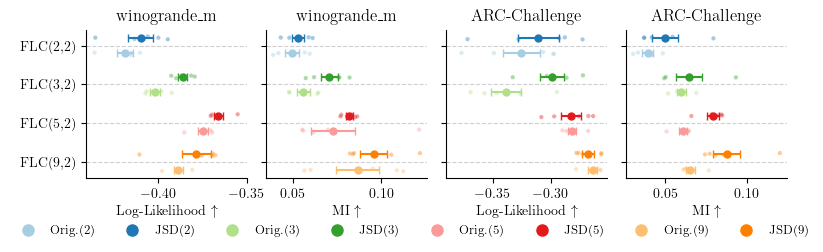

In [99]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.lines as mlines
import numpy as np

# Select metrics and datasets
metrics = ["ll", "test_mutual_information_ppd"]
datasets = ["winogrande_m", "ARC-Challenge"]
if "base" in hue_order:
    hue_order.remove("base")

df_plot_subset = df_plot_[
    df_plot_['Metric'].isin(metrics) & 
    df_plot_['Dataset'].isin(datasets)
].copy()

df_plot_subset = df_plot_subset[df_plot_subset['ModelMode'] != 'jsd_noise_sampling_dropout_category']

# Mapping for layout
y_mapping = {model: i for i, model in enumerate(order)}
df_plot_subset['y_base'] = df_plot_subset['Model'].map(y_mapping)

def get_offset(hue_val):
    if 'Orig' in str(hue_val):
        return -0.2
    elif 'JSD' in str(hue_val):
        return 0.2
    return 0

df_plot_subset['y_offset'] = df_plot_subset[hue_name].apply(get_offset)
df_plot_subset['y_final'] = df_plot_subset['y_base'] + df_plot_subset['y_offset']
df_plot_subset['y_scatter'] = df_plot_subset['y_final'] + np.random.uniform(-0.04, 0.04, size=len(df_plot_subset))

# Create a combined identifier for single row plotting
df_plot_subset['metric_ds'] = df_plot_subset['Metric'] + " | " + df_plot_subset['Dataset']

# Define the order of columns for the single row
col_order = [
    "ll | winogrande_m", "test_mutual_information_ppd | winogrande_m",
    "ll | ARC-Challenge", "test_mutual_information_ppd | ARC-Challenge"
]

# Create FacetGrid: 1 row, 4 columns
g = sns.FacetGrid(
    data=df_plot_subset, 
    col='metric_ds', col_order=col_order,
    sharex=False,
    height=figsize[1]/1.5, aspect=.9,
)

def custom_plot(data, **kwargs):
    ax = plt.gca()
    
    # A) Raw data
    sns.scatterplot(
        data=data, x='value', y='y_scatter',
        hue=hue_name, palette=hue_palette, hue_order=hue_order,
        alpha=0.4, s=10, legend=False, ax=ax, zorder=1
    )
    
    # B) Means & Error bars
    for hue_val in hue_order:
        sub_data = data[data[hue_name] == hue_val]
        if sub_data.empty: continue
            
        color = hue_palette[hue_val]
        grouped = sub_data.groupby('y_final')['value'].agg(['mean', 'sem']).dropna()
        
        for y_pos, row in grouped.iterrows():
            ax.errorbar(
                row['mean'], y_pos, xerr=row['sem'],
                fmt='o', color=color, markersize=5,
                capsize=3, linewidth=1.5, zorder=2
            )

g.map_dataframe(custom_plot)

# Cosmteics
for i, ax in enumerate(g.axes.flat):
    col_val = col_order[i]
    metric_type = "ll" if "ll |" in col_val else "mi"
    
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels(order)  # Show y labels on all plots
    ax.invert_yaxis()
    ax.grid(True, axis='y', linestyle='--', alpha=0.6)

    # BLoB Line
    subset = df_plot_subset[df_plot_subset['metric_ds'] == col_val]
    subset_blob = subset[subset['Model'] == 'BLoB WB']
    if not subset_blob.empty and np.isfinite(subset_blob['value'].mean()):
        ax.axvline(x=subset_blob['value'].mean(), color='gray', linestyle='--', alpha=0.5)
    
    # X-labels
    if metric_type == 'll': ax.set_xlabel(r'Log-Likelihood $\uparrow$')
    else: ax.set_xlabel(r'MI $\uparrow$')
    
    # Title formatting
    title_parts = col_val.split(" | ")
    dataset_display = title_parts[1]
    metric_display = "LL" if title_parts[0] == "ll" else "MI"
    # ax.set_title(f"{dataset_display} ({metric_display})")
    ax.set_title(f"{dataset_display}")

    # Dynamic limits for LL
    if metric_type == 'll':
        vals = subset['value'].dropna()
        if not vals.empty:
            ax.set_xlim(left=vals.min() - 0.005, right=vals.max() + 0.005)

legend_handles = [
    mlines.Line2D([], [], color=hue_palette[hue], marker='o', linestyle='None', markersize=8, label=hue) 
    for hue in hue_order if hue in df_plot_subset[hue_name].unique()
]

g.axes[0,0].set_ylabel("")
# Adjust legend and layout
g.add_legend(handles=legend_handles, title="", loc='lower left', bbox_to_anchor=(0.01, -0.11), ncol=9)
g.fig.subplots_adjust(bottom=0.2)

plt.savefig("result/performance_jsd.pdf", dpi=300, bbox_inches='tight')
# plt.savefig("my-overleaf-project/figures/performance_jsd.pdf", dpi=300, bbox_inches='tight')

plt.show()

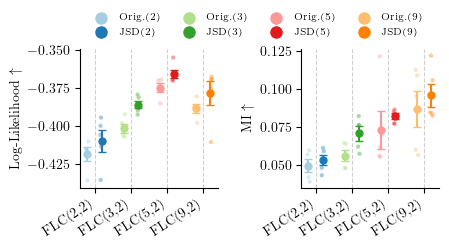

In [100]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.lines as mlines
import numpy as np

# Select metrics and datasets
hue_name = "Space"
metrics = ["ll", "test_mutual_information_ppd"]
datasets = ["winogrande_m",]
if "base" in hue_order:
    hue_order.remove("base")

df_plot_subset = df_plot_[
    df_plot_['Metric'].isin(metrics) & 
    df_plot_['Dataset'].isin(datasets)
].copy()

df_plot_subset = df_plot_subset[df_plot_subset['ModelMode'] != 'jsd_noise_sampling_dropout_category']

order = [#'MAP', 
        #  'ScalaBL', 'BLoB', 
         f'{free_model_name}(9,2)', 
         f'{free_model_name}(5,2)', 
         f'{free_model_name}(3,2)', 
         f'{free_model_name}(2,2)', 
        #  'Sampling-PSMILE', 'Sampling-SGHMC'
         ][::-1]

# Mapping for layout 
x_mapping = {model: i for i, model in enumerate(order)}
df_plot_subset['x_base'] = df_plot_subset['Model'].map(x_mapping)

def get_offset(hue_val):
    if 'Orig' in str(hue_val):
        return -0.2
    elif 'JSD' in str(hue_val):
        return 0.2
    return 0

df_plot_subset['x_offset'] = df_plot_subset[hue_name].apply(get_offset)
df_plot_subset['x_final'] = df_plot_subset['x_base'] + df_plot_subset['x_offset']
df_plot_subset['x_scatter'] = df_plot_subset['x_final'] + np.random.uniform(-0.04, 0.04, size=len(df_plot_subset))

# Create a combined identifier for single row plotting
df_plot_subset['metric_ds'] = df_plot_subset['Metric'] + " | " + df_plot_subset['Dataset']

# Define the order of columns for the single row
col_order = [
    "ll | winogrande_m", "test_mutual_information_ppd | winogrande_m",
    # "ll | ARC-Challenge", "test_mutual_information_ppd | ARC-Challenge"
]

# Create FacetGrid: 1 row, 4 columns
# Updated: aspect=1.1
g = sns.FacetGrid(
    data=df_plot_subset, 
    col='metric_ds', col_order=col_order,
    sharey=False, sharex=True,
    height=figsize[1]/1.5, aspect=1.1,
)

def custom_plot(data, **kwargs):
    ax = plt.gca()
    
    # A) Raw data 
    sns.scatterplot(
        data=data, x='x_scatter', y='value',
        hue=hue_name, palette=hue_palette, hue_order=hue_order,
        alpha=0.4, s=10, legend=False, ax=ax, zorder=1
    )
    
    # B) Means & Error bars
    for hue_val in hue_order:
        sub_data = data[data[hue_name] == hue_val]
        if sub_data.empty: continue
            
        color = hue_palette[hue_val]
        grouped = sub_data.groupby('x_final')['value'].agg(['mean', 'sem']).dropna()
        
        for x_pos, row in grouped.iterrows():
            ax.errorbar(
                x_pos, row['mean'], yerr=row['sem'],
                fmt='o', color=color, markersize=5,
                capsize=3, linewidth=1.5, zorder=2
            )

g.map_dataframe(custom_plot)

# Cosmetics
for i, ax in enumerate(g.axes.flat):
    col_val = col_order[i]
    metric_type = "ll" if "ll |" in col_val else "mi"
    
    # Apply the ordered models to the ticks
    # Updated: rotation=33
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(order, rotation=33, ha="right") 
    
    ax.grid(True, axis='x', linestyle='--', alpha=0.6)

    # BLoB Line 
    subset = df_plot_subset[df_plot_subset['metric_ds'] == col_val]
    subset_blob = subset[subset['Model'] == 'BLoB WB']
    if not subset_blob.empty and np.isfinite(subset_blob['value'].mean()):
        ax.axhline(y=subset_blob['value'].mean(), color='gray', linestyle='--', alpha=0.5)
    
    # Y-labels 
    if metric_type == 'll': ax.set_ylabel(r'Log-Likelihood $\uparrow$')
    else: ax.set_ylabel(r'MI $\uparrow$')
    
    ax.set_title(f"")
    ax.set_xlabel("") 

    # Dynamic limits for LL 
    if metric_type == 'll':
        vals = subset['value'].dropna()
        if not vals.empty:
            ax.set_ylim(bottom=vals.min() - 0.005, top=vals.max() + 0.005)

legend_handles = [
    mlines.Line2D([], [], color=hue_palette[hue], marker='o', linestyle='None', markersize=8, label=hue) 
    for hue in hue_order if hue in df_plot_subset[hue_name].unique()
]

# Adjust legend and layout
g.add_legend(handles=legend_handles, title="", loc='upper left', bbox_to_anchor=(0.16, 1.05), ncol=4, fontsize='x-small', )
g.fig.subplots_adjust(wspace=0.6)

plt.savefig("result/performance_jsd.pdf", dpi=300, bbox_inches='tight')
plt.savefig("my-overleaf-project/new_figures/performance_jsd.pdf", dpi=300, bbox_inches='tight')

plt.show()

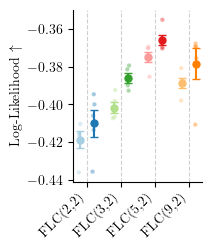

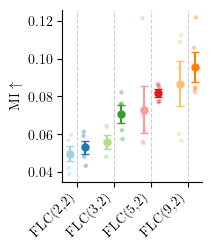

In [101]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.lines as mlines
import numpy as np

# Select metrics and datasets
hue_name = "Space"
metrics = ["ll", "test_mutual_information_ppd"]
datasets = ["winogrande_m",]
if "base" in hue_order:
    hue_order.remove("base")

df_plot_subset = df_plot_[
    df_plot_['Metric'].isin(metrics) & 
    df_plot_['Dataset'].isin(datasets)
].copy()

df_plot_subset = df_plot_subset[df_plot_subset['ModelMode'] != 'jsd_noise_sampling_dropout_category']

order = [#'MAP', 
        #  'ScalaBL', 'BLoB', 
         f'{free_model_name}(9,2)', 
         f'{free_model_name}(5,2)', 
         f'{free_model_name}(3,2)', 
         f'{free_model_name}(2,2)', 
        #  'Sampling-PSMILE', 'Sampling-SGHMC'
         ][::-1]

# Mapping for layout 
x_mapping = {model: i for i, model in enumerate(order)}
df_plot_subset['x_base'] = df_plot_subset['Model'].map(x_mapping)

def get_offset(hue_val):
    if 'Orig' in str(hue_val):
        return -0.2
    elif 'JSD' in str(hue_val):
        return 0.2
    return 0

df_plot_subset['x_offset'] = df_plot_subset[hue_name].apply(get_offset)
df_plot_subset['x_final'] = df_plot_subset['x_base'] + df_plot_subset['x_offset']
df_plot_subset['x_scatter'] = df_plot_subset['x_final'] + np.random.uniform(-0.04, 0.04, size=len(df_plot_subset))

# Create a combined identifier for single row plotting
df_plot_subset['metric_ds'] = df_plot_subset['Metric'] + " | " + df_plot_subset['Dataset']

# Define the order of columns for the loop
col_order = [
    "ll | winogrande_m", "test_mutual_information_ppd | winogrande_m",
]

# ==========================================
# 1. GENERATE STANDALONE LEGEND
# ==========================================
legend_handles = [
    mlines.Line2D([], [], color=hue_palette[hue], marker='o', linestyle='None', markersize=8, label=hue) 
    for hue in hue_order if hue in df_plot_subset[hue_name].unique()
]
labels = [h.get_label() for h in legend_handles]

fig_leg = plt.figure(figsize=(5.0, 0.5)) 
fig_leg.legend(handles=legend_handles, labels=labels, loc='center', ncol=4, frameon=False, title="", 
               columnspacing=1.2,  # Decrease to bring columns closer together (default is ~2.0)
               handletextpad=0.2,  # Decrease to bring the number closer to the dot (default is ~0.8)
               ) #fontsize='small')
fig_leg.savefig("my-overleaf-project/new_figures/performance_jsd_legend.pdf", bbox_inches='tight', pad_inches=0.01)
# If you are in a notebook and want to see the legend, use display(fig_leg) here before closing
plt.close(fig_leg)


# ==========================================
# 2. GENERATE INDIVIDUAL PLOTS
# ==========================================
def custom_plot(data, **kwargs):
    ax = plt.gca()
    
    # A) Raw data 
    sns.scatterplot(
        data=data, x='x_scatter', y='value',
        hue=hue_name, palette=hue_palette, hue_order=hue_order,
        alpha=0.4, s=10, legend=False, ax=ax, zorder=1
    )
    
    # B) Means & Error bars
    for hue_val in hue_order:
        sub_data = data[data[hue_name] == hue_val]
        if sub_data.empty: continue
            
        color = hue_palette[hue_val]
        grouped = sub_data.groupby('x_final')['value'].agg(['mean', 'sem']).dropna()
        
        for x_pos, row in grouped.iterrows():
            ax.errorbar(
                x_pos, row['mean'], yerr=row['sem'],
                fmt='o', color=color, markersize=5,
                capsize=3, linewidth=1.5, zorder=2
            )

# Loop through each metric and save it as a completely independent figure
for col_val in col_order:
    # Filter data for just this one metric
    subset_data = df_plot_subset[df_plot_subset['metric_ds'] == col_val]
    metric_type = "ll" if "ll |" in col_val else "mi"
    
    # Create single plot (Notice: col='metric_ds' is REMOVED)
    g = sns.FacetGrid(
        data=subset_data, 
        sharey=False, sharex=True,
        height=figsize[1]/1.3, aspect=.85, # aspect=1.0 ensures width matches your single plots perfectly
    )
    
    g.map_dataframe(custom_plot)
    
    # Cosmetics for the single axis
    ax = g.axes.flat[0]
    
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(order, rotation=45, ha="right") 
    ax.grid(True, axis='x', linestyle='--', alpha=0.6)

    # BLoB Line 
    subset_blob = subset_data[subset_data['Model'] == 'BLoB WB']
    if not subset_blob.empty and np.isfinite(subset_blob['value'].mean()):
        ax.axhline(y=subset_blob['value'].mean(), color='gray', linestyle='--', alpha=0.5)
    
    # Y-labels and dynamic limits
    if metric_type == 'll': 
        ax.set_ylabel(r'Log-Likelihood $\uparrow$')
        vals = subset_data['value'].dropna()
        if not vals.empty:
            ax.set_ylim(bottom=vals.min() - 0.005, top=vals.max() + 0.005)
    else: 
        ax.set_ylabel(r'MI $\uparrow$')
        
    ax.set_title("")
    ax.set_xlabel("") 
    
    g.tight_layout()
    
    # Generate unique filename per metric
    filename = f"performance_jsd_{metric_type}.pdf"
    
    # Save the individual plot
    plt.savefig(f"result/{filename}", dpi=300, bbox_inches='tight')
    plt.savefig(f"my-overleaf-project/new_figures/{filename}", dpi=300, bbox_inches='tight', pad_inches=0.05)
    
    plt.show() # Shows each plot sequentially in the notebook

### Flat Lora Compare

In [76]:
import wandb
from tqdm import tqdm
from copy import deepcopy
import numpy as np

api = wandb.Api()
results = []


for s in set(["w0kaq8i0", 'xv7jw9bv', 'we8wq8n7', 'jb3j4w2y' ]): # + flat lora winogrande_m training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC_newDS/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        mp = run.config['model_params']
        opt_conf = run.config['optimizer_conf']
        hp = run.config['train_hyper']
        lora = mp['lora_params']

        NCurveSegment = mp['num_curve_segment']
        CurveDegree = mp['SegDeg']
        res = dict(Id=run.id,
        #    CurveSpace=f"{mp['k']}",
            # CurveSpace=len(mp['cp_fix']),
            CurveSpace=NCurveSegment * CurveDegree,
            # CpFix=str(mp['cp_fix']),
            NumPretrained=NCurveSegment + 1 if mp['Pretraining'] else 0,
            Jitter=mp['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=opt_conf['kwargs']['weight_decay'],
            Dataset="_".join(run.config['data']['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            BmaMode="PPD",
            DS_Sampling=list(hp.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(hp['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=hp['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=mp.get('entropy_maxim', -1),
            NumSteps=hp.get('num_steps', -1),
            LoraMode=lora.get('lora_mode', 'None'),
            CurveMode=mp.get('curve_parameterization', 'Bezier'),
            LoraRank=lora.get('r', -1),
            RegularizationMode=mp.get('regularizer', False),
            Gravity=mp.get('gravity', 0.),
            EnergyWeakening=mp.get('energy_weakening', 0.),
            Tsample=mp.get('curve_sampling_mode', 'None'),
            LoraRho=lora.get('lora_rho', -1),
            LoraRhoS=lora.get('lora_rho_s', -1),
            RhoFrequency=lora.get('rho_scheduler_frequency', 0),
            CurveSegmentDegree=CurveDegree,
            NCurveSegment=NCurveSegment,
            OpenEndSegment=mp.get('independent_connected', False),
            N=NCurveSegment + 1,
            M=CurveDegree - 1,
            N_cps = NCurveSegment * CurveDegree + 1,
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"test_ppd_acc", -np.inf),
            ece=run.summary.get(f"test_ppd_ece", -np.inf),
            ll=run.summary.get(f"test_ppd_ll", -np.inf),
            brier=run.summary.get(f"test_ppd_brier", -np.inf),
            test_mean_entropy_ppd=run.summary.get(f"test_ppd_weighted_mean_entropy", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_ppd_weighted_mutual_information", -np.inf),
            test_std_entropy_along_curve=0,
            test_mean_entropy_along_curve=0,
            )
        results.append(res)
        if mp['Pretraining']:
            # add DE   
            _res = deepcopy(res)
            _res['BmaMode'] = "DE"
            _res['acc'] = run.summary.get(f"test_DE_acc", -np.inf)
            _res['ece'] = run.summary.get(f"test_DE_ece", -np.inf)
            _res['ll'] = run.summary.get(f"test_DE_ll", -np.inf)
            _res['brier']=run.summary.get(f"test_DE_brier", -np.inf)
            _res['test_mean_entropy_ppd']=run.summary.get(f"test_DE_uniform_mean_entropy", -np.inf)
            _res['test_mutual_information_ppd']=run.summary.get(f"test_DE_uniform_mutual_information", -np.inf)
            _res['test_std_entropy_along_curve']=run.summary.get(f"test_DE_uniform_std_entropy_along_curve", -np.inf)
            _res['test_mean_entropy_along_curve']=run.summary.get(f"test_DE_uniform_mean_entropy_along_curve", -np.inf)
            results.append(_res)
            for k in run.summary.keys():
                if k.startswith("cp_fixed_") and k.endswith("_test_acc"):
                    i = k.split("_")[2]
                    _res = deepcopy(res)
                    _res['BmaMode'] = "MAP"
                    # print(run.summary.get(f"cp_fixed_{i}_test_acc", -np.inf))
                    _res['acc'] = run.summary.get(f"cp_fixed_{i}_test_acc", -np.inf)
                    _res['ece'] = run.summary.get(f"cp_fixed_{i}_test_ece", -np.inf)
                    _res['ll'] = run.summary.get(f"cp_fixed_{i}_test_ll", -np.inf)
                    _res['brier']=run.summary.get(f"cp_fixed_{i}_test_brier", -np.inf)
                    _res['test_mean_entropy_ppd']=run.summary.get(f"cp_fixed_{i}_test_entropy", -np.inf)
                    _res['test_mutual_information_ppd']=0
                    _res['test_std_entropy_along_curve']=0
                    _res['test_mean_entropy_along_curve']=0
                    # print(_res['acc'], _res['ece'], _res['ll'])
                    results.append(_res)

        # add PPD uniform   
        _res = deepcopy(res)
        _res['BmaMode'] = "PPD Uniform"
        _res['acc'] = run.summary.get(f"test_ppd_uniform_acc", -np.inf)
        _res['ece'] = run.summary.get(f"test_ppd_uniform_ece", -np.inf)
        _res['ll'] = run.summary.get(f"test_ppd_uniform_ll", -np.inf)
        _res['brier']=run.summary.get(f"test_ppd_uniform_brier", -np.inf)
        _res['test_mean_entropy_ppd']=run.summary.get(f"test_ppd_uniform_mean_entropy", -np.inf)
        _res['test_mutual_information_ppd']=run.summary.get(f"test_ppd_uniform_mutual_information", -np.inf)
        _res['test_std_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_std_entropy_along_curve", -np.inf)
        _res['test_mean_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_mean_entropy_along_curve", -np.inf)
        results.append(_res)
 
df = pd.DataFrame(results)
df.describe().T

xv7jw9bv: 100%|██████████| 50/50 [00:00<00:00, 298.68it/s, frosty-sweep-2]   
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/numpy/lib/function_base.py:4655: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


,count,mean,std,min,25%,50%,75%,max
CurveSpace,2450.0,1.137755e+01,6.724035,2.000000e+00,6.000000,12.000000,16.000000,24.000000
NumPretrained,2450.0,4.408163e+00,3.175282,0.000000e+00,2.000000,5.000000,5.000000,9.000000
Jitter,2450.0,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000
Seed,2450.0,1.684600e+03,3162.006447,1.000000e+00,2.000000,20.000000,400.000000,8000.000000
WeightDecay,2450.0,1.000000e-03,0.000000,1.000000e-03,0.001000,0.001000,0.001000,0.001000
DS_WindowSize,2450.0,-1.000000e+00,0.000000,-1.000000e+00,-1.000000,-1.000000,-1.000000,-1.000000
EntropyMaxScale,2450.0,-1.000000e+00,0.000000,-1.000000e+00,-1.000000,-1.000000,-1.000000,-1.000000
NumSteps,2450.0,1.000000e+04,0.000000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000
LoraRank,2450.0,8.000000e+00,0.000000,8.000000e+00,8.000000,8.000000,8.000000,8.000000
Gravity,2450.0,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000


In [77]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [24 12  6  3 16  8  4  2]
NumPretrained [0 9 5 3 2]
Jitter [0]
Seed [8000  400   20    2    1]
WeightDecay [0.001]
Dataset ['ARC-Easy' 'ARC-Challenge' 'winogrande_s' 'obqa' 'winogrande_m']
BmaMode ['PPD' 'PPD Uniform' 'DE' 'MAP']
DS_Sampling ['minibatch']
DS_Mode ['classic']
DS_WindowSize [-1]
EntropyMaxScale [-1]
NumSteps [10000]
LoraMode ['A(t)eB(t)']
CurveMode ['bezier']
LoraRank [8]
RegularizationMode [False]
Gravity [0]
EnergyWeakening [1]
Tsample ['combined_all']
LoraRho [0.25 0.   0.5 ]
LoraRhoS [0]
RhoFrequency [50]
CurveSegmentDegree [3 2]
NCurveSegment [8 4 2 1]
OpenEndSegment [False]
N [9 5 3 2]
M [2 1]
N_cps [25 13  7  4 17  9  5  3]

Experiment differs in ['CurveSpace', 'NumPretrained', 'Dataset', 'BmaMode', 'LoraRho', 'CurveSegmentDegree', 'NCurveSegment', 'N', 'M', 'N_cps'] configs


array(['ARC-Challenge', 'ARC-Easy', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

In [78]:
# Build Config label
df_subset = df_clean.copy()
# df_subset = df_subset[(df_subset['LoraMode'] == "A(t)eB(t)") & (df_subset['BmaMode'] != 'MAP')]
df_subset = df_subset[(df_subset['LoraMode'] == "A(t)eB(t)") & (df_subset['BmaMode'] != 'PPD')]

# Filter for only configs with LoraRho=0.0 (open curves) and then inner join back to keep only those configs across all seeds and metrics
match_cols = deepcopy(variable_idx) + ['Seed']
match_cols.remove('LoraRho')
filter_mask = df_subset[df_subset['LoraRho'] == 0.][match_cols].drop_duplicates()
df_subset = df_subset.merge(filter_mask, on=match_cols, how='inner')

df_plot = df_subset.melt(id_vars=idx_ids, value_vars=value_ids, var_name='Metric', value_name='value')
# df_plot['Config'] = df_plot.apply(lambda r: f"fix={r['NumPretrained']}, k={r['CurveSpace']}, SegDeg={r['CurveSegmentDegree']}, N_Seg={r['NCurveSegment']}, rho={r['LoraRho']}, Mode={r['LoraMode']}/{r['CurveMode']}", axis=1)
df_plot['Config'] = df_plot.apply(lambda r: " | ".join([f"{k}={r[k]}" for k in variable_idx if k not in ['CurveSpace', 'NCurveSegment', 'NumPretrained', 'Dataset', 'BmaMode',]]), axis=1)

def map_model(x):
    if x['BmaMode'] == 'MAP':
        return "MAP"
    elif x['BmaMode'] == 'DE':
        return f"DE({x['NumPretrained']})"
    elif x['BmaMode'] == 'PPD Uniform':
        is_fixed = x['NumPretrained'] > 0
        seg_deg = x['CurveSegmentDegree']
        
        if seg_deg == 1:
            prefix = "Linear" if is_fixed else "Linear_" + free_model_name
            return f"{prefix}({x['NumPretrained']})"
        else:
            prefix = pretrained_model_name if is_fixed else free_model_name
            return rf"{prefix}({x['N']},{x['M']})"
    else:
        return "None"

df_plot['Model'] = df_plot.apply(map_model, axis=1)
# set NCurveSegment to 0 for MAP and DE
df_plot.loc[df_plot['BmaMode'] == 'MAP', 'NCurveSegment'] = 0
df_plot.loc[df_plot['BmaMode'] == 'DE', 'NCurveSegment'] = 0
df_plot.sort_values(by=['Model'], inplace=True)

df_plot.rename(columns={
    'N': n_name,
    'M': seg_deg_name,
    'NCurveSegment': n_seg_name,
    'LoraRho': rho_name,
}, inplace=True)


Models set() missing:


/tmp/ipykernel_2347890/3645881620.py:26: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


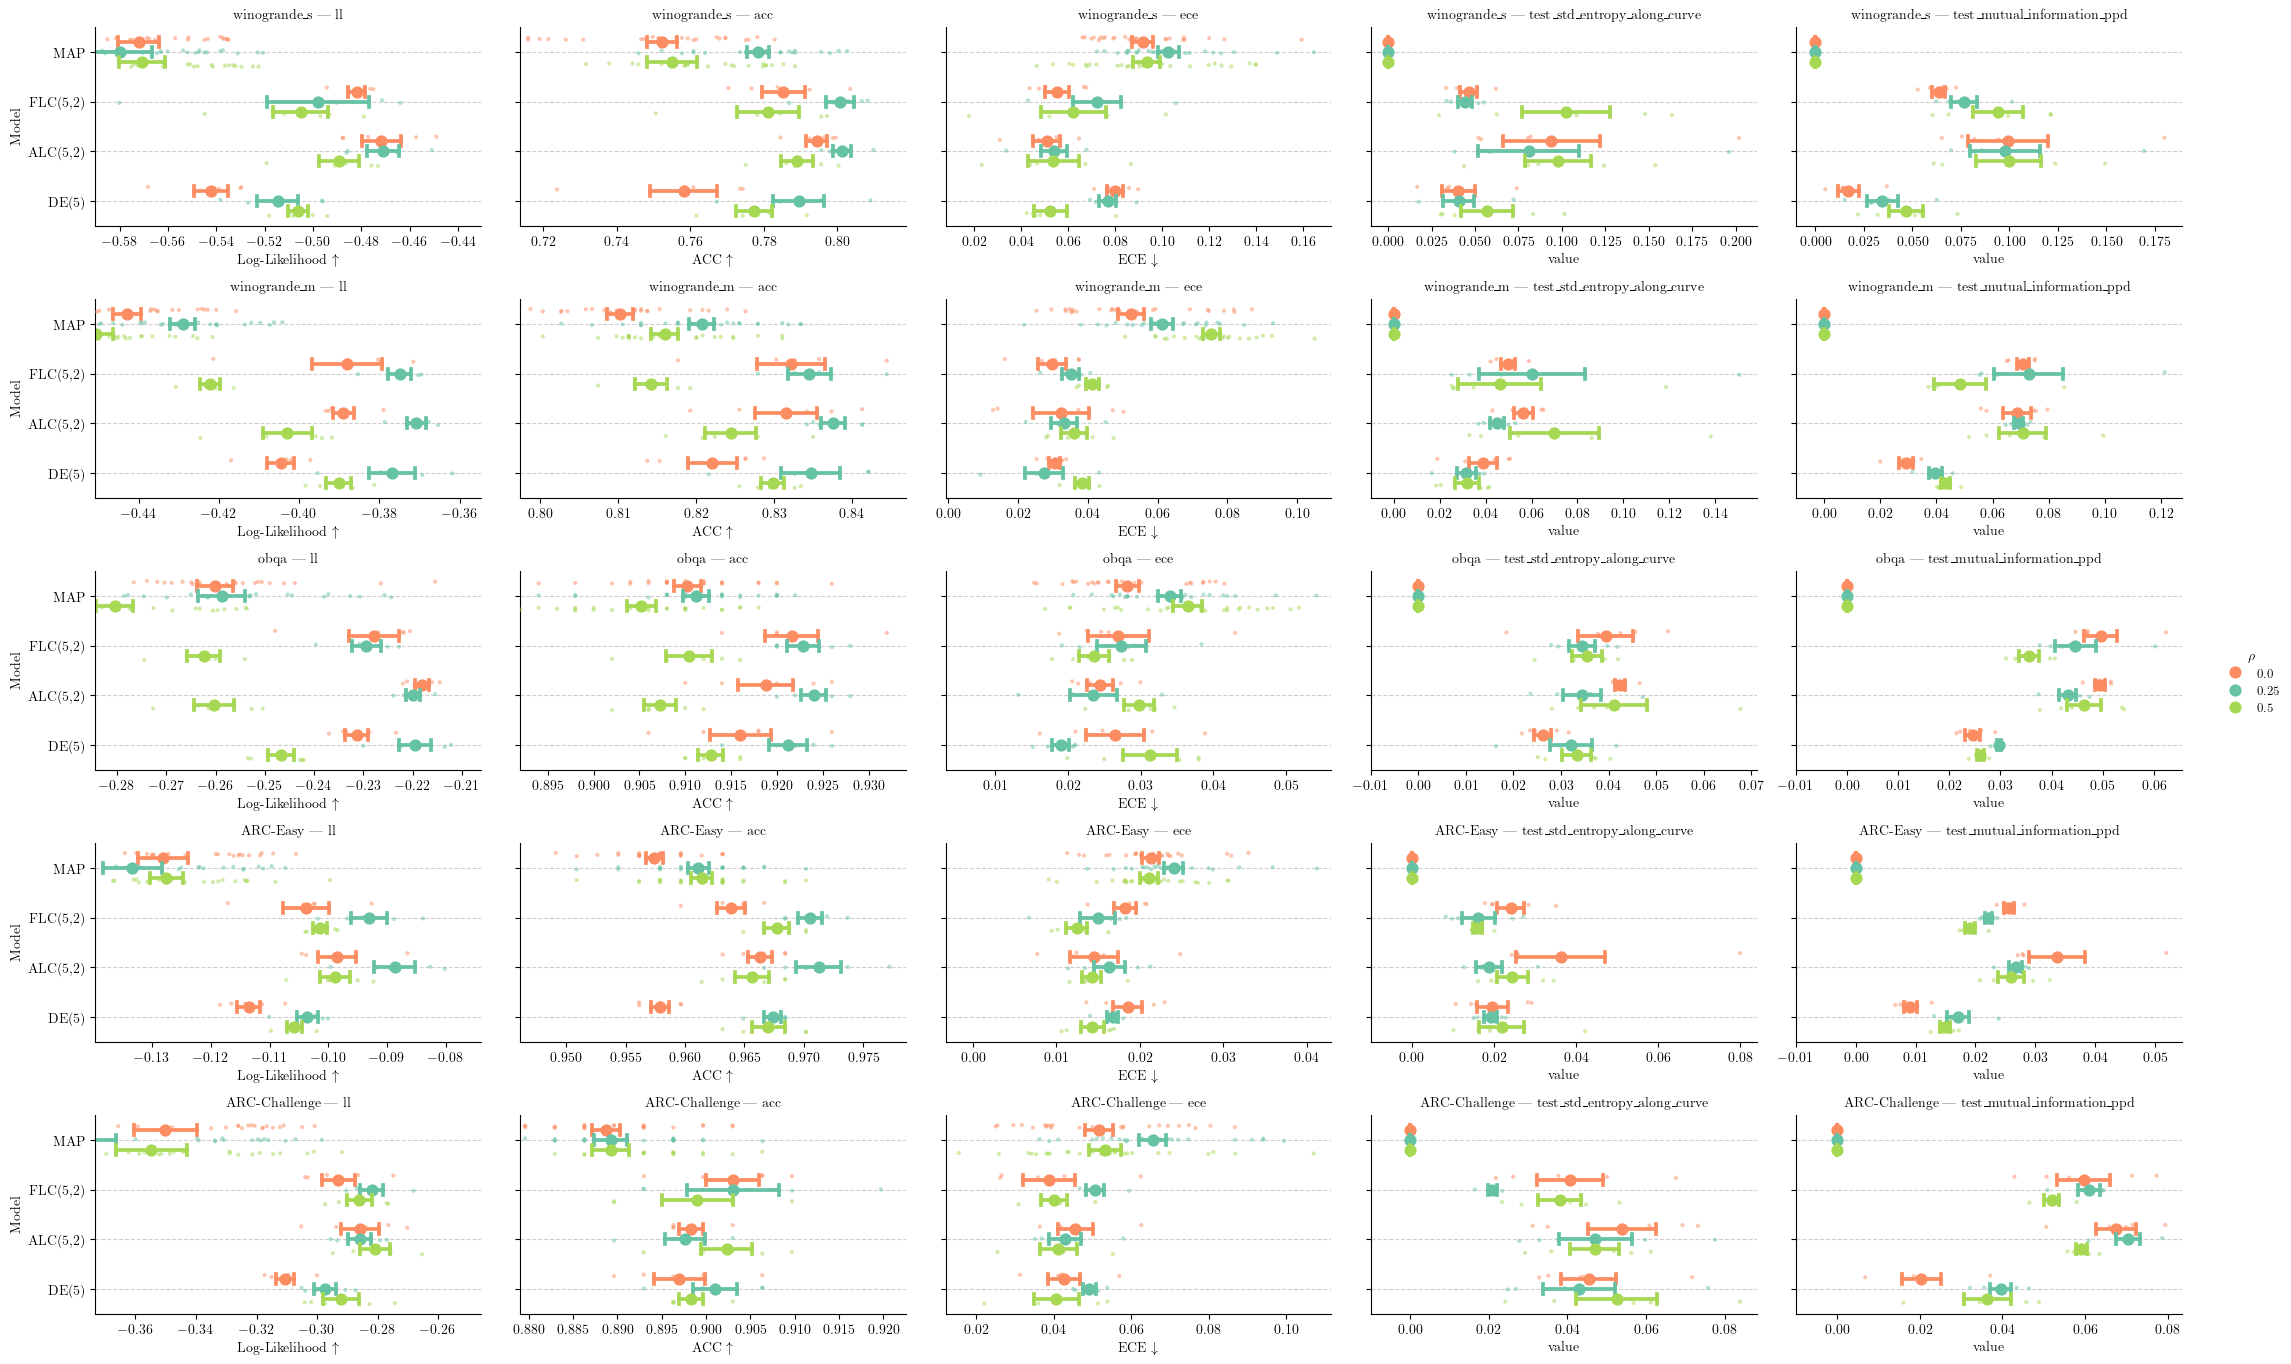

In [79]:
# stack df_vi to df_plot
hue_name = rho_name
df_plot_ = deepcopy(df_plot)
df_plot_[hue_name] = df_plot_[hue_name].astype(float)
# df_plot_ = pd.concat([df_plot,], ignore_index=True)
# hue
numeric_rhos = sorted(float(x) for x in df_plot_[hue_name].unique())
df_plot_[hue_name] = df_plot_[hue_name].astype(str)
hue_order = [str(x) for x in numeric_rhos]
hue_palette = sns.color_palette("Set2")
hue_palette = {'0.0': hue_palette[1], '0.25': hue_palette[0], '0.5': hue_palette[2], '0.5': hue_palette[4],}
col_order = "ll", "acc", "ece", "test_std_entropy_along_curve", "test_mutual_information_ppd"
row_order = "winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge",
order = df_plot_['Model'].unique()
order = ['MAP',
        #  f'Linear({n_seg_name}=5)', #'OpenLinear(13)',
         rf'{free_model_name}(5,2)',
         rf'{pretrained_model_name}(5,2)',
         f'DE(5)']


print(f"Models {set(df_plot_['Model'].unique()) - set(order)} missing:")


# Seaborn Catplot (ANOVA style)
g = sns.catplot(
    data=df_plot_, x='value', y='Model',
    row='Dataset', col='Metric',
    row_order=row_order, col_order=col_order,
    order=order,
    kind='point', join=False, capsize=.2,
    markers='o', palette=hue_palette, hue=hue_name,
    dodge=0.4, sharex=False, height=figsize[0]/2, aspect=1.618,
    legend=True, errorbar="se", hue_order=hue_order,
)

# Overlay strip plots for original points (small, alpha=0.5)
for (ds, metric), ax in g.axes_dict.items():
    subset = df_plot_[(df_plot_['Dataset'] == ds) & (df_plot_['Metric'] == metric)]
    sns.stripplot(
        data=subset, x='value', y='Model',
        order=order,
        ax=ax, palette=hue_palette, alpha=0.5, size=3,
        dodge=0.4, hue=hue_name, legend=False, hue_order=hue_order,
    )
    
    # Refine grid and labels
    ax.grid(True, axis='y', linestyle='--', alpha=0.6)
    
    # Label mapping for x-axis
    if metric == 'acc':
        ax.set_xlabel(r'ACC $\uparrow$')
    elif metric == 'll':
        ax.set_xlabel(r'Log-Likelihood $\uparrow$')
    elif metric == 'ece':
        ax.set_xlabel(r'ECE $\downarrow$')

    # clip x-axis to range of min without MAP
    def only_finit(x):
        return x[np.isfinite(x)]
    min_value = only_finit(subset[subset['Model'] != 'MAP']['value']).min()
    mean_value_MAP = only_finit(subset[subset['Model'] == 'MAP']['value']).mean()
    if np.isfinite(min_value):
        ax.set_xlim(left=min(min_value, mean_value_MAP)-0.01)  # add some padding on the left

# Adjust layout and titles
g.set_titles(row_template='{row_name}', col_template='{col_name}')
g.tight_layout()
# g.add_legend(title='#CurveSegments')
# plt.savefig("result/performance_pointplot.png", dpi=300)
# plt.savefig("result/performance_pointplot.pdf", dpi=300)
plt.show()

/tmp/ipykernel_2347890/3605226426.py:12: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


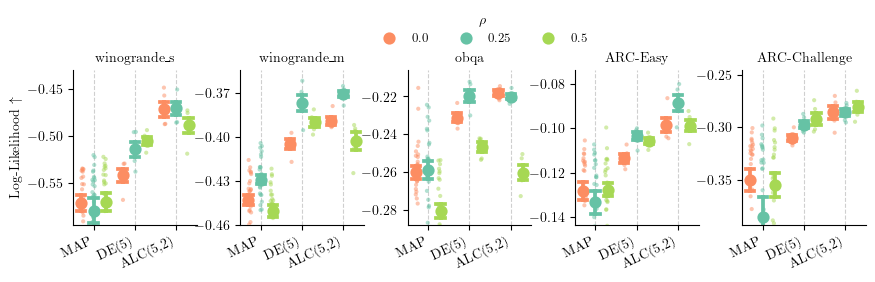

In [80]:
# Only LL metric plotted with col='Dataset' and col_wrap=3
df_plot_ll = df_plot_[df_plot_['Metric'] == 'll'].copy()

col_order_ds = ["winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge"]
order = ['MAP',
         f'DE(5)',
        #  f'Linear({n_seg_name}=5)', #'OpenLinear(13)',
        #  rf'{free_model_name}({n_seg_name}=5, {seg_deg_name}=3)',
         rf'{pretrained_model_name}(5,2)',
         ]

g = sns.catplot(
    data=df_plot_ll, x='Model', y='value',
    col='Dataset', col_wrap=5,
    col_order=col_order_ds,
    order=order,
    kind='point', join=False, capsize=.2,
    markers='o', palette=hue_palette, hue=hue_name,
    dodge=0.6, sharey=False, height=figsize[1]/1.5, aspect=0.8,
    legend=True, errorbar="se", hue_order=hue_order,
)

# Overlay strip plots for original points (small, alpha=0.5)
for ds, ax in g.axes_dict.items():
    subset = df_plot_ll[df_plot_ll['Dataset'] == ds]
    sns.stripplot(
        data=subset, x='Model', y='value',
        order=order,
        ax=ax, palette=hue_palette, alpha=0.5, size=3,
        dodge=0.6, hue=hue_name, legend=False, hue_order=hue_order,
    )
    
    # Refine grid and labels
    ax.grid(True, axis='x', linestyle='--', alpha=0.6)
    
    # Label mapping for y-axis
    ax.set_ylabel(r'Log-Likelihood $\uparrow$')
    ax.set_xlabel('')

    # clip y-axis to range of min without MAP
    def only_finit(x):
        return x[np.isfinite(x)]
    
    non_map_vals = only_finit(subset[subset['Model'] != 'MAP']['value'])
    map_vals = only_finit(subset[subset['Model'] == 'MAP']['value'])
    
    min_value = non_map_vals.min() if not non_map_vals.empty else np.nan
    mean_value_MAP = map_vals.mean() if not map_vals.empty else np.nan
    mean_value_MAP  = np.quantile(map_vals, 0.25) if not map_vals.empty else np.nan  # use 25th percentile to be more robust against outliers
    
    if np.isfinite(min_value) and np.isfinite(mean_value_MAP):
        ax.set_ylim(bottom=min(min_value, mean_value_MAP)-0.01)  # add some padding on the bottom
    elif np.isfinite(min_value):
        ax.set_ylim(bottom=min_value-0.01)

# Adjust layout and titles
g.set_titles(col_template='{col_name}')
g.tight_layout()

#legent top flat
sns.move_legend(g, loc='upper center', bbox_to_anchor=(0.5, 1.15), ncol=len(hue_order), title=hue_name)
# rotate x labels
for i, ax in enumerate(g.axes):
    plt.setp(ax.get_xticklabels(), rotation=25, ha='right')
    # plt.setp(ax.get_yticklabels(), rotation=20, ha='right')
    if i > 0:
        ax.set_ylabel('')  # remove x-axis label since it's redundant with the rotated labels
# set wspace
g.axes[1].set_yticks([-0.37, -0.4, -0.43, -0.46])  # remove y-ticks for middle plot to save space
g.fig.subplots_adjust(wspace=0.35)


plt.savefig("result/performance_flatLoRA_vs_vanilla.pdf", dpi=300, bbox_inches='tight')
# plt.savefig("my-overleaf-project/figures/performance_flatLoRA_vs_vanilla.pdf", dpi=300, bbox_inches='tight')
plt.show()

/tmp/ipykernel_2347890/2468348450.py:12: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


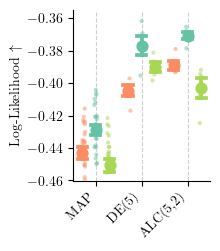

In [81]:
# Only LL metric plotted with col='Dataset' and col_wrap=3
df_plot_ll = df_plot_[df_plot_['Metric'] == 'll'].copy()

col_order_ds = ["winogrande_m", ]
order = ['MAP',
         f'DE(5)',
        #  f'Linear({n_seg_name}=5)', #'OpenLinear(13)',
        #  rf'{free_model_name}({n_seg_name}=5, {seg_deg_name}=3)',
         rf'{pretrained_model_name}(5,2)',
         ]

g = sns.catplot(
    data=df_plot_ll, x='Model', y='value',
    col='Dataset', col_wrap=5,
    col_order=col_order_ds,
    order=order,
    kind='point', join=False, capsize=.2,
    markers='o', palette=hue_palette, hue=hue_name,
    dodge=0.6, sharey=False, height=figsize[1]/1.3, aspect=.65,
    legend=True, errorbar="se", hue_order=hue_order,
)

# Overlay strip plots for original points (small, alpha=0.5)
for ds, ax in g.axes_dict.items():
    subset = df_plot_ll[df_plot_ll['Dataset'] == ds]
    sns.stripplot(
        data=subset, x='Model', y='value',
        order=order,
        ax=ax, palette=hue_palette, alpha=0.5, size=3,
        dodge=0.6, hue=hue_name, legend=False, hue_order=hue_order,
    )
    
    # Refine grid and labels
    ax.grid(True, axis='x', linestyle='--', alpha=0.6)
    
    # Label mapping for y-axis
    ax.set_ylabel(r'Log-Likelihood $\uparrow$')
    ax.set_xlabel('')

    # clip y-axis to range of min without MAP
    def only_finit(x):
        return x[np.isfinite(x)]
    
    non_map_vals = only_finit(subset[subset['Model'] != 'MAP']['value'])
    map_vals = only_finit(subset[subset['Model'] == 'MAP']['value'])
    
    min_value = non_map_vals.min() if not non_map_vals.empty else np.nan
    mean_value_MAP = map_vals.mean() if not map_vals.empty else np.nan
    mean_value_MAP  = np.quantile(map_vals, 0.25) if not map_vals.empty else np.nan  # use 25th percentile to be more robust against outliers
    
    if np.isfinite(min_value) and np.isfinite(mean_value_MAP):
        ax.set_ylim(bottom=min(min_value, mean_value_MAP)-0.01)  # add some padding on the bottom
    elif np.isfinite(min_value):
        ax.set_ylim(bottom=min_value-0.01)

# Adjust layout and titles
# g.set_titles(col_template='{col_name}')
g.set_titles(col_template='')
# sns.move_legend(g, loc='upper center', bbox_to_anchor=(0.12, 1.15), ncol=len(hue_order), title=hue_name)

# ==========================================
# EXTRACT AND REMOVE LEGEND
# ==========================================
# Seaborn stores the figure-level legend in g.legend
if g.legend is not None:
    # 1. Safely extract handles, text labels, and title from the Seaborn legend
    handles = g.legend.legend_handles
    labels = [t.get_text() for t in g.legend.get_texts()]
    legend_title = g.legend.get_title().get_text()
    
    # 2. Export it using the helper function
    export_standalone_legend(
        handles, 
        labels, 
        title=legend_title, 
        filename="my-overleaf-project/new_figures/performance_flatLoRA_vs_vanilla_legend.pdf",
        columnspacing=1.2,  # Decrease to bring columns closer together (default is ~2.0)
        handletextpad=0.2,  # Decrease to bring the number closer to the dot (default is ~0.8)
        # fontsize='small',
        ncols=3
    )
    
    # 3. Remove the legend from the original plot completely
    g.legend.remove()

# rotate x labels
for i, ax in enumerate(g.axes):
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
    # plt.setp(ax.get_yticklabels(), rotation=20, ha='right')
    if i > 0:
        ax.set_ylabel('')  # remove x-axis label since it's redundant with the rotated labels

g.tight_layout()
# set wspace
# g.fig.subplots_adjust(wspace=0.35)

plt.savefig("result/performance_flatLoRA_vs_vanilla.pdf", dpi=300, bbox_inches='tight')
plt.savefig("my-overleaf-project/new_figures/performance_flatLoRA_vs_vanilla.pdf", dpi=300, bbox_inches='tight', pad_inches=0.05)

plt.show()

### Segment vs Curve

In [82]:
import wandb
from tqdm import tqdm
from copy import deepcopy
import numpy as np

api = wandb.Api()
results = []


for s in set(["w0kaq8i0", 'sizdf79c' ]): # + flat lora winogrande_m training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC_newDS/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        mp = run.config['model_params']
        opt_conf = run.config['optimizer_conf']
        hp = run.config['train_hyper']
        lora = mp['lora_params']

        NCurveSegment = mp['num_curve_segment']
        CurveDegree = mp['SegDeg']
        res = dict(Id=run.id,
        #    CurveSpace=f"{mp['k']}",
            # CurveSpace=len(mp['cp_fix']),
            CurveSpace=NCurveSegment * CurveDegree,
            # CpFix=str(mp['cp_fix']),
            NumPretrained=NCurveSegment + 1 if mp['Pretraining'] else 0,
            Jitter=mp['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=opt_conf['kwargs']['weight_decay'],
            Dataset="_".join(run.config['data']['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            BmaMode="PPD",
            DS_Sampling=list(hp.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(hp['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=hp['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=mp.get('entropy_maxim', -1),
            NumSteps=hp.get('num_steps', -1),
            LoraMode=lora.get('lora_mode', 'None'),
            CurveMode=mp.get('curve_parameterization', 'Bezier'),
            LoraRank=lora.get('r', -1),
            RegularizationMode=mp.get('regularizer', False),
            Gravity=mp.get('gravity', 0.),
            EnergyWeakening=mp.get('energy_weakening', 0.),
            Tsample=mp.get('curve_sampling_mode', 'None'),
            LoraRho=lora.get('lora_rho', -1),
            LoraRhoS=lora.get('lora_rho_s', -1),
            RhoFrequency=lora.get('rho_scheduler_frequency', 0),
            CurveSegmentDegree=CurveDegree,
            NCurveSegment=NCurveSegment,
            OpenEndSegment=mp.get('independent_connected', False),
            N=NCurveSegment + 1,
            M=CurveDegree - 1,
            N_cps = NCurveSegment * CurveDegree + 1,
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"test_ppd_acc", -np.inf),
            ece=run.summary.get(f"test_ppd_ece", -np.inf),
            ll=run.summary.get(f"test_ppd_ll", -np.inf),
            brier=run.summary.get(f"test_ppd_brier", -np.inf),
            test_mean_entropy_ppd=run.summary.get(f"test_ppd_weighted_mean_entropy", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_ppd_weighted_mutual_information", -np.inf),
            test_std_entropy_along_curve=0,
            test_mean_entropy_along_curve=0,
            )
        results.append(res)
        if mp['Pretraining']:
            # add DE   
            _res = deepcopy(res)
            _res['BmaMode'] = "DE"
            _res['acc'] = run.summary.get(f"test_DE_acc", -np.inf)
            _res['ece'] = run.summary.get(f"test_DE_ece", -np.inf)
            _res['ll'] = run.summary.get(f"test_DE_ll", -np.inf)
            _res['brier']=run.summary.get(f"test_DE_brier", -np.inf)
            _res['test_mean_entropy_ppd']=run.summary.get(f"test_DE_uniform_mean_entropy", -np.inf)
            _res['test_mutual_information_ppd']=run.summary.get(f"test_DE_uniform_mutual_information", -np.inf)
            _res['test_std_entropy_along_curve']=run.summary.get(f"test_DE_uniform_std_entropy_along_curve", -np.inf)
            _res['test_mean_entropy_along_curve']=run.summary.get(f"test_DE_uniform_mean_entropy_along_curve", -np.inf)
            results.append(_res)
            for k in run.summary.keys():
                if k.startswith("cp_fixed_") and k.endswith("_test_acc"):
                    i = k.split("_")[2]
                    _res = deepcopy(res)
                    _res['BmaMode'] = "MAP"
                    # print(run.summary.get(f"cp_fixed_{i}_test_acc", -np.inf))
                    _res['acc'] = run.summary.get(f"cp_fixed_{i}_test_acc", -np.inf)
                    _res['ece'] = run.summary.get(f"cp_fixed_{i}_test_ece", -np.inf)
                    _res['ll'] = run.summary.get(f"cp_fixed_{i}_test_ll", -np.inf)
                    _res['brier']=run.summary.get(f"cp_fixed_{i}_test_brier", -np.inf)
                    _res['test_mean_entropy_ppd']=run.summary.get(f"cp_fixed_{i}_test_entropy", -np.inf)
                    _res['test_mutual_information_ppd']=0
                    _res['test_std_entropy_along_curve']=0
                    _res['test_mean_entropy_along_curve']=0
                    # print(_res['acc'], _res['ece'], _res['ll'])
                    results.append(_res)

        # add PPD uniform   
        _res = deepcopy(res)
        _res['BmaMode'] = "PPD Uniform"
        _res['acc'] = run.summary.get(f"test_ppd_uniform_acc", -np.inf)
        _res['ece'] = run.summary.get(f"test_ppd_uniform_ece", -np.inf)
        _res['ll'] = run.summary.get(f"test_ppd_uniform_ll", -np.inf)
        _res['brier']=run.summary.get(f"test_ppd_uniform_brier", -np.inf)
        _res['test_mean_entropy_ppd']=run.summary.get(f"test_ppd_uniform_mean_entropy", -np.inf)
        _res['test_mutual_information_ppd']=run.summary.get(f"test_ppd_uniform_mutual_information", -np.inf)
        _res['test_std_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_std_entropy_along_curve", -np.inf)
        _res['test_mean_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_mean_entropy_along_curve", -np.inf)
        results.append(_res)

df = pd.DataFrame(results)
df.describe().T

w0kaq8i0:   0%|          | 0/200 [00:00<?, ?it/s, hardy-sweep-191]   

sizdf79c: 100%|██████████| 90/90 [00:00<00:00, 346.07it/s, eternal-sweep-1]   
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/numpy/lib/function_base.py:4655: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


,count,mean,std,min,25%,50%,75%,max
CurveSpace,580.0,1.008621e+01,7.077866,2.000000e+00,4.000000,8.000000,16.000000,24.000000
NumPretrained,580.0,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000
Jitter,580.0,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000
Seed,580.0,1.684600e+03,3164.089914,1.000000e+00,2.000000,20.000000,400.000000,8000.000000
WeightDecay,580.0,1.000000e-03,0.000000,1.000000e-03,0.001000,0.001000,0.001000,0.001000
DS_WindowSize,580.0,-1.000000e+00,0.000000,-1.000000e+00,-1.000000,-1.000000,-1.000000,-1.000000
EntropyMaxScale,580.0,-1.000000e+00,0.000000,-1.000000e+00,-1.000000,-1.000000,-1.000000,-1.000000
NumSteps,580.0,1.000000e+04,0.000000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000
LoraRank,580.0,8.000000e+00,0.000000,8.000000e+00,8.000000,8.000000,8.000000,8.000000
Gravity,580.0,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000


In [83]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [24 12  6  3 16  8  4  2]
NumPretrained [0]
Jitter [0]
Seed [8000  400   20    2    1]
WeightDecay [0.001]
Dataset ['ARC-Easy' 'ARC-Challenge' 'winogrande_s' 'obqa' 'winogrande_m']
BmaMode ['PPD' 'PPD Uniform']
DS_Sampling ['minibatch']
DS_Mode ['classic']
DS_WindowSize [-1]
EntropyMaxScale [-1]
NumSteps [10000]
LoraMode ['A(t)eB(t)']
CurveMode ['bezier']
LoraRank [8]
RegularizationMode [False]
Gravity [0]
EnergyWeakening [1]
Tsample ['combined_all']
LoraRho [0.25]
LoraRhoS [0]
RhoFrequency [50]
CurveSegmentDegree [ 3  2 24 16 12  8  6  4]
NCurveSegment [8 4 2 1]
OpenEndSegment [False]
N [9 5 3 2]
M [ 2  1 23 15 11  7  5  3]
N_cps [25 13  7  4 17  9  5  3]

Experiment differs in ['CurveSpace', 'Dataset', 'BmaMode', 'CurveSegmentDegree', 'NCurveSegment', 'N', 'M', 'N_cps'] configs


array(['ARC-Challenge', 'ARC-Easy', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

In [84]:
df_subset = df_clean.copy()
df_plot = df_subset.melt(id_vars=idx_ids, value_vars=value_ids, var_name='Metric', value_name='value')
df_plot['Config'] = df_plot.apply(lambda r: " | ".join([f"{k}={r[k]}" for k in variable_idx if k not in ['CurveSpace', 'NCurveSegment', 'NumPretrained', 'Dataset', 'BmaMode']]), axis=1)


df_plot = df_plot[(df_plot['BmaMode'] != 'PPD') & (df_plot['LoraMode'] == "A(t)eB(t)")]
# df_plot = df_plot[(df_plot['BmaMode'] == 'PPD Uniform') & (df_plot['Dataset'] == "winogrande_m") & (df_plot['Metric'] == "ll") & (df_plot['LoraMode'] == "A(t)eB(t)")]
df_plot = df_plot[(df_plot['LoraRho'] == 0.25)]
# df_plot = df_plot[df_plot['Metric'].isin(["ll", "acc", "ece"])]


def map_model(x):
    if x['BmaMode'] == 'MAP':
        return "MAP"
    elif x['BmaMode'] == 'DE':
        return f"DE({x['NumPretrained']})"
    elif x['BmaMode'] == 'PPD Uniform':
        is_fixed = x['NumPretrained'] > 0
        seg_deg = x['CurveSegmentDegree']
        
        if seg_deg == 1:
            prefix = "Linear" if is_fixed else "Linear_" + free_model_name
            return f"{prefix}({x['NumPretrained']})"
        else:
            prefix = pretrained_model_name if is_fixed else free_model_name
            return rf"{prefix}({x['N']}, {x['M']})" # {x['N_cps']}"
    else:
        return "None"

df_plot['Model'] = df_plot.apply(map_model, axis=1)
# set NCurveSegment to 0 for MAP and DE
df_plot.loc[df_plot['BmaMode'] == 'MAP', 'NCurveSegment'] = 0
df_plot.loc[df_plot['BmaMode'] == 'DE', 'NCurveSegment'] = 0

df_plot.sort_values(by=['Model'], inplace=True)

df_plot.rename(columns={
    'N': n_name,
    'M': seg_deg_name,
    'NCurveSegment': n_seg_name,
}, inplace=True)

# df_plot['NCurveSegment'] = pd.Categorical(df_plot['NCurveSegment'], categories=sorted(df_plot['NCurveSegment'].unique()), ordered=True)

Models set() missing:


/tmp/ipykernel_2347890/600220448.py:54: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


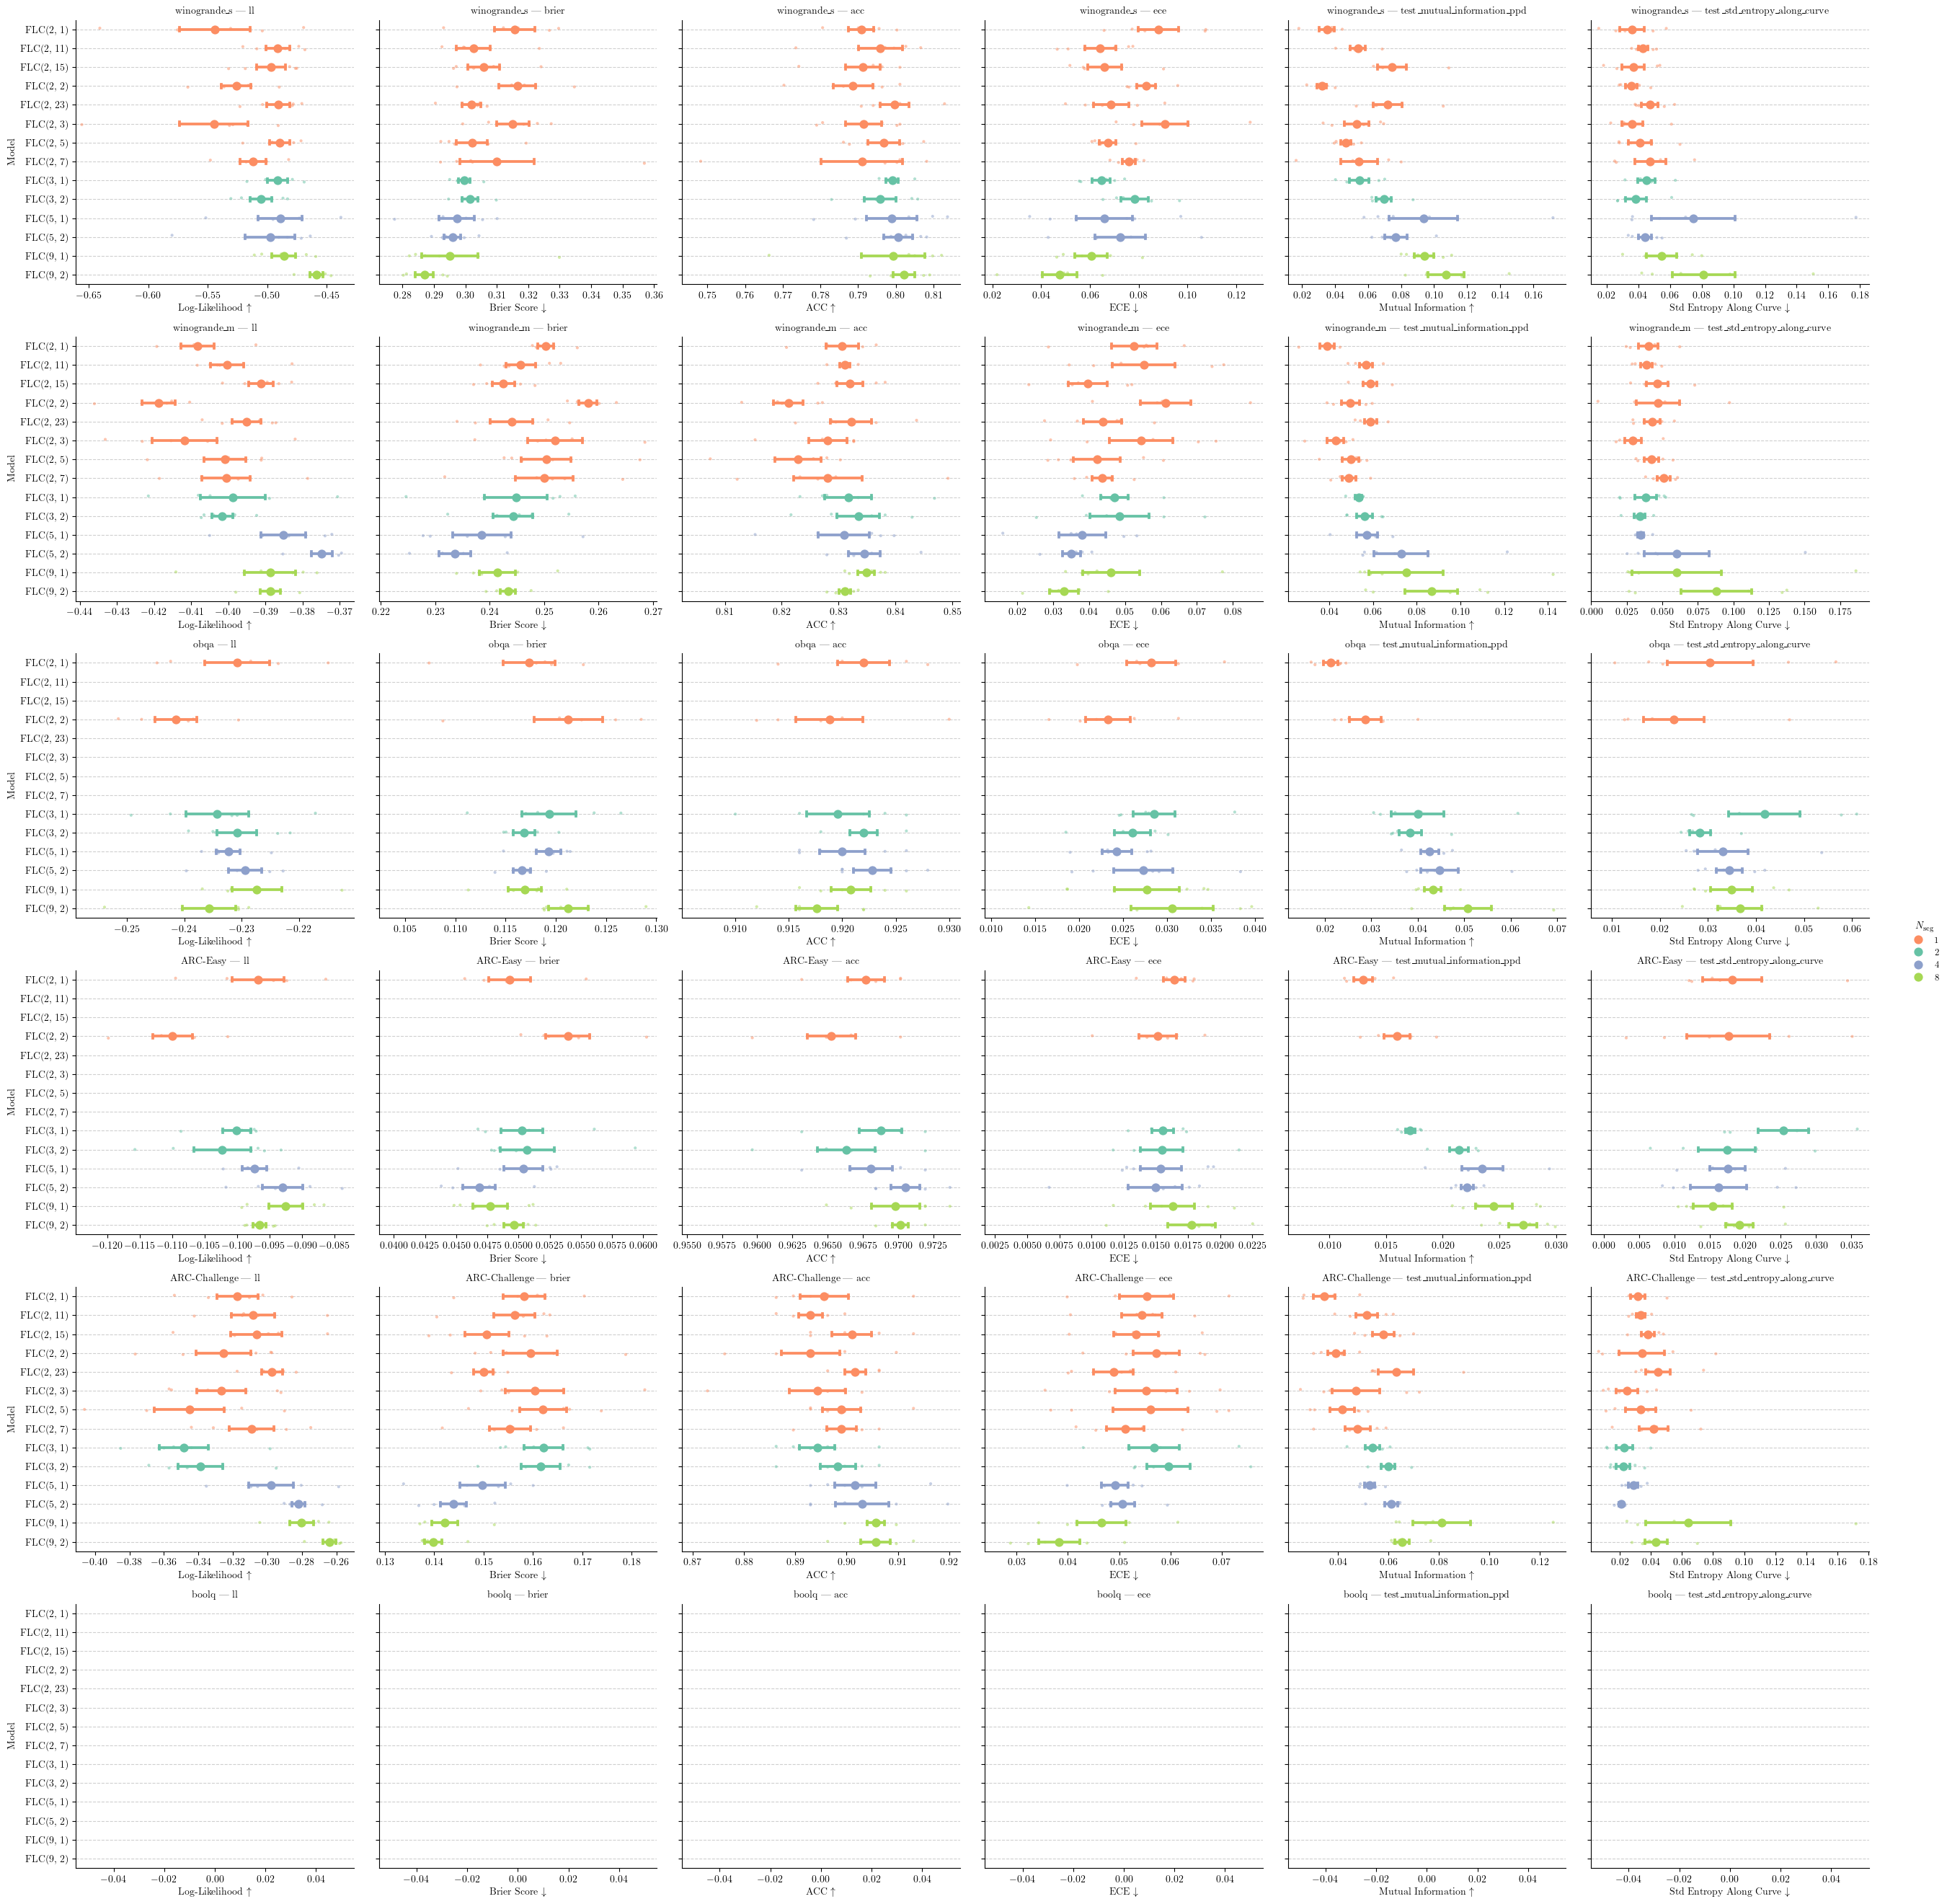

In [85]:
# stack df_vi to df_plot
df_plot[n_seg_name] = df_plot[n_seg_name].astype(int)
df_plot_ = pd.concat([df_plot, ], ignore_index=True)
# hue
# df_plot_[pd.isna(df_plot_[n_seg_name])] = -1
numeric_rhos = sorted(int(x) for x in df_plot_[n_seg_name].unique())
df_plot_[n_seg_name] = df_plot_[n_seg_name].astype(str)
hue_order = [str(x) for x in numeric_rhos]
hue_palette = sns.color_palette("Set2")
hue_palette = {"1": hue_palette[1], "2": hue_palette[0], "4": hue_palette[2], "8": hue_palette[4],}
col_order = "ll", "brier", "acc", "ece", "test_mutual_information_ppd", "test_std_entropy_along_curve"
row_order = "winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge", "boolq"
order = df_plot_['Model'].unique()
# order = ['MAP', 
#          'ScalaBL', 'BLoB', 
#          rf'Linear({n_seg_name}=3)', rf'Linear({n_seg_name}=5)', rf'Linear({n_seg_name}=9)', #'OpenLinear(13)',
#          rf'{free_model_name}({n_seg_name}=2, {seg_deg_name}=2)',
#          rf'{free_model_name}({n_seg_name}=2, {seg_deg_name}=3)', 
#          rf'{free_model_name}({n_seg_name}=3, {seg_deg_name}=2)', 
#          rf'{free_model_name}({n_seg_name}=3, {seg_deg_name}=3)', 
#          rf'{free_model_name}({n_seg_name}=5, {seg_deg_name}=2)',
#          rf'{free_model_name}({n_seg_name}=5, {seg_deg_name}=3)', 
#          rf'{free_model_name}({n_seg_name}=9, {seg_deg_name}=2)',
#          rf'{free_model_name}({n_seg_name}=9, {seg_deg_name}=3)', 
#         #  'Fix=False, N_{n_seg_name}=12, {seg_deg_name}=m$1', 
#         #  'Fix=True, N_{n_seg_name}=12, {seg_deg_name}=1', 
#         #  'Fix=True, N_{n_seg_name}=2, {seg_deg_name}=1',
#          rf'{pretrained_model_name}({n_seg_name}=2, {seg_deg_name}=2)', 
#          rf'{pretrained_model_name}({n_seg_name}=2, {seg_deg_name}=3)', 
#          rf'{pretrained_model_name}({n_seg_name}=3, {seg_deg_name}=2)', 
#          rf'{pretrained_model_name}({n_seg_name}=3, {seg_deg_name}=3)',
#          rf'{pretrained_model_name}({n_seg_name}=5, {seg_deg_name}=2)',
#          rf'{pretrained_model_name}({n_seg_name}=5, {seg_deg_name}=3)',
#          rf'{pretrained_model_name}({n_seg_name}=9, {seg_deg_name}=2)',
#          rf'{pretrained_model_name}({n_seg_name}=9, {seg_deg_name}=3)',
#          rf'DE({n_seg_name}=2)', rf'DE({n_seg_name}=3)', rf'DE({n_seg_name}=5)', rf'DE({n_seg_name}=9)', 
#          'Sampling-PSMILE', 'Sampling-SGHMC']

print(f"Models {set(df_plot_['Model'].unique()) - set(order)} missing:")

# # Prepare descriptive Model labels
# def get_model_label(row):
#     if str(row['Model']).startswith('DE'):
#         return f"{row['Model']}({row['NCurveSegment']})"
#     return f"{row['Model']}"

# df_plot_['Model_Label'] = df_plot_.apply(get_model_label, axis=1)

# # Ensure metric order
# metric_order = ['acc', 'll', 'ece']
# df_plot_['Metric'] = pd.Categorical(df_plot_['Metric'], categories=metric_order, ordered=True)

# Seaborn Catplot (ANOVA style)
g = sns.catplot(
    data=df_plot_, x='value', y='Model',
    row='Dataset', col='Metric',
    row_order=row_order, col_order=col_order,
    order=order,
    kind='point', join=False, capsize=.2,
    markers='o', palette=hue_palette, hue=n_seg_name,
    dodge=False, sharex=False, height=figsize[1]*1.3, aspect=1.,
    legend=True, errorbar="se", hue_order=hue_order,
)

# Overlay strip plots for original points (small, alpha=0.5)
for (ds, metric), ax in g.axes_dict.items():
    subset = df_plot_[(df_plot_['Dataset'] == ds) & (df_plot_['Metric'] == metric)]
    sns.stripplot(
        data=subset, x='value', y='Model',
        order=order,
        ax=ax, palette=hue_palette, alpha=0.5, size=3,
        dodge=False, hue=n_seg_name, legend=False, hue_order=hue_order,
    )
    
    # Refine grid and labels
    ax.grid(True, axis='y', linestyle='--', alpha=0.6)

    # add vertical line at BLob mean value for reference
    subset_blob = subset[subset['Model'] == 'BLoB WB']
    if not subset_blob.empty and np.isfinite(subset_blob['value'].mean()):
        ax.axvline(x=subset_blob['value'].mean(), color='gray', linestyle='--', label='BLoB Mean')
    
    # Label mapping for x-axis
    if metric == 'acc':
        ax.set_xlabel(r'ACC $\uparrow$')
    elif metric == 'll':
        ax.set_xlabel(r'Log-Likelihood $\uparrow$')
    elif metric == 'ece':
        ax.set_xlabel(r'ECE $\downarrow$')
    elif metric == 'brier':
        ax.set_xlabel(r'Brier Score $\downarrow$')
    elif metric == 'test_mutual_information_ppd':
        ax.set_xlabel(r'Mutual Information $\uparrow$') 
    elif metric == 'test_std_entropy_along_curve':
        ax.set_xlabel(r'Std Entropy Along Curve $\downarrow$')

    # clip x-axis to range of min without MAP
    def only_finit(x):
        return x[np.isfinite(x)]
    min_value = only_finit(subset[subset['Model'] != 'MAP']['value']).min()
    mean_value_MAP = only_finit(subset[subset['Model'] == 'MAP']['value']).mean()
    if np.isfinite(min_value):
        ax.set_xlim(left=min(min_value, mean_value_MAP)-0.005)  # add some padding on the left

# Adjust layout and titles
g.set_titles(row_template='{row_name}', col_template='{col_name}')
g.tight_layout()
# g.add_legend(title='#CurveSegments')
# plt.savefig("result/performance_pointplot.pdf", dpi=300)
# plt.savefig("my-overleaf-project/figures/performance_pointplot.pdf", dpi=300, bbox_inches='tight')
plt.show()

In [86]:
df_plot['Model'].unique()

array(['FLC(2, 1)', 'FLC(2, 11)', 'FLC(2, 15)', 'FLC(2, 2)', 'FLC(2, 23)',
       'FLC(2, 3)', 'FLC(2, 5)', 'FLC(2, 7)', 'FLC(3, 1)', 'FLC(3, 2)',
       'FLC(5, 1)', 'FLC(5, 2)', 'FLC(9, 1)', 'FLC(9, 2)'], dtype=object)

/tmp/ipykernel_2347890/318063253.py:38: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


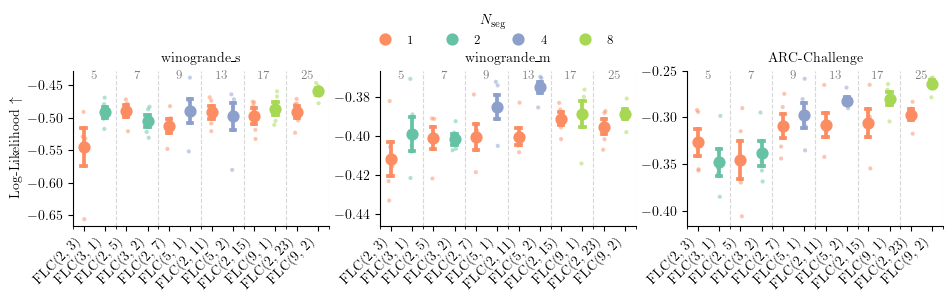

In [87]:
from matplotlib import ticker
# Only LL metric plotted with col='Dataset' and col_wrap=3
# stack df_vi to df_plot
hue_name = n_seg_name
df_plot[hue_name] = df_plot[hue_name].astype(int)
df_plot_ = pd.concat([df_plot,], ignore_index=True)
# hue
numeric_rhos = sorted(int(x) for x in df_plot_[hue_name].unique())
df_plot_[hue_name] = df_plot_[hue_name].astype(str)
hue_order = [str(x) for x in numeric_rhos]
hue_palette = sns.color_palette("Set2")
hue_palette = {"1": hue_palette[1], "2": hue_palette[0], "4": hue_palette[2], "8": hue_palette[4],}
df_plot_ll = df_plot_[df_plot_['Metric'] == 'll'].copy()

# col_order_ds = ["winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge"]
col_order_ds = ["winogrande_s", "winogrande_m", "ARC-Challenge"]
order = [
        #  f'DE({n_seg_name}=5)',
         f'FLC(2, 3)',
         f'FLC(3, 1)',
         f'FLC(2, 5)',
         f'FLC(3, 2)',

         f'FLC(2, 7)',
         f'FLC(5, 1)',
         f'FLC(2, 11)',
         f'FLC(5, 2)',

         f'FLC(2, 15)',
         f'FLC(9, 1)',
         f'FLC(2, 23)',
         f'FLC(9, 2)',
        #  f'Linear({n_seg_name}=5)', #'OpenLinear(13)',
        #  rf'{free_model_name}({n_seg_name}=5, {seg_deg_name}=3)',
        #  rf'{pretrained_model_name}({n_seg_name}=5, {seg_deg_name}=3)',
         ]

g = sns.catplot(
    data=df_plot_ll, x='Model', y='value',
    col='Dataset', col_wrap=5,
    col_order=col_order_ds,
    order=order,
    kind='point', join=False, capsize=.2,
    markers='o', palette=hue_palette, hue=hue_name,
    dodge=False, sharey=False, height=figsize[1]/1.5, aspect=1.4,
    legend=True, errorbar="se", hue_order=hue_order,
)

# Overlay strip plots for original points (small, alpha=0.5)
for ds, ax in g.axes_dict.items():
    subset = df_plot_ll[df_plot_ll['Dataset'] == ds]
    sns.stripplot(
        data=subset, x='Model', y='value',
        order=order,
        ax=ax, palette=hue_palette, alpha=0.5, size=3,
        dodge=False, hue=hue_name, legend=False, hue_order=hue_order,
    )
    
    # Refine grid and labels
    # ax.grid(True, axis='x', linestyle='--', alpha=0.6)
    
    # Label mapping for y-axis
    ax.set_ylabel(r'Log-Likelihood $\uparrow$')
    ax.set_xlabel('')

    # clip y-axis to range of min without MAP
    def only_finit(x):
        return x[np.isfinite(x)]
    
    non_map_vals = only_finit(subset[subset['Model'] != 'MAP']['value'])
    map_vals = only_finit(subset[subset['Model'] == 'MAP']['value'])
    
    min_value = non_map_vals.min() if not non_map_vals.empty else np.nan
    mean_value_MAP = map_vals.mean() if not map_vals.empty else np.nan
    mean_value_MAP  = np.quantile(map_vals, 0.25) if not map_vals.empty else np.nan  # use 25th percentile to be more robust against outliers
    
    if np.isfinite(min_value) and np.isfinite(mean_value_MAP):
        ax.set_ylim(bottom=min(min_value, mean_value_MAP)-0.01)  # add some padding on the bottom
    elif np.isfinite(min_value):
        ax.set_ylim(bottom=min_value-0.01)

# Adjust layout and titles
g.set_titles(col_template='{col_name}')
g.tight_layout()

#legent top flat
sns.move_legend(g, loc='upper center', bbox_to_anchor=(0.3, 1.15), ncol=len(hue_order), title=hue_name)
# rotate x labels
for i, ax in enumerate(g.axes):
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
    # plt.setp(ax.get_yticklabels(), rotation=20, ha='right')
    if i > 0:
        ax.set_ylabel('')  # remove x-axis label since it's redundant with the rotated labels
# set wspace
# g.axes[1].set_yticks([-0.37, -0.4, -0.43, -0.46])  # remove y-ticks for middle plot to save space
g.fig.subplots_adjust(wspace=0.2)

block_labels = [r"$N_{\mathrm{cp}}=5$", r"$N_{\mathrm{cp}}=7$", r"$N_{\mathrm{cp}}=9$", r"$N_{\mathrm{cp}}=13$", r"$N_{\mathrm{cp}}=17$", r"$N_{\mathrm{cp}}=25$"]
block_labels = ["5", "7", "9", "13", "17", "25"]

for ax in g.axes:
    # 1. Define and set the minor ticks
    minor_ticks = np.arange(-0.5, len(order), 2)
    ax.xaxis.set_minor_locator(ticker.FixedLocator(minor_ticks))
    
    # 2. Add text at the top of each block
    # We find the center of each block (the major tick positions)
    # Block 1 is between start and 0.5, Block 2 between 0.5 and 2.5, etc.
    # For simplicity, if minor ticks are at 0.5, 2.5, the centers are 1.5, 3.5...
    # The first block center is at 0 (the first model)
    label_positions = list(np.arange(.5, len(order), 2))
    
    for i, pos in enumerate(label_positions):
        if i < len(block_labels):
            ax.text(
                x=pos, 
                y=.93, # Slightly above the top of the axes (0 to 1 scale)
                s=block_labels[i],
                transform=ax.get_xaxis_transform(), # x in data coords, y in 0-1 coords
                ha='center', 
                va='bottom',
                fontsize=9,
                fontweight='bold',
                color='gray',
                rotation=0
            )
# for ax in g.axes:
    # # add microticks to x-axis
    # minor_ticks = np.arange(-0.5, len(order), 2)
    # ax.xaxis.set_minor_locator(ticker.FixedLocator(minor_ticks))
    # # set micro ticks vertical grid line
    ax.grid(True, which='minor', axis='x', linestyle='--', alpha=0.5)
    # set major ticks vertical grid line
    # ax.grid(True, which='major', axis='x', linestyle='--', alpha=0.7)
    # set minor ticks to be visible
    # ax.tick_params(which='minor', length=4, color='gray')   

plt.savefig("result/performance_segment_vs_curve.pdf", dpi=300, bbox_inches='tight')
# plt.savefig("my-overleaf-project/figures/performance_segment_vs_curve.pdf", dpi=300, bbox_inches='tight')
plt.show()

/tmp/ipykernel_2347890/1096118910.py:38: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


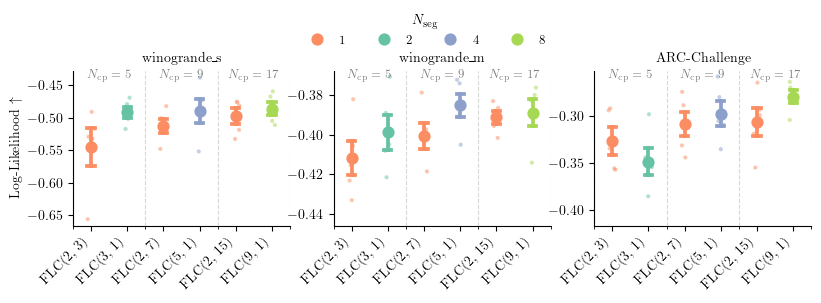

In [88]:
from matplotlib import ticker
# Only LL metric plotted with col='Dataset' and col_wrap=3
# stack df_vi to df_plot
hue_name = n_seg_name
df_plot[hue_name] = df_plot[hue_name].astype(int)
df_plot_ = pd.concat([df_plot,], ignore_index=True)
# hue
numeric_rhos = sorted(int(x) for x in df_plot_[hue_name].unique())
df_plot_[hue_name] = df_plot_[hue_name].astype(str)
hue_order = [str(x) for x in numeric_rhos]
hue_palette = sns.color_palette("Set2")
hue_palette = {"1": hue_palette[1], "2": hue_palette[0], "4": hue_palette[2], "8": hue_palette[4],}
df_plot_ll = df_plot_[df_plot_['Metric'] == 'll'].copy()

# col_order_ds = ["winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge"]
col_order_ds = ["winogrande_s", "winogrande_m", "ARC-Challenge"]
order = [
        #  f'DE({n_seg_name}=5)',
         f'FLC(2, 3)',
         f'FLC(3, 1)',
        #  f'FLC(2, 5)',
        #  f'FLC(3, 2)',

         f'FLC(2, 7)',
         f'FLC(5, 1)',
        #  f'FLC(2, 11)',
        #  f'FLC(5, 2)',

         f'FLC(2, 15)',
         f'FLC(9, 1)',
        #  f'FLC(2, 23)',
        #  f'FLC(9, 2)',
        #  f'Linear({n_seg_name}=5)', #'OpenLinear(13)',
        #  rf'{free_model_name}({n_seg_name}=5, {seg_deg_name}=3)',
        #  rf'{pretrained_model_name}({n_seg_name}=5, {seg_deg_name}=3)',
         ]

g = sns.catplot(
    data=df_plot_ll, x='Model', y='value',
    col='Dataset', col_wrap=5,
    col_order=col_order_ds,
    order=order,
    kind='point', join=False, capsize=.2,
    markers='o', palette=hue_palette, hue=hue_name,
    dodge=False, sharey=False, height=figsize[1]/1.5, aspect=1.2,
    legend=True, errorbar="se", hue_order=hue_order,
)

# Overlay strip plots for original points (small, alpha=0.5)
for ds, ax in g.axes_dict.items():
    subset = df_plot_ll[df_plot_ll['Dataset'] == ds]
    sns.stripplot(
        data=subset, x='Model', y='value',
        order=order,
        ax=ax, palette=hue_palette, alpha=0.5, size=3,
        dodge=False, hue=hue_name, legend=False, hue_order=hue_order,
    )
    
    # Refine grid and labels
    # ax.grid(True, axis='x', linestyle='--', alpha=0.6)
    
    # Label mapping for y-axis
    ax.set_ylabel(r'Log-Likelihood $\uparrow$')
    ax.set_xlabel('')

    # clip y-axis to range of min without MAP
    def only_finit(x):
        return x[np.isfinite(x)]
    
    non_map_vals = only_finit(subset[subset['Model'] != 'MAP']['value'])
    map_vals = only_finit(subset[subset['Model'] == 'MAP']['value'])
    
    min_value = non_map_vals.min() if not non_map_vals.empty else np.nan
    mean_value_MAP = map_vals.mean() if not map_vals.empty else np.nan
    mean_value_MAP  = np.quantile(map_vals, 0.25) if not map_vals.empty else np.nan  # use 25th percentile to be more robust against outliers
    
    if np.isfinite(min_value) and np.isfinite(mean_value_MAP):
        ax.set_ylim(bottom=min(min_value, mean_value_MAP)-0.01)  # add some padding on the bottom
    elif np.isfinite(min_value):
        ax.set_ylim(bottom=min_value-0.01)

# Adjust layout and titles
g.set_titles(col_template='{col_name}')
g.tight_layout()

#legent top flat
sns.move_legend(g, loc='upper center', bbox_to_anchor=(0.3, 1.15), ncol=len(hue_order), title=hue_name)
# rotate x labels
for i, ax in enumerate(g.axes):
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
    # plt.setp(ax.get_yticklabels(), rotation=20, ha='right')
    if i > 0:
        ax.set_ylabel('')  # remove x-axis label since it's redundant with the rotated labels
# set wspace
# g.axes[1].set_yticks([-0.37, -0.4, -0.43, -0.46])  # remove y-ticks for middle plot to save space
g.fig.subplots_adjust(wspace=0.2)

block_labels = [r"$N_{\mathrm{cp}}=5$", r"$N_{\mathrm{cp}}=9$", r"$N_{\mathrm{cp}}=17$"]
# block_labels = ["5", "9", "17"]

for ax in g.axes:
    # 1. Define and set the minor ticks
    minor_ticks = np.arange(-0.5, len(order), 2)
    ax.xaxis.set_minor_locator(ticker.FixedLocator(minor_ticks))
    
    # 2. Add text at the top of each block
    # We find the center of each block (the major tick positions)
    # Block 1 is between start and 0.5, Block 2 between 0.5 and 2.5, etc.
    # For simplicity, if minor ticks are at 0.5, 2.5, the centers are 1.5, 3.5...
    # The first block center is at 0 (the first model)
    label_positions = list(np.arange(.5, len(order), 2))
    
    for i, pos in enumerate(label_positions):
        if i < len(block_labels):
            ax.text(
                x=pos, 
                y=.93, # Slightly above the top of the axes (0 to 1 scale)
                s=block_labels[i],
                transform=ax.get_xaxis_transform(), # x in data coords, y in 0-1 coords
                ha='center', 
                va='bottom',
                fontsize=9,
                fontweight='bold',
                color='gray',
                rotation=0
            )
# for ax in g.axes:
    # # add microticks to x-axis
    # minor_ticks = np.arange(-0.5, len(order), 2)
    # ax.xaxis.set_minor_locator(ticker.FixedLocator(minor_ticks))
    # # set micro ticks vertical grid line
    ax.grid(True, which='minor', axis='x', linestyle='--', alpha=0.5)
    # set major ticks vertical grid line
    # ax.grid(True, which='major', axis='x', linestyle='--', alpha=0.7)
    # set minor ticks to be visible
    # ax.tick_params(which='minor', length=4, color='gray')   

plt.savefig("result/performance_segment_vs_curve_v2.pdf", dpi=300, bbox_inches='tight')
# plt.savefig("my-overleaf-project/figures/performance_segment_vs_curve_v2.pdf", dpi=300, bbox_inches='tight')
plt.show()

/tmp/ipykernel_2347890/956423663.py:38: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


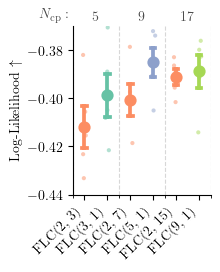

In [89]:
from matplotlib import ticker
# Only LL metric plotted with col='Dataset' and col_wrap=3
# stack df_vi to df_plot
hue_name = n_seg_name
df_plot[hue_name] = df_plot[hue_name].astype(int)
df_plot_ = pd.concat([df_plot,], ignore_index=True)
# hue
numeric_rhos = sorted(int(x) for x in df_plot_[hue_name].unique())
df_plot_[hue_name] = df_plot_[hue_name].astype(str)
hue_order = [str(x) for x in numeric_rhos]
hue_palette = sns.color_palette("Set2")
hue_palette = {"1": hue_palette[1], "2": hue_palette[0], "4": hue_palette[2], "8": hue_palette[4],}
df_plot_ll = df_plot_[df_plot_['Metric'] == 'll'].copy()

# col_order_ds = ["winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge"]
col_order_ds = ["winogrande_m",]
order = [
        #  f'DE({n_seg_name}=5)',
         f'FLC(2, 3)',
         f'FLC(3, 1)',
        #  f'FLC(2, 5)',
        #  f'FLC(3, 2)',

         f'FLC(2, 7)',
         f'FLC(5, 1)',
        #  f'FLC(2, 11)',
        #  f'FLC(5, 2)',

         f'FLC(2, 15)',
         f'FLC(9, 1)',
        #  f'FLC(2, 23)',
        #  f'FLC(9, 2)',
        #  f'Linear({n_seg_name}=5)', #'OpenLinear(13)',
        #  rf'{free_model_name}({n_seg_name}=5, {seg_deg_name}=3)',
        #  rf'{pretrained_model_name}({n_seg_name}=5, {seg_deg_name}=3)',
         ]

g = sns.catplot(
    data=df_plot_ll, x='Model', y='value',
    col='Dataset', col_wrap=5,
    col_order=col_order_ds,
    order=order,
    kind='point', join=False, capsize=.2,
    markers='o', palette=hue_palette, hue=hue_name,
    dodge=False, sharey=False, height=figsize[1]/1.2, aspect=.6,
    legend=True, errorbar="se", hue_order=hue_order,
)

# Overlay strip plots for original points (small, alpha=0.5)
for ds, ax in g.axes_dict.items():
    subset = df_plot_ll[df_plot_ll['Dataset'] == ds]
    sns.stripplot(
        data=subset, x='Model', y='value',
        order=order,
        ax=ax, palette=hue_palette, alpha=0.5, size=3,
        dodge=False, hue=hue_name, legend=False, hue_order=hue_order,
    )
    
    # Refine grid and labels
    # ax.grid(True, axis='x', linestyle='--', alpha=0.6)
    
    # Label mapping for y-axis
    ax.set_ylabel(r'Log-Likelihood $\uparrow$')
    ax.set_xlabel('')

    # clip y-axis to range of min without MAP
    def only_finit(x):
        return x[np.isfinite(x)]
    
    non_map_vals = only_finit(subset[subset['Model'] != 'MAP']['value'])
    map_vals = only_finit(subset[subset['Model'] == 'MAP']['value'])
    
    min_value = non_map_vals.min() if not non_map_vals.empty else np.nan
    mean_value_MAP = map_vals.mean() if not map_vals.empty else np.nan
    mean_value_MAP  = np.quantile(map_vals, 0.25) if not map_vals.empty else np.nan  # use 25th percentile to be more robust against outliers
    
    if np.isfinite(min_value) and np.isfinite(mean_value_MAP):
        ax.set_ylim(bottom=min(min_value, mean_value_MAP)-0.01)  # add some padding on the bottom
    elif np.isfinite(min_value):
        ax.set_ylim(bottom=min_value-0.01)

# Adjust layout and titles
g.set_titles(col_template='{col_name}')
g.set_titles(col_template='')

#legent top flat
sns.move_legend(g, loc='upper center', bbox_to_anchor=(0.12, 1.2), ncol=len(hue_order), title=hue_name)
# rotate x labels
for i, ax in enumerate(g.axes):
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
    # plt.setp(ax.get_yticklabels(), rotation=20, ha='right')
    if i > 0:
        ax.set_ylabel('')  # remove x-axis label since it's redundant with the rotated labels
# set wspace
# g.axes[1].set_yticks([-0.37, -0.4, -0.43, -0.46])  # remove y-ticks for middle plot to save space
g.fig.subplots_adjust(wspace=0.2)

# block_labels = [r"$N_{\mathrm{cp}}=5$", r"$N_{\mathrm{cp}}=9$", r"$N_{\mathrm{cp}}=17$"]
block_labels = [r"$5$", r"$9$", r"$17$"]
# block_labels = ["5", "9", "17"]

for ax in g.axes:
    # 1. Define and set the minor ticks
    minor_ticks = np.arange(-0.5, len(order), 2)
    ax.xaxis.set_minor_locator(ticker.FixedLocator(minor_ticks))

    ax.text(
        x=-2., 
        y=1.02, # Slightly above the top of the axes (0 to 1 scale)
        s=r"$N_{\mathrm{cp}}:$",  # Dataset label
        transform=ax.get_xaxis_transform(), # x in data coords, y in 0-1 coords
        ha='left', 
        va='bottom',
        fontsize=10,
        fontweight='bold',
        color=(0.3, 0.3, 0.3),
        rotation=0
    )
    
    # 2. Add text at the top of each block
    # We find the center of each block (the major tick positions)
    # Block 1 is between start and 0.5, Block 2 between 0.5 and 2.5, etc.
    # For simplicity, if minor ticks are at 0.5, 2.5, the centers are 1.5, 3.5...
    # The first block center is at 0 (the first model)
    label_positions = list(np.arange(.5, len(order), 2))
    
    for i, pos in enumerate(label_positions):
        if i < len(block_labels):
            ax.text(
                x=pos, 
                y=1.02, # Slightly above the top of the axes (0 to 1 scale)
                s=block_labels[i],
                transform=ax.get_xaxis_transform(), # x in data coords, y in 0-1 coords
                ha='center', 
                va='bottom',
                fontsize=10,
                fontweight='bold',
                color=(0.3, 0.3, 0.3),
                rotation=0
            )
# for ax in g.axes:
    # # add microticks to x-axis
    # minor_ticks = np.arange(-0.5, len(order), 2)
    # ax.xaxis.set_minor_locator(ticker.FixedLocator(minor_ticks))
    # # set micro ticks vertical grid line
    ax.grid(True, which='minor', axis='x', linestyle='--', alpha=0.5)
    # set major ticks vertical grid line
    # ax.grid(True, which='major', axis='x', linestyle='--', alpha=0.7)
    # set minor ticks to be visible
    # ax.tick_params(which='minor', length=4, color='gray')   
    ax.set_ylim(bottom=-0.44, top=-0.37)  # set same y limit for all plots to make them comparable

# ==========================================
# EXTRACT AND REMOVE LEGEND
# ==========================================
# Seaborn stores the figure-level legend in g.legend
if g.legend is not None:
    # 1. Safely extract handles, text labels, and title from the Seaborn legend
    handles = g.legend.legend_handles
    labels = [t.get_text() for t in g.legend.get_texts()]
    legend_title = g.legend.get_title().get_text()
    
    # 2. Export it using the helper function
    export_standalone_legend(
        handles, 
        labels, 
        title=legend_title, 
        filename="my-overleaf-project/new_figures/performance_segment_vs_curve_v2_legend.pdf",
        columnspacing=1.0,  # Decrease to bring columns closer together (default is ~2.0)
        handletextpad=0.2,  # Decrease to bring the number closer to the dot (default is ~0.8)
        # fontsize='large',
        ncols=4
    )
    
    # 3. Remove the legend from the original plot completely
    g.legend.remove()

g.tight_layout()
plt.savefig("result/performance_segment_vs_curve_v2.pdf", dpi=300, bbox_inches='tight')
plt.savefig("my-overleaf-project/new_figures/performance_segment_vs_curve_v2.pdf", dpi=300, bbox_inches='tight', pad_inches=0.05)
plt.show()

In [90]:

[r"N_{\mathrm{cp}}=5$" for i in [5,7,9,13,17,25]]
[r"N_{\mathrm{cp}}=5$", r"N_{\mathrm{cp}}=7$", r"N_{\mathrm{cp}}=9$", r"N_{\mathrm{cp}}=13$", r"N_{\mathrm{cp}}=17$", r"N_{\mathrm{cp}}=25$"]

['N_{\\mathrm{cp}}=5$',
 'N_{\\mathrm{cp}}=7$',
 'N_{\\mathrm{cp}}=9$',
 'N_{\\mathrm{cp}}=13$',
 'N_{\\mathrm{cp}}=17$',
 'N_{\\mathrm{cp}}=25$']

## loss landscape

In [30]:
import os
import logging
import wandb
import numpy as np
from scipy.special import logsumexp
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from pathlib import Path

def get_model_name(cp_fix):
    if cp_fix == [1, 1, 1]:
        return "Lin(3)"
    elif cp_fix == [1, 0, 1, 0, 1]:
        return "ALC(3,1)"
    elif cp_fix == [0, 0, 0, 0, 0]:
        return "FLC(3,1)"
    elif cp_fix == [1, 0, 0, 1, 0, 0, 1]:
        return "ALC(3,2)"
    elif cp_fix == [0, 0, 0, 0, 0, 0, 0]:
        return "FLC(3,2)"
    else:
        return f"cp_fix={cp_fix}"

def load_ll_for_cp_fix(project_path="ddold/qwen_PtoC_seg", target_cp_fix_list=[[1, 1, 1]]):
    """
    Fetches runs from W&B, filters for a specific cp_fix, and combine datasets into one plot
    using seaborn relplot with lineplot.
    """
    api = wandb.Api()
    print(f"Fetching runs from {project_path}...")
    
    runs = api.runs(project_path)
    download_dir = Path("tmp_artifacts")
    download_dir.mkdir(exist_ok=True)
    
    KNOWN_DATASETS = ["winogrande_s", "winogrande_m", "ARC-Challenge", "ARC-Easy", "obqa", "boolq"]
    def get_dataset_name(ds_path):
        for kd in KNOWN_DATASETS:
            if kd in ds_path: return kd
        return Path(ds_path).stem

    # We will collect everything into a list of dictionaries to build a DataFrame
    records = []

    for target_cp_fix in target_cp_fix_list:
        for run in runs:
            if hasattr(run, "tags") and run.tags and any("hide" in str(tag).lower() for tag in run.tags):
                continue
            if hasattr(run, "sweep") and run.sweep is None:
                continue
                
            cfg = run.config.get("model_params", {})
            cp_fix = cfg.get("cp_fix", [])
            if cp_fix != target_cp_fix:
                continue

            mp = run.config.get("model_params", {})
            if mp.get('curve_segment', False) == False:
                NCurveSegment = 1
                CurveDegree = len(mp['cp_fix']) - 1
            else:
                NCurveSegment=(len(mp['cp_fix']) - 1) // mp['curve_segment']
                CurveDegree = mp['curve_segment']
            if NCurveSegment != 2:
                continue
                
            data_cfg = run.config.get("data", {})
            ds_path = data_cfg.get("dataset_path", "")
            if not ds_path:
                continue
                
            dataset_name = get_dataset_name(ds_path)
            print(f"Processing run: {run.name} | Dataset: {dataset_name} | cp_fix: {cp_fix}")
            
            artifacts = list(run.logged_artifacts())
            logits_artifact = next((a for a in artifacts if "logits" in a.name and a.type == "npz"), None)
            if not logits_artifact:
                continue
                
            art_dir = download_dir / run.id
            logits_artifact.download(root=str(art_dir))
            
            seg_deg = cfg.get("curve_segment", False) or 1
            n_seg = (len(cp_fix) - 1) // seg_deg
            max_t = float(n_seg)
            
            # Load both train and test/val
            for split in ["train",]:
                file_path = list(art_dir.glob(f"*{split}_logits.npz"))
                if not file_path and split == "test":
                    file_path = list(art_dir.glob("*val_logits.npz"))
                if not file_path:
                    continue
                    
                npz = np.load(file_path[0])
                logits = npz["logits"]
                labels = npz["labels"]
                
                n_t = logits.shape[0]
                t_space = np.linspace(0, max_t, n_t)
                
                log_probs = logits - logsumexp(logits, axis=-1, keepdims=True)
                true_log_probs = log_probs[:, np.arange(len(labels)), labels]
                ll_list = np.mean(true_log_probs, axis=1)

                acc_list = np.mean((logits.argmax(axis=-1) == labels), axis=1)
                
                # Store absolute LL point by point for pandas manipulation
                for t_val, ll_val, acc_val in zip(t_space, ll_list, acc_list):
                    records.append({
                        "Dataset": dataset_name,
                        "Model": get_model_name(cp_fix),
                        "t": t_val,
                        "LL": ll_val,
                        "ACC": acc_val,
                        "Run_ID": run.id
                    })

        if not records:
            print(f"No run found with cp_fix == {target_cp_fix}")
            return

    df = pd.DataFrame(records)
    return df

# Run the function
# df = load_ll_for_cp_fix(target_cp_fix_list=[[1,1,1],[1, 0, 0, 1, 0, 0, 1], [0, 0, 0, 0, 0, 0, 0, 0]])
df = load_ll_for_cp_fix(target_cp_fix_list=[[1,1,1],[1, 0, 1, 0, 1], [0, 0, 0, 0, 0,]])

Fetching runs from ddold/qwen_PtoC_seg...


wandb:   3 of 3 files downloaded.  


Processing run: northern-sweep-1 | Dataset: winogrande_m | cp_fix: [1, 1, 1]
Processing run: curious-sweep-2 | Dataset: winogrande_m | cp_fix: [1, 1, 1]


wandb:   3 of 3 files downloaded.  
wandb:   3 of 3 files downloaded.  


Processing run: upbeat-sweep-3 | Dataset: winogrande_m | cp_fix: [1, 1, 1]
Processing run: rose-sweep-4 | Dataset: winogrande_m | cp_fix: [1, 1, 1]


wandb:   3 of 3 files downloaded.  
wandb:   3 of 3 files downloaded.  


... (110 outputs left out)

Processing run: confused-sweep-27 | Dataset: ARC-Easy | cp_fix: [0, 0, 0, 0, 0]
Processing run: bumbling-sweep-28 | Dataset: ARC-Easy | cp_fix: [0, 0, 0, 0, 0]


wandb:   3 of 3 files downloaded.  
wandb:   3 of 3 files downloaded.  


Processing run: smooth-sweep-29 | Dataset: ARC-Easy | cp_fix: [0, 0, 0, 0, 0]
Processing run: sunny-sweep-30 | Dataset: ARC-Easy | cp_fix: [0, 0, 0, 0, 0]


wandb:   3 of 3 files downloaded.  


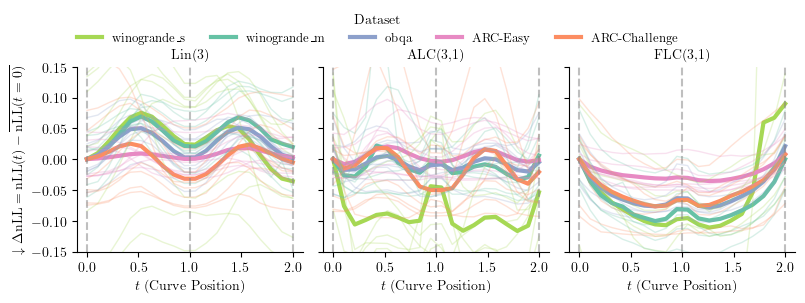

In [31]:
def plot_combined_datasets(df):
    # 1. Compute the mean LL per dataset and split at exactly t=0
    # Floating point comparisons can be tricky, using np.isclose for safety.
    df_t0 = df[np.isclose(df['t'], 0.0)]
    t0_means = df_t0.groupby(['Dataset', 'Model'])['LL'].mean().reset_index()
    t0_means = t0_means.rename(columns={'LL': 't0_mean_LL'})

    # 2. Merge these means back into the main dataframe
    df = df.merge(t0_means, on=['Dataset', 'Model'], how='left')

    # # 1. Compute the mean LL per dataset and split at exactly t=0
    # # use Linear(3) as baseline for all models
    # df_t0 = df[np.isclose(df['t'], 0.0)]
    # df_t0 = df_t0[df_t0['Model'] == 'Lin(3)']  # Filter for Linear(3) only
    # t0_means = df_t0.groupby(['Dataset'])['LL'].mean().reset_index()
    # t0_means = t0_means.rename(columns={'LL': 't0_mean_LL'})

    # # 2. Merge these means back into the main dataframe
    # df = df.merge(t0_means, on=['Dataset'], how='left')


    # 3. Calculate the relative LL compared to the dataset/split mean at t=0
    df['Relative_nLL'] = -df['LL'] + df['t0_mean_LL']
    # df['Relative_nLL'] = df['LL'] - df['t0_mean_LL']
    
    # 4. Define custom palette and order using *only* Set2 colors
    hue_order = ["winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge",]
    # hue_order = ["winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge", "boolq"]
    set2 = sns.color_palette("Set2")
    custom_palette = {
        "winogrande_m": set2[0],   # dark green/teal
        "winogrande_s": set2[4],   # light green
        "obqa": set2[2],           # blue
        "ARC-Challenge": set2[1],  # orange
        "ARC-Easy": set2[3],       # red/pink
        "boolq": set2[7]           # grey
    }

    # Use seaborn relplot to create the facet grid lineplot for mean lines first
    g = sns.relplot(
        data=df,
        x="t",
        y="Relative_nLL",
        hue="Dataset",
        hue_order=hue_order,
        col="Model",
        kind="line",
        estimator="mean",      # Mean lines
        errorbar=None,
        height=figsize[0] / 2,
        aspect=1.,
        linewidth=3.0,         
        palette=custom_palette
    )

    # Now overlay the individual runs logic onto the existing axes
    for ax, model_name in zip(g.axes.flatten(), df['Model'].unique()):
        model_data = df[df['Model'] == model_name]
        if model_data.empty: continue
        
        # We manually plot the individual lines via standard sns.lineplot with thinner transparency
        sns.lineplot(
            data=model_data, 
            x="t", 
            y="Relative_nLL", 
            hue="Dataset",
            hue_order=hue_order,
            ax=ax, 
            units="Run_ID",
            estimator=None,     
            linewidth=1.0,
            alpha=0.25,
            legend=False,      # Legend already exists from relplot
            palette=custom_palette
        )

    g.set_axis_labels(r"$t$ (Curve Position)", r"$\downarrow \Delta \mathrm{nLL} = \mathrm{nLL}(t) -  \overline{\mathrm{nLL}(t=0)}$")
    
    # Add grids
    for ax in g.axes.flatten():
        # ax.grid(True, linestyle="--", alpha=0.6)
        ax.set_ylim(-0.15, 0.15)
        # make vline at t=0 and t=1 and t=2
        ax.axvline(x=0, color='gray', linestyle='--', alpha=0.5)
        ax.axvline(x=1, color='gray', linestyle='--', alpha=0.5)
        ax.axvline(x=2, color='gray', linestyle='--', alpha=0.5)
    
    # move legend to top center
    sns.move_legend(g, loc='upper center', bbox_to_anchor=(0.4, 1.11), ncol=len(hue_order), title="Dataset")
    g.set_titles(col_template='{col_name}')


    g.tight_layout()
    plt.savefig("my-overleaf-project/new_figures/LinearModeConnect_Losslandscape.pdf", dpi=300, bbox_inches='tight', pad_inches=0.05)

plot_combined_datasets(df)

Dataset        Model   
ARC-Challenge  ALC(3,1)    8
               FLC(3,1)    6
               Lin(3)      8
ARC-Easy       ALC(3,1)    8
               FLC(3,1)    6
               Lin(3)      8
obqa           ALC(3,1)    8
               FLC(3,1)    6
               Lin(3)      8
winogrande_m   ALC(3,1)    8
               FLC(3,1)    6
               Lin(3)      8
winogrande_s   ALC(3,1)    8
               FLC(3,1)    6
               Lin(3)      8
Name: LL, dtype: int64


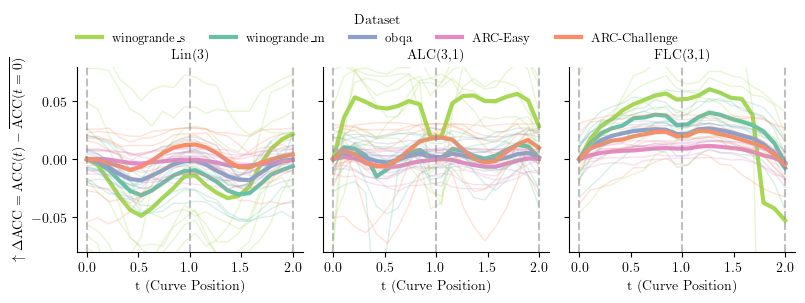

In [35]:
def plot_combined_datasets(df):
    # 1. Compute the mean LL per dataset and split at exactly t=0
    # Floating point comparisons can be tricky, using np.isclose for safety.
    df_t0 = df[np.isclose(df['t'], 0.0)]
    print(df_t0.groupby(['Dataset', 'Model'])['LL'].count())
    t0_means = df_t0.groupby(['Dataset', 'Model'])['ACC'].mean().reset_index()
    t0_means = t0_means.rename(columns={'ACC': 't0_mean_ACC'})

    # 2. Merge these means back into the main dataframe
    df = df.merge(t0_means, on=['Dataset', 'Model'], how='left')

    # 3. Calculate the relative ACC compared to the dataset/split mean at t=0
    df['Relative_ACC'] = df['ACC'] - df['t0_mean_ACC']
    
    # 4. Define custom palette and order using *only* Set2 colors
    hue_order = ["winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge",]
    # hue_order = ["winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge", "boolq"]
    set2 = sns.color_palette("Set2")
    custom_palette = {
        "winogrande_m": set2[0],   # dark green/teal
        "winogrande_s": set2[4],   # light green
        "obqa": set2[2],           # blue
        "ARC-Challenge": set2[1],  # orange
        "ARC-Easy": set2[3],       # red/pink
        "boolq": set2[7]           # grey
    }

    # Use seaborn relplot to create the facet grid lineplot for mean lines first
    g = sns.relplot(
        data=df,
        x="t",
        y="Relative_ACC",
        hue="Dataset",
        hue_order=hue_order,
        col="Model",
        kind="line",
        estimator="mean",      # Mean lines
        errorbar=None,
        height=figsize[0] / 2,
        aspect=1.,
        linewidth=3.0,         
        palette=custom_palette
    )

    # Now overlay the individual runs logic onto the existing axes
    for ax, model_name in zip(g.axes.flatten(), df['Model'].unique()):
        model_data = df[df['Model'] == model_name]
        if model_data.empty: continue
        
        # We manually plot the individual lines via standard sns.lineplot with thinner transparency
        sns.lineplot(
            data=model_data, 
            x="t", 
            y="Relative_ACC", 
            hue="Dataset",
            hue_order=hue_order,
            ax=ax, 
            units="Run_ID",
            estimator=None,     
            linewidth=1.0,
            alpha=0.25,
            legend=False,      # Legend already exists from relplot
            palette=custom_palette
        )

    g.set_axis_labels("t (Curve Position)",r"$\uparrow \Delta \mathrm{ACC} = \mathrm{ACC}(t) -  \overline{\mathrm{ACC}(t=0)}$")
    
    # Add grids
    for ax in g.axes.flatten():
        # ax.grid(True, linestyle="--", alpha=0.6)
        ax.set_ylim(-0.08, 0.08)
        # make vline at t=0 and t=1 and t=2
        ax.axvline(x=0, color='gray', linestyle='--', alpha=0.5)
        ax.axvline(x=1, color='gray', linestyle='--', alpha=0.5)
        ax.axvline(x=2, color='gray', linestyle='--', alpha=0.5)
    
    # move legend to top center
    sns.move_legend(g, loc='upper center', bbox_to_anchor=(0.4, 1.11), ncol=len(hue_order), title="Dataset")
    g.set_titles(col_template='{col_name}')


    g.tight_layout()
    plt.savefig("my-overleaf-project/new_figures/LinearModeConnect_Losslandscape_ACC.pdf", dpi=300, bbox_inches='tight')

plot_combined_datasets(df)

In [17]:
df.groupby(['Dataset', 'Model']).agg({'LL': ['mean', 'std', 'count'], 'ACC': ['mean', 'std', 'count']})

LL                       ACC                
                             mean       std count      mean       std count
Dataset       Model                                                        
ARC-Challenge ALC(3,1)  -0.082968  0.075512   160  0.974620  0.025801   160
              FLC(3,1)  -0.075462  0.056622   120  0.976569  0.019228   120
              Linear(3) -0.088801  0.060619   160  0.972805  0.021243   160
ARC-Easy      ALC(3,1)  -0.039518  0.035935   160  0.988131  0.011486   160
              FLC(3,1)  -0.040721  0.023562   120  0.988283  0.007438   120
              Linear(3) -0.040071  0.028589   160  0.988188  0.009509   160
obqa          ALC(3,1)  -0.075114  0.029663   160  0.977548  0.009413   160
              FLC(3,1)  -0.078971  0.035089   120  0.975586  0.012313   120
              Linear(3) -0.106853  0.032777   160  0.967528  0.011541   160
winogrande_m  ALC(3,1)  -0.124871  0.046834   160  0.960267  0.020864   160
              FLC(3,1)  -0.150291  0.052144   120  0.949503  0.021322   120
              Linear(3) -0.180612  0.044308   160  0.937419  0.019991   160
winogrande_s  ALC(3,1)  -0.146209  0.084291   160  0.947106  0.037286   160
              FLC(3,1)  -0.193428  0.115024   120  0.918025  0.074983   120
              Linear(3) -0.263480  0.107439   160  0.882292  0.057053   160